# 線性回歸（—）

- **核心原理**：最小平方法、梯度下降
- **變體**：Ridge（L2）、Lasso（L1）、Elastic Net；多項式特徵
- **推薦資料集**：California Housing（20,640 筆、8 個連續特徵；目標是街區房價中位數，單位十萬美元、上限 5）

本章依照 README 的「每章標準流程」：EDA → Baseline → 手寫模型 → 套件實作 → 調參 → 測試集評估 → 診斷 → 本章小結。

### 閱讀指南：本章的符號與跨章引用

依 README「符號先定義再使用」「引用前面的內容要重述」補上的導讀。下一格是「前置複習」；第 2、3A、3B、3C、4、5、7、7B 節開頭另有各自的符號表或名詞表。原本的作答、程式都沒有更動。

**資料的欄位**（一列 = 加州的一個街區 block group）：

| 欄位 | 意義 | 單位 |
| --- | --- | --- |
| MedInc | 街區家戶收入的中位數 | 萬美元 |
| HouseAge | 街區房屋屋齡的中位數 | 年 |
| AveRooms | 每戶平均房間數 | 間 |
| AveBedrms | 每戶平均臥室數 | 間 |
| Population | 街區人口 | 人 |
| AveOccup | 每戶平均居住人數 | 人 |
| Latitude、Longitude | 街區的緯度、經度 | 度 |
| **y（label）** | 街區房價的中位數；**上限 5**（超過的都記成 5.00001） | 十萬美元 |

**本章最常出現的符號**（第 3 節開頭有完整符號表）：

| 符號 | 意義 | shape |
| --- | --- | --- |
| $n$、$d$ | 訓練樣本數（16,512）、特徵數（8） | 純量 |
| $X$、$x_i$ | 特徵矩陣（一列一筆）、第 $i$ 筆的特徵向量 | $(n, d)$、$(d,)$ |
| $y$、$y_i$ | 目標值（房價） | $(n,)$、純量 |
| $w$、$b$ | 權重與截距；預測 $\hat y = w \cdot x + b$ | $(d,)$、純量 |
| $\hat y$（y hat） | 模型的預測值 | 同 $y$ |
| $\bar y$（y bar） | $y$ 的平均 | 純量 |
| 殘差 | 第 7 節的診斷圖：**實際 − 預測** $= y_i - \hat y_i$；3B 程式裡的 `residual` 則是 **預測 − 實際** $\hat y_i - y_i$（正負號相反，讀圖時注意） | — |
| MSE | 平均平方誤差 $\frac{1}{n}\sum_i (\hat y_i - y_i)^2$，線性回歸要最小化的東西 | 純量 |

**跨章引用對照**：notebook 裡用簡稱指其他章（有些在本章之後，可以先看結論）。

| 文中寫法 | 指的是 | 那裡的結論（重述） |
| --- | --- | --- |
| 第三章 | 第一部分第 3 節：邏輯回歸（`01-classic-ml/03-logistic-regression`），資料是 Breast Cancer（455 筆訓練、30 個特徵） | 那份資料標準化後完全線性可分，不加正則化時 $\lVert w\rVert$ 會無限長大；所以正則化強度 C 的 validation curve 有明顯的最佳點（C = 1），C 太大就過擬合。選模型用 log loss（越低越好）。 |
| 第四章 | 第一部分第 4 節：KNN（`01-classic-ml/04-knn`） | 把「要不要標準化」當成超參數，用 CV 比較；選模型用 accuracy（越高越好）。 |
| 第二章神經網路 | README 第三部分「早期神經網路」（`03-early-nn`） | Momentum、Adam 等優化器在那裡登場，用來緩解本章 TODO 8 看到的「條件數大 → 梯度下降慢」。 |
| 第 8、10 章 | 第一部分第 10 節 Random Forest、第 10 節 GBDT | 樹模型能自動學非線性與特徵之間的交互作用，不必手動做多項式特徵。 |
| 第 13 章 | 第一部分第 13 節：K-Means | 分群演算法；這裡的用途是把經緯度分成幾個地理區，當成新特徵。 |
| README 調參流程 | README「每章標準流程 → 調參流程」 | 鎖住測試集 → baseline → 單一參數掃描 → 搜尋 → 1-SE rule → 學習曲線 → 測試集只評估一次。 |

### 前置複習：本章會用到的舊知識

寫 TODO 卡住時可以回來查。只列這一章真的會用到的項目；第 7B 節（Tobit）需要的機率背景放在那一節開頭。

#### 數學

**1. 矩陣乘法與 shape**

- $(n, d) \times (d, m) = (n, m)$：中間的維度要相等，相乘後消失。單一元素：$(AB)_{ik} = \sum_j A_{ij} B_{jk}$。
- 轉置 $(A^\top)_{ij} = A_{ji}$；$(AB)^\top = B^\top A^\top$。
- $X\theta$（$X$ 是 $(n, d)$、$\theta$ 是 $(d,)$）是 $(n,)$：第 $i$ 個元素是 $x_i \cdot \theta$，也就是「每一筆樣本的預測」。
- $X^\top r$（$r$ 是 $(n,)$）是 $(d,)$：第 $j$ 個元素是 $\sum_i X_{ij} r_i$，也就是「第 $j$ 個特徵跟 $r$ 的內積」。
- 例：$X = \begin{pmatrix}1 & 2\\ 3 & 4\end{pmatrix}$、$\theta = \begin{pmatrix}1\\ 1\end{pmatrix}$ → $X\theta = \begin{pmatrix}3\\ 7\end{pmatrix}$；$X^\top\begin{pmatrix}1\\ 0\end{pmatrix} = \begin{pmatrix}1\\ 2\end{pmatrix}$（就是第一列）。

**2. 平方和寫成長度**：$\lVert v\rVert^2 = v^\top v = \sum_i v_i^2$，所以 $\sum_i (x_i \cdot \theta - y_i)^2 = \lVert X\theta - y\rVert^2$。

**3. 向量微分小抄**（$\theta$ 是向量，$\nabla_\theta f$ 是「對每個 $\theta_j$ 偏微分」排成的向量，shape 跟 $\theta$ 一樣）

| 函數 | 對 $\theta$ 的梯度 | 一維類比 |
| --- | --- | --- |
| $a^\top\theta$ | $a$ | $(ax)' = a$ |
| $\theta^\top A\theta$（$A$ 對稱） | $2A\theta$ | $(ax^2)' = 2ax$ |
| $\lVert X\theta - y\rVert^2$ | $2X^\top(X\theta - y)$ | $((ax - y)^2)' = 2a(ax - y)$ |

最後一列可以用單一元素驗證：$\dfrac{\partial}{\partial\theta_j}\sum_i (x_i\cdot\theta - y_i)^2 = \sum_i 2(x_i\cdot\theta - y_i)\,X_{ij}$，對 $i$ 加總 = $X^\top$ 乘上殘差。

**4. 單位矩陣、反矩陣、線性方程組**

- 單位矩陣 $I$：對角線是 1、其餘 0，$I\theta = \theta$。
- $A\theta = c$（$A$ 是方陣）：若 $A$ 可逆，解是 $\theta = A^{-1}c$；$A$ 不可逆（**奇異**）時解不唯一或不存在 —— 例如 $X$ 有兩欄完全一樣，$X^\top X$ 就奇異。
- 程式裡解方程式用 `np.linalg.solve(A, c)`，不必真的算出 $A^{-1}$（3A 的補充會說明原因）。

**5. 描述統計**

| 名詞 | 定義 | 備註 |
| --- | --- | --- |
| 平均 $\bar y$ | $\frac{1}{n}\sum_i y_i$ | — |
| 變異數、標準差 | $\text{Var} = \frac{1}{n}\sum_i (y_i - \bar y)^2$，標準差 $= \sqrt{\text{Var}}$ | pandas `.std()` 預設除以 $n - 1$（`ddof=1`），`.std(ddof=0)` 才除以 $n$ |
| 中位數 | 排序後正中間的值 | 不受極端值影響 |
| 第 $p$ 百分位數 | 有 $p\%$ 的資料比它小 | 99 百分位 = p99 |
| 偏態（skew） | $\frac{1}{n}\sum_i\left(\frac{y_i - \bar y}{\sigma}\right)^3$ | 0 = 左右對稱；大於 0 = 右邊拖一條長尾巴 |
| 相關係數 $r$ | $\dfrac{\sum_i (a_i - \bar a)(b_i - \bar b)}{\sqrt{\sum_i (a_i - \bar a)^2}\sqrt{\sum_i (b_i - \bar b)^2}}$ | 介於 $-1$ 與 1；只衡量**直線**關係 |
| 共線性 | 兩個以上的特徵高度相關（例如 $\lvert r\rvert > 0.8$），一個幾乎能用其他特徵的線性組合表示 | 讓個別係數不穩定 |

**6. log 與 log1p**：$\log$ 是單調遞增函數（大小順序不變），而且把乘法變加法：$\log(ab) = \log a + \log b$ —— 1,000 倍的差距變成 $\log 1000 \approx 6.9$ 的差距。`np.log1p(x)` $= \log(1 + x)$，$x = 0$ 時是 0（$\log 0$ 是 $-\infty$）。

**7. 一維泰勒展開**：$f(x + \Delta) \approx f(x) + f'(x)\,\Delta + \frac{1}{2}f''(x)\,\Delta^2$。$f'$ 是斜率、$f''$ 是彎曲程度（曲率）。若 $f$ 本身是二次函數，這個式子是**精確的**。（TODO 8 的 Hessian 補充是它的多維版本。）

#### 程式

**8. 補一欄 1、取出 bias**

```python
np.c_[np.ones(n), X]   # 在 X 左邊接一欄 1：(n, d) → (n, d + 1)；np.c_ = 依「欄」方向接起來
theta[0], theta[1:]    # 第 0 個元素（bias）、其餘（各特徵權重）
```

**9. 就地更新**：`theta -= lr * grad` 直接改 `theta` 這個陣列；`theta = theta - lr * grad` 則是建一個新陣列再把名字指過去，結果相同。

**10. 繼承**：`class RidgeNE(LinearRegressionNE)` 表示 `RidgeNE` 繼承 `LinearRegressionNE` 的所有方法；`RidgeNE` 自己重寫了 `__init__` 與 `fit`，`predict` 則直接沿用父類別的（同樣用 `self.w_`、`self.b_`）。

**11. sklearn 的 scoring 為什麼是負的**：sklearn 規定 scoring「越大越好」，所以誤差類指標用負值：`"neg_root_mean_squared_error"` 回傳 $-\text{RMSE}$。程式裡乘上 $-1$ 轉回正值（越小越好）。

**12. pandas**：`df.describe()` 每欄的平均、標準差、四分位數；`df.corr()` 兩兩相關係數；`df.quantile([0.5, 0.99])` 百分位數；`df.skew()` 偏態；`pivot_table(index=..., columns=..., values=...)` 把長表轉成交叉表；`pd.qcut(v, 5)` 依 $v$ 的大小切成 5 組、每組筆數相同（五分位）。

---
## 1. 資料與探索性資料分析（EDA）

觀察直接寫在每格程式最上面的註解（`# 觀察：`）。


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from learning_map.data import load_california_housing

X_train, X_test, y_train, y_test = load_california_housing()
train = X_train.assign(label=y_train)

print("train / test：", X_train.shape, X_test.shape)

train / test： (16512, 8) (4128, 8)


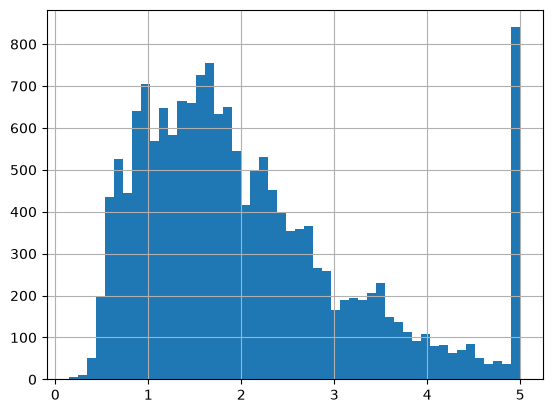

y 的最大值： 5.00001   等於最大值的筆數： 786 （4.8%）


In [2]:
# 觀察：目標值 y 的上限是 5（十萬美元）—— 不論真實房價是 50 萬、60 萬還是更高，都被記成 5.00001（右尾一根高柱）。
#   訓練集有 786 筆（4.8%）剛好是 5.00001：這是「截斷」（censoring），不是真的有一堆房子剛好 50 萬（TODO 1 (1)）。
y_train.hist(bins=50)
plt.show()
print("y 的最大值：", y_train.max(), "  等於最大值的筆數：", int((y_train == y_train.max()).sum()),
      f"（{(y_train == y_train.max()).mean():.1%}）")


In [3]:
# 觀察：變數全部都是連續型變數（float64），沒有缺值 → 不需要補值或類別編碼。
X_train.info()


<class 'pandas.DataFrame'>
Index: 16512 entries, 14196 to 15795
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      16512 non-null  float64
 1   HouseAge    16512 non-null  float64
 2   AveRooms    16512 non-null  float64
 3   AveBedrms   16512 non-null  float64
 4   Population  16512 non-null  float64
 5   AveOccup    16512 non-null  float64
 6   Latitude    16512 non-null  float64
 7   Longitude   16512 non-null  float64
dtypes: float64(8)
memory usage: 1.1 MB


In [4]:
# 觀察：變數的尺度差異極大（Population ~10³、AveBedrms ~1），梯度下降時下降方向會被尺度較大的變數主導，
#   導致收斂的步數變多或時間變長（3B 驗證）。
#   AveRooms 的最大值有 141.9 間、AveBedrms 有 25.6 間，不能說不合理，但這種極端值會把平均直接帶偏；
#   這些樣本可能是 outliers，也許該適度處理，但需要先判斷誰是 outlier（下一格、TODO 1 (2)）。
X_train.describe().T


,count,mean,std,min,25%,50%,75%,max
MedInc,16512.0,3.880754,1.904294,0.499900,2.566700,3.545800,4.773175,15.000100
HouseAge,16512.0,28.608285,12.602499,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,16512.0,5.435235,2.387375,0.888889,4.452055,5.235874,6.061037,141.909091
AveBedrms,16512.0,1.096685,0.433215,0.333333,1.006508,1.049286,1.100348,25.636364
Population,16512.0,1426.453004,1137.056380,3.000000,789.000000,1167.000000,1726.000000,35682.000000
AveOccup,16512.0,3.096961,11.578744,0.692308,2.428799,2.817240,3.280000,1243.333333
Latitude,16512.0,35.643149,2.136665,32.550000,33.930000,34.260000,37.720000,41.950000
Longitude,16512.0,-119.582290,2.005654,-124.350000,-121.810000,-118.510000,-118.010000,-114.310000


In [5]:
# 觀察：與 label 相關最高的是 MedInc（0.69），其餘都 < 0.16（AveRooms 0.158、Latitude −0.143）。
#   單變量相關係數只看「一次只看一個特徵」的線性關係；多元回歸的係數可能跟它方向相反（TODO 4 (3)）。
X_train.assign(label=y_train).corr().sort_values(by="label", ascending=False)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,label
label,0.690647,0.103706,0.158485,-0.051351,-0.026032,-0.022030,-0.142983,-0.046349,1.000000
MedInc,1.000000,-0.121711,0.336013,-0.072550,0.004122,0.022061,-0.076571,-0.017040,0.690647
AveRooms,0.336013,-0.160892,1.000000,0.836163,-0.073733,-0.004922,0.110695,-0.029339,0.158485
HouseAge,-0.121711,1.000000,-0.160892,-0.087983,-0.292283,0.016245,0.005296,-0.101818,0.103706
AveOccup,0.022061,0.016245,-0.004922,-0.006035,0.072330,1.000000,0.005837,-0.000598,-0.022030
Population,0.004122,-0.292283,-0.073733,-0.071267,1.000000,0.072330,-0.102499,0.094276,-0.026032
Longitude,-0.017040,-0.101818,-0.029339,0.016647,0.094276,-0.000598,-0.924485,1.000000,-0.046349
AveBedrms,-0.072550,-0.087983,0.836163,1.000000,-0.071267,-0.006035,0.073161,0.016647,-0.051351
Latitude,-0.076571,0.005296,0.110695,0.073161,-0.102499,0.005837,1.000000,-0.924485,-0.142983


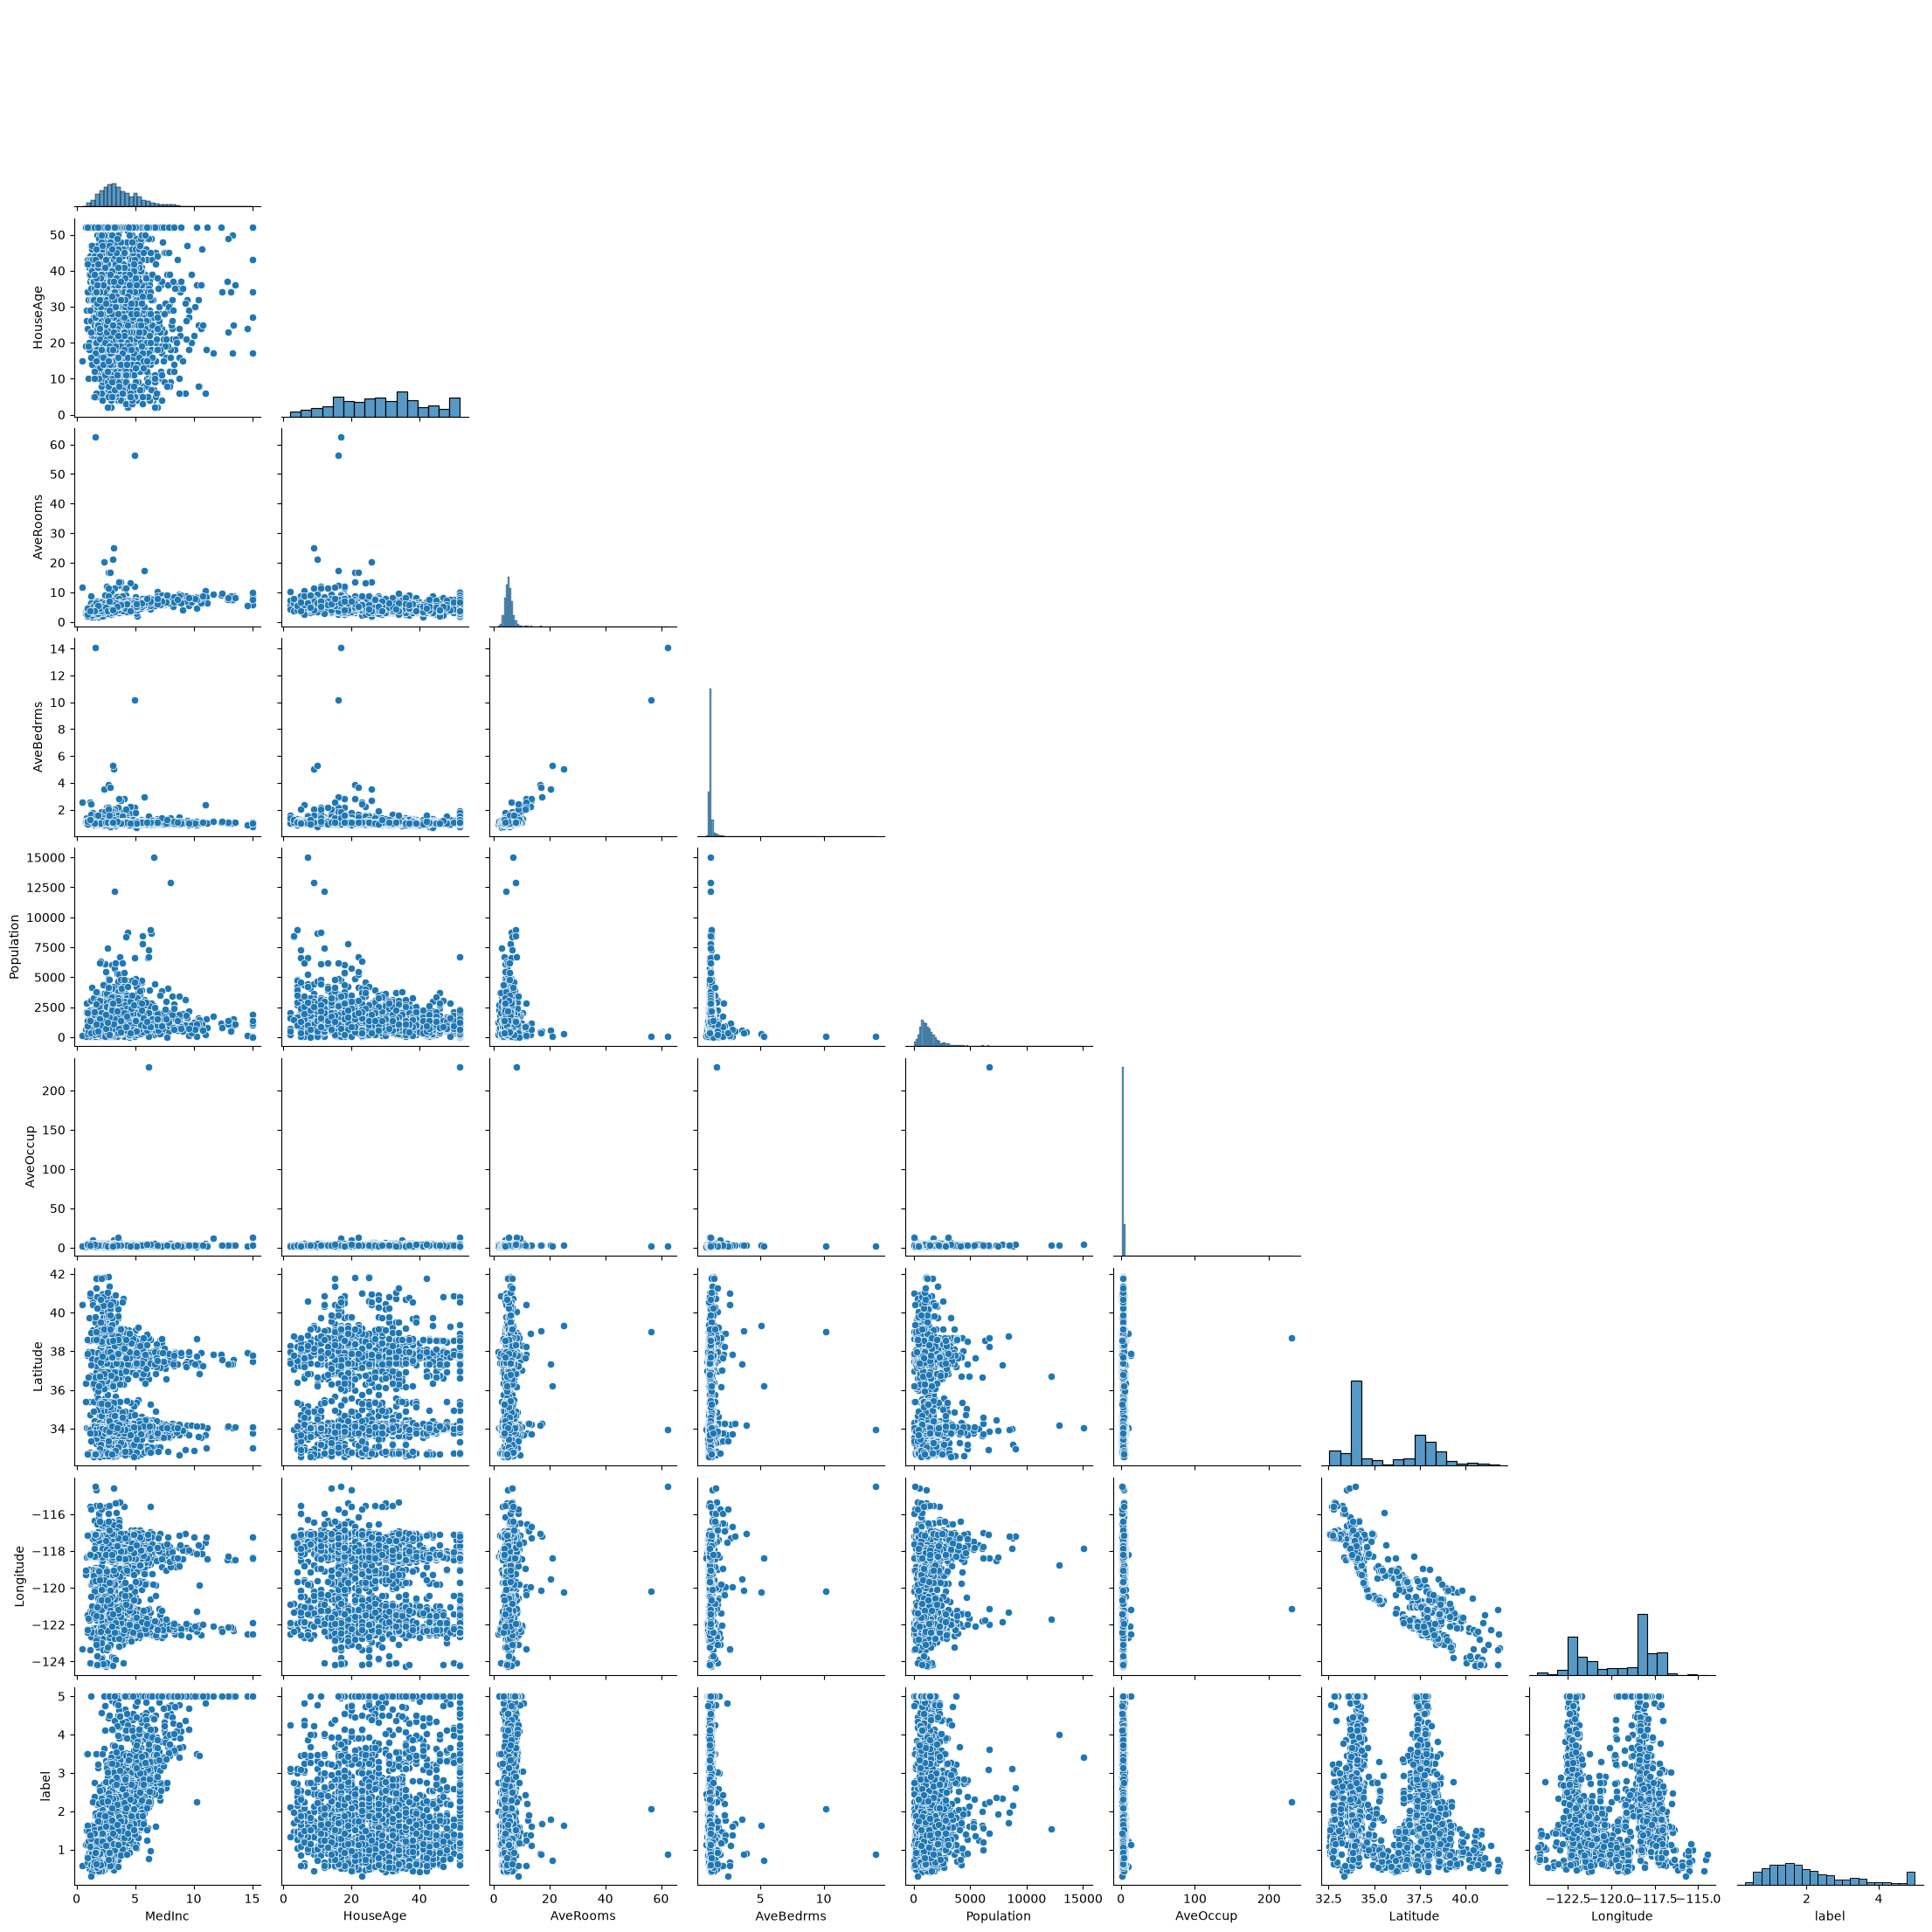

In [6]:
# 觀察：AveRooms、AveBedrms 的相關係數高達 0.836，已經是高度共線性了：
#   實務上可能導致梯度下降收斂變慢，對閉式解則會讓係數估計不穩定（TODO 4 (3)、TODO 10）。
#   Latitude、Longitude 的相關係數也很高（−0.92），是負相關。
sns.pairplot(X_train.assign(label=y_train).sample(2000, random_state=42), corner=True)
plt.show()


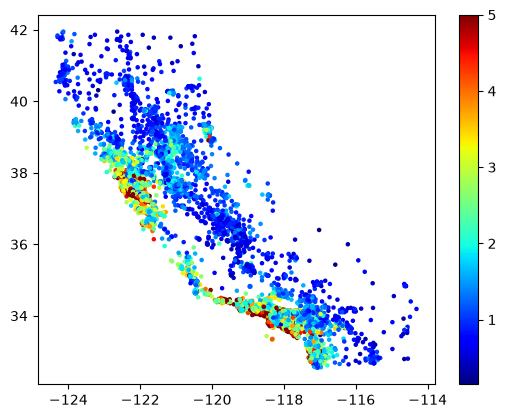

In [7]:
# 觀察：剛好是加州的形狀，可以看出靠海的房子房價越高（舊金山灣區、洛杉磯一帶）。
#   但對線性模型來說只有 w₁·lat + w₂·lon 一個平面：模型並不知道是否靠海，只能表達「緯度越低、經度越往西房價越高」
#   這種單一方向的趨勢（TODO 1 (3)、第 5 節用多項式特徵驗證）。
scatter = plt.scatter(train["Longitude"], train["Latitude"], c=train["label"], cmap="jet", s=5)
plt.colorbar(scatter)
plt.show()


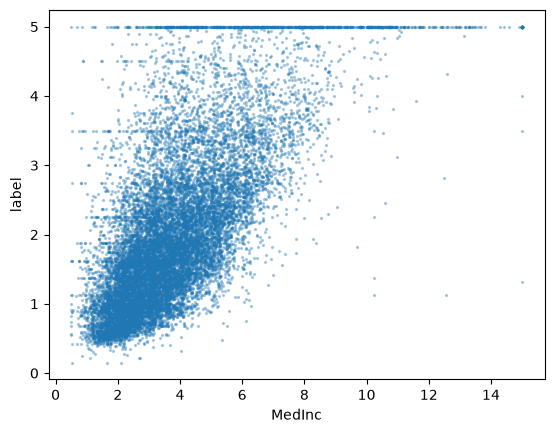

In [8]:
# 觀察：MedInc 與 label 大致正相關，但上方 y = 5 有一條水平線（截斷），4.5、3.5 附近也看得出可能有水平線
#   （原始資料在整數價位的堆積）。MedInc 高時 y 被 5 壓住 → 關係在右上角「彎平」，不是直線。
plt.scatter(train["MedInc"], train["label"], s=2, alpha=0.3)
plt.xlabel("MedInc")
plt.ylabel("label")
plt.show()


In [9]:
# 長尾與極端值
# 觀察：AveRooms、AveBedrms、AveOccup 的偏態（skew）是 18.6、23.2、88.1，Population 也有 5.3（常態分布 = 0）。
#   極端值不是「稍微大一點」：AveOccup 的 99 百分位是 5.4 人／戶，最大值卻是 1,243（≈ 230 倍）；
#   AveRooms 最大值是 99 百分位的 14 倍。這幾個街區多半是度假屋、宿舍、監獄之類的特殊地點。
#   取 log1p 之後偏態大幅下降（AveOccup 88 → 4.3、AveRooms 18.6 → 1.3）→ 第 5 節把「要不要取 log」當成超參數。
SKEWED = ["AveRooms", "AveBedrms", "Population", "AveOccup"]
q = X_train.quantile([0.5, 0.99]).T
tail = q.assign(
    max=X_train.max(),
    max_over_p99=X_train.max() / q[0.99],
    skew=X_train.skew(),
    skew_after_log1p=np.log1p(X_train[SKEWED]).skew(),
)
display(tail.round(2))

,0.5,0.99,max,max_over_p99,skew,skew_after_log1p
MedInc,3.55,10.58,15.00,1.42,1.63,NaN
HouseAge,29.00,52.00,52.00,1.00,0.06,NaN
AveRooms,5.24,10.32,141.91,13.75,18.61,1.34
AveBedrms,1.05,2.12,25.64,12.11,23.17,8.66
Population,1167.00,5798.72,35682.00,6.15,5.28,-1.03
AveOccup,2.82,5.41,1243.33,229.81,88.05,4.26
Latitude,34.26,40.65,41.95,1.03,0.46,NaN
Longitude,-118.51,-116.31,-114.31,0.98,-0.29,NaN


### TODO 1（問答）EDA 小結

> **(1)** y 被截斷在 5：
>
> **(a)** 有幾筆、佔多少比例是 5.00001？
>
> **(b)** 線性模型最小化 MSE，會盡量讓「平均」預測對。這些樣本真實房價其實 ≥ 50 萬，標籤卻被壓低成 50 萬 —— 預期模型在高價區會高估還是低估？
>
> **(c)** 先寫下你的預測：這會在殘差圖（第 7 節）上留下什麼形狀？

**(a)** 786 筆（4.8%）恰為 5.00001。

**(b)** **低估**。高價街區的特徵（MedInc 高、靠海）指向「比 50 萬還貴」，但它們的標籤被壓成 5，模型為了把這些樣本的誤差平方降低，會把高價區的整體斜率往下拉 —— 不只截斷樣本本身，連附近其他高價樣本也會被拉低。

- 截斷（censoring）≠ 雜訊：雜訊是隨機的、平均為 0；截斷是**有方向的偏差**（真值一定 ≥ 標籤），MSE 無法自己修正。

**補充：實務上怎麼處理截斷的 y**

先釐清名詞：這裡的情況統計上叫**右設限（right-censoring）／頂碼（top-coding）**：樣本還在，只是只知道真值 $y^* \ge 5$。另一種叫 **truncation**：超過 5 的街區整筆不在資料裡，連「有這筆」都不知道。中文常把兩者都叫「截斷」，但處理方法不同；以下講的是 censoring。

核心想法：截斷樣本提供的不是「$y = 5$」，而是「$y^* \ge 5$」這個**不等式**。好的方法要把它當不等式用 —— 不是當等式用（目前的做法），也不是丟掉。

| 做法 | 怎麼做 | 優點 | 問題 |
| --- | --- | --- | --- |
| ① 照常訓練（本章做法） | 把 5.00001 當真值 | 簡單 | 高價區系統性低估（本題） |
| ② 刪掉 y = 5 的樣本 | 只用 $y < 5$ 訓練 | 簡單 | **沒修好，只是換一種偏差**：依 y 挑樣本 = 把 censoring 變成 truncation，高價區只剩「剛好沒破 5」的街區 → 還是低估；而且測試時這種街區照樣會出現 |
| ③ 預測時 clip | `np.minimum(y_hat, 5.00001)` | 以「記錄值」評分時，RMSE 只會變好不會變差 | 治標：只修超過上限的預測，被拉低的斜率沒修 |
| ④ Tobit（censored regression） | MLE，截斷樣本用 $P(y^* \ge 5)$ 進似然函數 | 直接估計真值的 $E[y^* \mid x]$ | 要假設誤差分布（常態、同質變異） |
| ⑤ 分位數回歸（CLAD） | 改最小化絕對誤差／pinball loss | 不必假設分布 | 預測的是中位數不是平均；某區截斷比例 > 50% 時失效 |
| ⑥ 存活分析的 AFT 模型 | y 當成「存活時間」、截斷當成「右設限」 | 工具現成，可搭配樹模型 | 換套件、多一組超參數 |
| ⑦ 兩段式模型 | 分類器預測 $P(y \ge 5 \mid x)$ ＋ 回歸器只在 $y < 5$ 上訓練 | 「是不是高價街區」本身常就是業務問題 | 回歸那段有 ② 的偏差；兩個輸出要合起來解讀 |

**④ Tobit**（最經典；第 7B 節有手寫實作與實驗）：假設潛在真值 $y^* = w \cdot x + b + \varepsilon$、$\varepsilon \sim N(0, \sigma^2)$，觀察到的是 $y = \min(y^*, c)$，$c = 5$。記 $\hat y_i = w \cdot x_i + b$，似然函數依樣本分兩種：

$$\log L = \sum_{y_i < c} \log\left[\frac{1}{\sigma}\,\phi\!\left(\frac{y_i - \hat y_i}{\sigma}\right)\right] + \sum_{y_i = c} \log\left[1 - \Phi\!\left(\frac{c - \hat y_i}{\sigma}\right)\right]$$

- 未截斷樣本：跟 OLS 一樣（常態密度取 log ⇔ 平方誤差）。
- 截斷樣本：只要求「$y^*$ 超過 5 的機率」夠高 —— 預測 7 幾乎不被罰，預測 3 才被重罰，正好就是「$y^* \ge 5$」這個不等式。
- 沒有閉式解：用 `scipy.optimize.minimize` 對 $(w, b, \log\sigma)$ 最小化 $-\log L$ 即可（sklearn 沒有內建；statsmodels 可用 `GenericLikelihoodModel` 自己寫）。
- 預測要分清楚：$w \cdot x + b$ 是**真實房價**的估計（可以 > 5）；若要預測「資料會記成多少」，要用 $E[\min(y^*, c) \mid x]$。

**⑤ 為什麼分位數不怕截斷**：分位數跟單調函數可以交換順序，$Q_\tau(\min(y^*, c) \mid x) = \min(Q_\tau(y^* \mid x),\, c)$。只要某個 $x$ 附近被截斷的樣本不到一半，中位數就完全不受影響；平均則不然 —— 一筆 80 萬被記成 50 萬，平均就被拉低。跟 TODO 2 (2) 同一件事：平均對尾巴敏感，中位數不敏感。（Powell 的 CLAD 就是這個想法：最小化 $\sum_i |y_i - \min(\hat y_i, c)|$。）

**⑥ AFT 與工具**：房價跟存活時間一樣是正值、右偏、會被右設限，存活分析的工具可以直接借用：

- `lifelines` 的 `LogNormalAFTFitter`：等於「對 $\log y$ 做 Tobit」，順便處理異質變異（TODO 17 (2)）。
- XGBoost `objective="survival:aft"`：標籤給成區間，未截斷樣本 $[y_i, y_i]$、截斷樣本 $[5, +\infty)$ —— 樹模型也能用上截斷資訊。

**評估也要跟著改**：截斷樣本的真值未知，RMSE 在它們身上算出來的誤差本身就不準。常見做法是分開報告（第 7 節的「非截斷樣本 RMSE」），或用設限版的誤差（真值是 5 時，預測 ≥ 5 就算對）。

**怎麼選**：先問目標是什麼。

- 要預測「資料裡會記成多少」（例如跟同一份資料的其他模型比分數）→ 照常訓練 ＋ clip 就夠，不一定要修正。
- 要估計「真實房價」或解讀係數（例如收入多 1 萬、房價漲多少）→ Tobit／AFT。
- 只在乎「是不是高價街區」→ 直接做分類。
- 本資料只有 4.8% 被截斷：對整體 RMSE 影響有限，但它們全集中在高價區，對高價區的預測與係數解讀影響很大。
- 第 7B 節的實測結果：刪除截斷樣本在三個實驗中都沒有修正偏差；Tobit 讓 MedInc 係數 +18%、人工截斷實驗追回七到八成差距；只看記錄值的 RMSE 時，clip 就拿到幾乎全部的改善（TODO 18–20）。

**(c)** 殘差 = 實際 − 預測。實際固定為 5，所以殘差 $= 5 - \hat y$：對 $\hat y$ 作圖會是一條**斜率 −1 的直線**（TODO 17 (2) 驗證）。

> **(2)** 長尾與極端值（上一格）：
>
> **(a)** AveOccup 的最大值是 99 百分位的幾倍？取 log1p 後偏態從多少降到多少？
>
> **(b)** 線性模型的預測是 $\hat y = w \cdot x + b$，對 $x$ 沒有上限。一個 AveOccup = 1243 的樣本，就算 $w$ 很小，$w \cdot x$ 會怎樣？如果再加上 $x^2$、$x^3$ 這種多項式特徵呢？
>
> **(c)** 哪一種前處理能讓極端值「不那麼極端」，同時保留大小順序？

**(a)** 約 230 倍（5.4 → 1,243）。偏態 88.1 → 4.3；AveRooms 18.6 → 1.3、AveBedrms 23.2 → 8.7、Population 5.3 → −1.0。

**(b)** 線性項：$w \cdot 1243$ 是一般樣本（約 3）的 400 倍，一個小係數就能讓這筆的預測偏很多；而且 MSE 對誤差取平方，模型為了遷就這幾筆，會把係數往奇怪的方向扭（高槓桿點，leverage）。

多項式：$1243^2 \approx 1.5\times10^6$、$1243^3 \approx 1.9\times10^9$，比一般樣本大好幾個數量級。訓練時若某個 fold 沒看過這麼極端的值，係數在那個方向幾乎沒被約束 → 遇到它時預測可能飛到幾十、幾百（外插，extrapolation）。（第 5 節 TODO 13 驗證：二次多項式的某個 fold 有樣本被預測成 240，真值只有 1.4。）

**(c)** **取 log**（`np.log1p`，加 1 避免 log 0）：單調遞增 → 大小順序不變；但把「乘法尺度」壓成「加法尺度」，1,243 變成 7.1、5.4 變成 1.9。其他做法：截尾（clip 在某個百分位）、`QuantileTransformer`。

- 標準化（StandardScaler）**不能**解決：它只是平移＋縮放，形狀不變，極端值標準化後仍然極端（AveOccup 的 1243 會變成約 100 個標準差）。

> **(3)** 經緯度地圖：高價區集中在海岸邊的幾個聚落。線性模型 $w_1 \cdot \text{lat} + w_2 \cdot \text{lon}$ 能表達「靠海」嗎？預期線性回歸是過擬合還是欠擬合？

不能。$w_1 \cdot \text{lat} + w_2 \cdot \text{lon}$ 在地圖上是一個**傾斜的平面**：只能表達「往某個方向越走越貴」。海岸線是彎的、高價區是幾個分散的聚落（灣區、洛杉磯、聖地牙哥），要用平面同時貼合它們不可能。

- → 預期**欠擬合**（高偏差）：8 個特徵、16,512 筆資料，模型太簡單而不是太複雜；train 與 validation 的誤差會很接近、而且都偏高（第 5 節 TODO 12 驗證）。
- 改善方向：讓模型能表達曲面（多項式／交互作用項，第 5 節），或直接做「到海岸的距離」這類特徵（待補強）。


---
## 2. Baseline

最笨的回歸模型：**不看 $x$，永遠預測同一個數字**（`DummyRegressor`）。

- `strategy="mean"`：預測訓練集 y 的平均
- `strategy="median"`：預測訓練集 y 的中位數

指標（整章共用）：
- **RMSE**：主要指標，跟訓練目標 MSE 同一族、單位與 y 相同（十萬美元）
- **MAE**：平均絕對誤差，對少數大誤差較不敏感
- **$R^2$**：$1 - \text{SSE}/\text{SST}$，「比永遠猜平均好多少」

#### 本節名詞與公式

$e_i = y_i - \hat y_i$ 是第 $i$ 筆的誤差，$n$ 是評估的筆數：

| 指標 | 公式 | 單位 |
| --- | --- | --- |
| MAE | $\frac{1}{n}\sum_i \lvert e_i\rvert$ | 跟 $y$ 相同 |
| RMSE | $\sqrt{\frac{1}{n}\sum_i e_i^2}$（MSE 開根號） | 跟 $y$ 相同 |
| SSE | $\sum_i e_i^2$：模型的平方誤差總和 | $y^2$ |
| SST | $\sum_i (y_i - \bar y)^2$：「永遠猜平均」的平方誤差總和 | $y^2$ |
| $R^2$ | $1 - \text{SSE}/\text{SST}$ | 沒有單位 |

- **5-fold CV**（`KFold(n_splits=5, shuffle=True, random_state=42)`）：訓練集打亂後切成 5 份（fold），輪流拿 1 份當驗證、其餘 4 份訓練，得到 5 個分數，報告成「平均 ± 標準差」。回歸問題沒有類別，所以不用分層。
- `cv_summary`：本章自訂的小函數，把 5 個 fold 的 RMSE、MAE、$R^2$ 整理成「平均 ± 標準差」，並把 sklearn 的負值轉回正值。

In [10]:
from sklearn.base import BaseEstimator
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

# 整章共用的 5-fold（打亂、固定 seed），所有 CV 分數才能互相比較
cv = KFold(n_splits=5, shuffle=True, random_state=42)
SCORING = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}


def cv_summary(
    model: BaseEstimator, X: pd.DataFrame = X_train, y: pd.Series = y_train
) -> dict[str, str]:
    """5-fold CV。回傳 {"rmse": "平均 ± 標準差", "mae": ..., "r2": ...}；rmse、mae 已轉回正值（越低越好）。"""
    s = cross_validate(model, X, y, cv=cv, scoring=SCORING)
    out = {}
    for k in SCORING:
        v = s[f"test_{k}"] * (1 if k == "r2" else -1)
        out[k] = f"{v.mean():.4f} ± {v.std():.4f}"
    return out


baseline = pd.DataFrame(
    {
        "Dummy mean": cv_summary(DummyRegressor(strategy="mean")),
        "Dummy median": cv_summary(DummyRegressor(strategy="median")),
    }
).T
display(baseline)
print(
    "y_train：平均",
    round(float(y_train.mean()), 4),
    "  中位數",
    round(float(y_train.median()), 4),
    "  標準差（ddof=0）",
    round(float(y_train.std(ddof=0)), 4),
)

,rmse,mae,r2
Dummy mean,1.1562 ± 0.0122,0.9139 ± 0.0101,-0.0002 ± 0.0002
Dummy median,1.1878 ± 0.0128,0.8860 ± 0.0092,-0.0557 ± 0.0068


y_train：平均 2.0719   中位數 1.7985   標準差（ddof=0） 1.1562


### TODO 2（問答，補寫）

> **(1)** Dummy mean：
>
> **(a)** 它的 RMSE 跟 y_train 的哪一個統計量幾乎一樣？$R^2$ 是多少？
>
> **(b)** 定義：$R^2 = 1 - \dfrac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$。把 $\hat y_i = \bar y$ 代進去會得到多少？
>
> **(c)** 那為什麼 CV 的 $R^2$ 是「略小於 0」（−0.0002），而不是剛好 0？

**(a)** RMSE 1.1562 $\approx$ y_train 的標準差 1.1562；$R^2 \approx 0$。

**(b)** 分子與分母一模一樣 → $R^2 = 0$。

- 同理 $\text{RMSE} = \sqrt{\frac{1}{n}\sum(y_i - \bar y)^2}$ 正好是 y 的（母體）標準差 —— 「永遠猜平均」的誤差就是 y 本身的散布程度。
- 所以 $R^2$ 的意思是「比永遠猜平均，把平方誤差降低了幾成」；$R^2 = 0.6 \Leftrightarrow$ MSE 只剩 baseline 的 40%。

**(c)** CV 時，Dummy 猜的是「訓練 fold」的平均，評分卻用「驗證 fold」：$R^2$ 的分母用的是驗證 fold 自己的平均 $\bar y_\text{val}$，而預測值是 $\bar y_\text{train} \ne \bar y_\text{val}$，所以分子一定 $\ge$ 分母，$R^2 \le 0$。

- 推論：**$R^2$ 可以是負的**（測試集上比「猜測試集平均」還差），不是 0–1 之間的比例。

> **(2)** Dummy median 的 MAE 比 mean 好（0.886 vs 0.914），RMSE 卻比較差（1.188 vs 1.156）。為什麼兩個指標的結論相反？（提示：哪一個常數讓 $\sum (y_i - c)^2$ 最小？哪一個讓 $\sum |y_i - c|$ 最小？）

- $\sum (y_i - c)^2$ 對 $c$ 微分 $= -2\sum(y_i - c) = 0$ → $c = \bar y$：**平均**是平方誤差最小的常數。
- $\sum |y_i - c|$ 對 $c$ 的（次）梯度 $= (\#\{y_i < c\}) - (\#\{y_i > c\})$，等於 0 時 $c$ 左右各一半 → **中位數**是絕對誤差最小的常數。
- 兩個 Dummy 各自在「自己的指標」上最佳，所以結論相反。y 右偏（平均 2.07 > 中位數 1.80，又有截斷在 5 的長尾），兩者差得夠多，指標差異才看得出來。

**推論**：

- 選指標 = 選「要最小化哪一種誤差」：MSE／RMSE 對大誤差特別敏感（平方），MAE 對每一筆一視同仁。
- 線性回歸最小化 MSE，所以它的預測是條件**平均** $E[y \mid x]$；想要條件中位數要換 loss（quantile regression，待補強）。
- 這個差異在第 5 節會再出現：多項式模型的 MAE 變好、RMSE 卻爆掉（TODO 13）。


---
## 3. 手寫模型

### 3A. 正規方程（Normal Equation）

最小化 $\lVert Xw - y\rVert^2$，對 $w$ 微分令其為 0 →

$$w = (X^\top X)^{-1} X^\top y$$

#### 符號表（第 3 節通用）

| 符號 | 意義 | shape | 程式裡 |
| --- | --- | --- | --- |
| $n$、$d$ | 樣本數、特徵數（16,512、8） | 純量 | `n`、`X.shape[1]` |
| $X$ | 特徵矩陣（3 節用標準化後的 `X_train_s`） | $(n, d)$ | `X` |
| $X_b$ | 在 $X$ 左邊補一欄 1 | $(n, d + 1)$ | `Xb = add_bias(X)` |
| $\theta$ | 係數向量 $(b, w_1, \dots, w_d)$：第 0 個是 bias | $(d + 1,)$ | `theta`；拆成 `self.b_ = theta[0]`、`self.w_ = theta[1:]` |
| $y$ | 目標值 | $(n,)$ | `y` |
| $\hat y$ | 預測 $X_b\theta$（$= Xw + b$） | $(n,)$ | `y_hat` |
| $A$、$c$ | 正規方程的係數矩陣 $X_b^\top X_b$ 與右邊 $X_b^\top y$ | $(d + 1, d + 1)$、$(d + 1,)$ | `Xb.T @ Xb`、`Xb.T @ y` |
| $\kappa$（kappa） | 條件數：$A$ 最大特徵值 ÷ 最小特徵值，衡量「方程式有多難解得準」（定義見 TODO 4 下面的補充） | 純量 | `np.linalg.cond(A)` |

**為什麼補一欄 1**：$x_i \cdot w + b = (1, x_i) \cdot (b, w)$ —— 把 $b$ 當成「乘上常數 1 的那個權重」，bias 就不用另外處理，所有參數都在 $\theta$ 裡。

**推導**（對照前置複習 3）：loss $= \lVert X_b\theta - y\rVert^2$，梯度 $= 2X_b^\top(X_b\theta - y)$。令梯度為 0：

$$X_b^\top X_b\,\theta = X_b^\top y \quad\Longleftrightarrow\quad A\theta = c$$

這組 $d + 1$ 條方程式叫**正規方程**（normal equation）。$A$ 可逆時 $\theta = A^{-1}c$，就是上面的 $(X^\top X)^{-1}X^\top y$（上式的 $X$、$w$ 指含 bias 的 $X_b$、$\theta$）。

建議先在紙上推一次再寫。

#### 最小例子：TODO 3（正規方程）

3 筆資料、1 個特徵，剛好落在直線 $y = 1 + 2x$ 上：$x = (1, 2, 3)$、$y = (3, 5, 7)$，所以答案一定是 $\theta = (b, w) = (1, 2)$。

1. **正確答案**：用迴圈逐元素算出 $A = X_b^\top X_b$（$A_{jk} = \sum_i X_{b,ij}X_{b,ik}$）與 $c = X_b^\top y$（$c_j = \sum_i X_{b,ij}\,y_i$），再用 2×2 的克拉瑪公式解 $A\theta = c$。
2. **矩陣寫法的積木**：`add_bias`（`np.c_`）、`Xb.T`、`Xb.T @ Xb`、`Xb.T @ y`，逐步印出 shape。
3. **留給你**：用哪個函數一行解出 $\theta$？

In [11]:
# 最小例子：TODO 3（正規方程）
import numpy as np

X_mini = np.array([[1.0], [2.0], [3.0]])  # (n=3, d=1)
y_mini = np.array([3.0, 5.0, 7.0])  # (3,)，= 1 + 2x

# ---- 1. 正確答案：逐元素 + 克拉瑪公式 ----
Xb_loop = [[1.0, X_mini[i, 0]] for i in range(3)]  # 每列前面補 1
A_loop = [[sum(Xb_loop[i][j] * Xb_loop[i][k] for i in range(3)) for k in range(2)] for j in range(2)]
c_loop = [sum(Xb_loop[i][j] * y_mini[i] for i in range(3)) for j in range(2)]
det_mini = A_loop[0][0] * A_loop[1][1] - A_loop[0][1] * A_loop[1][0]
theta_loop = [
    (c_loop[0] * A_loop[1][1] - A_loop[0][1] * c_loop[1]) / det_mini,
    (A_loop[0][0] * c_loop[1] - A_loop[1][0] * c_loop[0]) / det_mini,
]
print("A = XbᵀXb =", np.array(A_loop).tolist(), "  c = Xbᵀy =", np.array(c_loop).tolist())
print("正確答案：θ = (b, w) =", np.array(theta_loop).tolist())

# ---- 2. 矩陣寫法的積木 ----
Xb_mini = np.c_[np.ones(len(X_mini)), X_mini]
print("\nXb       ", Xb_mini.shape, "\n", Xb_mini)
print("Xb.T     ", Xb_mini.T.shape)
print("Xb.T @ Xb", (Xb_mini.T @ Xb_mini).shape, "\n", Xb_mini.T @ Xb_mini, "← 應等於 A_loop")
print("Xb.T @ y ", (Xb_mini.T @ y_mini).shape, Xb_mini.T @ y_mini, "← 應等於 c_loop")

# ---- 3. 留給你 ----
# 問題：手上有 A (2, 2) 與 c (2,)，用 np.linalg 的哪個函數一行解出 θ？結果應等於 theta_loop。
# 寫完 TODO、執行過下一格之後，取消下面的註解來對照（應印出 1.0 [2.]）：
# m_mini = LinearRegressionNE().fit(X_mini, y_mini)
# print(m_mini.b_, m_mini.w_)

A = XbᵀXb = [[3.0, 6.0], [6.0, 14.0]]   c = Xbᵀy = [15.0, 34.0]
正確答案：θ = (b, w) = [1.0, 2.0]

Xb        (3, 2) 
 [[1. 1.]
 [1. 2.]
 [1. 3.]]
Xb.T      (2, 3)
Xb.T @ Xb (2, 2) 
 [[ 3.  6.]
 [ 6. 14.]] ← 應等於 A_loop
Xb.T @ y  (2,) [15. 34.] ← 應等於 c_loop


In [12]:
from typing import Self
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.typing import ArrayLike
from sklearn.preprocessing import StandardScaler
from learning_map.data import load_california_housing
from learning_map.metrics import regression_metrics

X_train, X_test, y_train, y_test = load_california_housing()
feature_names = X_train.columns.tolist()

# 只用訓練集 fit scaler，再套到測試集（避免資料洩漏）
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)


def add_bias(X: ArrayLike) -> np.ndarray:
    """在 X 最左邊補一欄 1，讓 bias 變成係數向量的第 0 個元素。X (n, d) → (n, d + 1)。"""
    X = np.asarray(X, dtype=float)
    return np.c_[np.ones(len(X)), X]


class LinearRegressionNE:
    """用正規方程一步求解。"""

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,)。學到 w_ (d,) 與 b_，回傳 self。"""
        Xb = add_bias(X)
        y = np.asarray(y, dtype=float)
        # TODO 3（程式）：解 (Xbᵀ Xb) θ = Xbᵀ y 得到 θ（長度 = 特徵數 + 1）
        #   - 用 np.linalg.solve(A, b)，不要用 np.linalg.inv（想想為什麼；說明與實驗見 TODO 4 後的補充）
        #   - θ[0] 是 bias，θ[1:] 是各特徵權重
        theta = np.linalg.solve(Xb.T @ Xb, Xb.T @ y)
        self.b_ = theta[0]
        self.w_ = theta[1:]
        return self

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的預測值。"""
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

In [13]:
# 實驗：raw vs 標準化
ne_raw = LinearRegressionNE().fit(X_train, y_train)
ne_s = LinearRegressionNE().fit(X_train_s, y_train)

print("raw    train:", regression_metrics(y_train, ne_raw.predict(X_train)))
print("scaled train:", regression_metrics(y_train, ne_s.predict(X_train_s)))
print("兩者預測值最大差異：", np.abs(ne_raw.predict(X_train) - ne_s.predict(X_train_s)).max(),
      "（數學上相同；應 < 1e-6，差異來自 raw 的條件數）")
theta_ref = np.linalg.lstsq(add_bias(X_train_s), y_train.to_numpy(), rcond=None)[0]  # SVD 解，當標準答案
print("✅ 正規方程 vs np.linalg.lstsq 的最大差異（scaled）：",
      np.abs(np.r_[ne_s.b_, ne_s.w_] - theta_ref).max(), "（應 < 1e-10）")

coef = pd.DataFrame({"raw": ne_raw.w_, "scaled": ne_s.w_}, index=feature_names)
coef.loc["(bias)"] = [ne_raw.b_, ne_s.b_]
display(coef.round(4))

Xb_raw, Xb_s = add_bias(X_train), add_bias(X_train_s)
print(f"XᵀX 條件數 raw   ：{np.linalg.cond(Xb_raw.T @ Xb_raw):.3e}")
print(f"XᵀX 條件數 scaled：{np.linalg.cond(Xb_s.T @ Xb_s):.3e}")

raw    train: {'mae': 0.5286, 'rmse': 0.7197, 'r2': 0.6126, 'mape': 31.502}
scaled train: {'mae': 0.5286, 'rmse': 0.7197, 'r2': 0.6126, 'mape': 31.502}
兩者預測值最大差異： 1.1221779061543202e-09 （數學上相同；應 < 1e-6，差異來自 raw 的條件數）
✅ 正規方程 vs np.linalg.lstsq 的最大差異（scaled）： 2.7977620220553945e-14 （應 < 1e-10）


,raw,scaled
MedInc,0.4487,0.8544
HouseAge,0.0097,0.1225
AveRooms,-0.1233,-0.2944
AveBedrms,0.7831,0.3393
Population,-0.0000,-0.0023
AveOccup,-0.0035,-0.0408
Latitude,-0.4198,-0.8969
Longitude,-0.4337,-0.8698
(bias),-37.0233,2.0719


XᵀX 條件數 raw   ：5.642e+10
XᵀX 條件數 scaled：4.283e+01


#### 先定義：TODO 4 用到的「條件數」與「共線性」

- **條件數** $\kappa$：對方陣 $A$（這裡是 $X_b^\top X_b$），$\kappa = \lambda_{\max}/\lambda_{\min}$，最大與最小**特徵值**的比。直覺：解 $A\theta = c$ 時，$c$ 的一點點誤差（例如浮點捨入）最多會被放大 $\kappa$ 倍傳到 $\theta$；$\kappa \approx 10^k$ 大約會損失 $k$ 位有效數字。特徵值的定義、$\kappa$ 的算法與實驗都在 TODO 4 下面的「補充：條件數的定義、算法與意義」。
- **共線性**：特徵之間高度相關（前置複習 5），某個特徵幾乎能由其他特徵的線性組合算出來。這時模型很難決定「功勞」該分給誰，係數不穩定。
- **上一格的 `coef` 表**：raw 欄是用原始資料 fit 的 $w$，scaled 欄是用標準化資料 fit 的 $w$；最後一列 `(bias)` 是 $b$。

### TODO 4（問答）

> **(1)** 預測值一樣嗎？係數一樣嗎？為什麼？

預測值幾乎一樣，這個寫法基本上只是矩陣的運算而已，理論上數值會一模一樣，現在看到有差異是因為電腦浮點數或是 solver 的精度導致的，並不是數學上本身有問題。

標準化只是對每一欄做 $x' = (x - \mu) / \sigma$，也就是縮放加平移。線性模型本身就有 $w$ 和 $b$ 可以調，縮放可以被 $w$ 吸收，平移可以被 $b$ 吸收。所以兩種資料能表達的函數完全一樣，最佳解的預測值也就一樣。

係數不一樣，係數之間有精確的換算關係：$w_\text{scaled} = w_\text{raw} \times \sigma$

> **(2)** 條件數差幾個數量級？

raw $\approx 5.6\times10^{10}$、scaled $\approx 4.3\times10^{1}$，差約 9 個數量級。

- 條件數 $\kappa = \lambda_{\max} / \lambda_{\min}$，代表誤差會被放大的倍數（$\kappa \approx 10^k$ 約損失 $k$ 位有效數字）。定義、算法與意義見下方補充。
- raw 的大 $\kappa$ 主要來自特徵尺度差異（Population ~$10^3$ vs AveBedrms ~1），標準化就能修掉；
  上面預測值差了 $10^{-9}$，正是 raw 的大 $\kappa$ 把浮點誤差（~$10^{-16}$）放大的結果。
- 另外 $\kappa(X^\top X) = \kappa(X)^2$，正規方程先算 $X^\top X$ 會把病態程度平方，所以 sklearn 改用 lstsq（SVD）。

> **(3)** AveRooms、AveBedrms 的係數正負號，跟它們和 y 的相關係數（0.158、-0.051）方向一致嗎？用共線性解釋。

兩個都相反：

| 特徵 | 與 y 的相關係數 | 多元回歸係數 |
| --- | --- | --- |
| AveRooms | +0.158 | −0.29 |
| AveBedrms | −0.051 | +0.34 |

- 相關係數只看單一特徵與 y 的關係；多元回歸係數是「其他特徵固定時」該特徵的效果，兩者回答不同問題。
- 兩者相關 0.84，幾乎同進同退，模型難以分辨功勞歸誰，常出現一正一負互相抵消的解，係數也因此不穩定。
  （白話：房間總數固定時，臥室比例越高、客廳等公共空間越少 → 這組係數不宜直接解讀為因果）
- 這是共線性的典型症狀，Ridge（加 $\alpha I$ 墊高 $\lambda_{\min}$）可以讓這組係數變穩定。

### 補充（TODO 4）：條件數的定義、算法與意義

**Notation**（先定義本段用到的符號）：

- **資料矩陣**：以下的 $X$ 泛指一個 $n \times d$ 的矩陣（$n$ 列 = 樣本、$d$ 欄 = 特徵），$x_j$ 是它的第 $j$ 欄。套到本章時 $X$ 就是 $X_b$：8 個特徵再補一欄 bias（全為 1），所以 $d = 9$。（注意：第 3 節程式裡的 `d` 指的是特徵數 8，$X_b$ 是 `d + 1` 欄。）
- **正規方程**：$y$ 是長度 $n$ 的目標向量，$\theta = (b, w_1, \dots, w_8)$ 是要解的係數（長度 9）。正規方程 $X_b^\top X_b\,\theta = X_b^\top y$ 簡寫成
  - $A\theta = c$，其中 $A = X_b^\top X_b$（$9 \times 9$ 的方陣）、$c = X_b^\top y$（長度 9 的向量）。
- **向量長度**：$\lVert v\rVert = \sqrt{\sum_j v_j^2}$（2-範數）；矩陣的 $\lVert A\rVert$ 見下方「定義」。
- **特徵值**（eigenvalue）：方陣 $A$ 若有非零向量 $v$ 滿足 $Av = \lambda v$，$\lambda$ 稱為特徵值、$v$ 稱為對應的特徵向量 —— $A$ 作用在 $v$ 上只把它伸縮 $\lambda$ 倍、不改變方向。
  - $X^\top X$ 是 $d \times d$ 的對稱半正定矩陣：它的 $d$ 個特徵值都是 $\ge 0$ 的實數，特徵向量兩兩正交。依大小排成 $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_d$，$\lambda_i$ 是第 $i$ 大的特徵值。
  - $\lambda_{\max} = \lambda_1$、$\lambda_{\min} = \lambda_d$：$X^\top X$ 最大、最小的特徵值（純量）。
  - $u_{\max}$、$u_{\min}$：$\lambda_{\max}$、$\lambda_{\min}$ 對應的**單位特徵向量**。以 $u_{\min}$ 為例，它是滿足 $X^\top X\, u_{\min} = \lambda_{\min}\, u_{\min}$ 且 $\lVert u_{\min}\rVert = 1$ 的向量（$u_{\max}$ 同理）。
    - 它的長度等於 $X$ 的欄數（本章 $X_b$ 含 bias 共 9 個分量），每個分量對應一個特徵；$X u_{\min} = \sum_j u_{\min, j}\, x_j$ 就是「以 $u_{\min}$ 的分量為權重，把各欄加起來」得到的新特徵。
    - 特徵向量整個乘上 $-1$ 仍是特徵向量，所以正負號只有「分量之間同號或異號」的相對意義。
  - 直觀意義：因為 $v^\top X^\top X v = \lVert Xv\rVert^2$，所以 $\lambda_{\max} = \max_{\lVert v\rVert = 1} \lVert Xv\rVert^2$、$\lambda_{\min} = \min_{\lVert v\rVert = 1} \lVert Xv\rVert^2$。把各特徵用單位向量 $v$ 組合成一個新特徵 $Xv$：$\lambda_{\max}$ 是「變化最大」的組合的平方和，$\lambda_{\min}$ 是「變化最小」的組合的平方和；最大、最小值分別發生在 $v = u_{\max}$、$v = u_{\min}$（$\lVert X u_{\min}\rVert^2 = \lambda_{\min}$）。$\lambda_{\min} = 0$ 代表某個組合恆為 0（完全共線、矩陣奇異）。
- **奇異值**（singular value）：任何形狀的矩陣都有，$\sigma_i(X) = \sqrt{\lambda_i(X^\top X)}$（$i = 1, \dots, d$，一樣由大到小）。所以 $\sigma_{\max}(X) = \max_{\lVert v\rVert=1} \lVert Xv\rVert$、$\sigma_{\min}(X) = \min_{\lVert v\rVert=1} \lVert Xv\rVert$：$X$ 把單位向量拉長最多、最少的倍數。
- TODO 8 的 Hessian 是 $\frac{2}{n} X_b^\top X_b$，特徵值都乘上同一個常數 $\frac{2}{n}$，比值 $\kappa$ 不變；本章的 $\lambda$ 都是指 $X_b^\top X_b$（或它的常數倍）的特徵值，$X_b$ 含 bias 欄。

**定義**：對可逆的方陣 $A$，

$$\kappa(A) = \lVert A\rVert \cdot \lVert A^{-1}\rVert$$

範數用 2-範數（最常見）時，$\lVert A\rVert = \sigma_{\max}(A)$、$\lVert A^{-1}\rVert = 1/\sigma_{\min}(A)$（$\sigma$ 是奇異值，見上方記號）：

$$\kappa(A) = \frac{\sigma_{\max}(A)}{\sigma_{\min}(A)}$$

- 對稱正定矩陣（例如 $X^\top X$）的奇異值就是特徵值，所以 $\kappa(X^\top X) = \lambda_{\max} / \lambda_{\min}$ —— TODO 4、TODO 8 用的就是這個式子。
- 不是方陣的 $X$（$n \times d$）沒有反矩陣，直接用 $\kappa(X) = \sigma_{\max}(X) / \sigma_{\min}(X)$。$X^\top X$ 的特徵值剛好是 $X$ 奇異值的平方，所以 $\kappa(X^\top X) = \kappa(X)^2$（TODO 4 (2)「正規方程把病態程度平方」的來源）。
- $\kappa \ge 1$；$= 1$ 若且唯若各欄互相正交且長度相同。$\kappa = \infty$ 代表奇異（某些欄完全共線）。

**三種算法**（數學上相同）：`np.linalg.svd(X)` 取最大／最小奇異值相除；`np.linalg.eigvalsh(X.T @ X)` 取最大／最小特徵值相除；`np.linalg.cond(A)`（內部也是 SVD）。

**意義一：誤差放大的上界**。解 $A\theta = c$ 時，若 $c$ 有一點誤差 $\delta c$（量測誤差、浮點捨入），解會跟著偏 $\delta\theta = A^{-1}\delta c$：

- $\lVert\delta\theta\rVert \le \lVert A^{-1}\rVert\,\lVert\delta c\rVert = \lVert\delta c\rVert / \lambda_{\min}$（誤差最多被放大 $1/\lambda_{\min}$ 倍）
- $\lVert c\rVert = \lVert A\theta\rVert \le \lambda_{\max} \lVert\theta\rVert$

兩式相除：

$$\frac{\lVert\delta\theta\rVert}{\lVert\theta\rVert} \le \kappa(A)\,\frac{\lVert\delta c\rVert}{\lVert c\rVert}$$

**輸入的相對誤差，到輸出最多放大 $\kappa$ 倍**。浮點數的相對誤差約 $\varepsilon \approx 10^{-16}$，所以 $\kappa \approx 10^k$ 就可能損失 $k$ 位有效數字；$\kappa \gtrsim 1/\varepsilon \approx 4.5\times10^{15}$ 時，數值上等於奇異。注意這是**最壞情況**：要剛好 $c$ 落在最「容易」的方向、$\delta c$ 落在最「敏感」的方向，才會放大到滿 $\kappa$ 倍（下一格實測）。

**意義二：幾何**。$A$ 把單位球變成一個橢球，各軸長是 $\lambda_i$；$\kappa$ 就是最長軸 ÷ 最短軸 ——「矩陣把空間壓扁的程度」。MSE 的等高線也是橢圓，軸長正比於 $1/\sqrt{\lambda_i}$，所以長短軸比是 $\sqrt\kappa$：$\kappa$ 大 = 細長的山谷（TODO 8 (3) 梯度下降慢的原因）。

**意義三：共線性的診斷**。$u_{\min}$ 滿足 $u_{\min}^\top X^\top X\, u_{\min} = \lVert X u_{\min}\rVert^2 = \lambda_{\min}$。$\lambda_{\min}$ 很小，代表「特徵的某個線性組合 $X u_{\min}$ 幾乎是 0」—— 這正是共線性的定義，而 $u_{\min}$ 的各分量直接告訴你是哪幾個特徵在共線。

**$\kappa$ 跟尺度有關**：把某一欄乘 1000（換單位），預測完全不變，$\kappa$ 卻可能大好幾個數量級 → raw 資料的 $\kappa$ 有一大部分是「單位選得不好」，標準化就能消掉；剩下的才是特徵之間真正的共線性。

In [14]:
# 實驗 1：三種算法比對（Xb 含 bias 欄）
kappa_rows = {}
Xb_cases = {"raw": add_bias(X_train), "scaled": add_bias(X_train_s)}
for name, Xb in Xb_cases.items():
    s = np.linalg.svd(Xb, compute_uv=False)  # X 的奇異值，由大到小
    lam = np.linalg.eigvalsh(Xb.T @ Xb)  # XᵀX 的特徵值，由小到大
    kappa_rows[name] = {
        "σ_max(X)": s[0],
        "σ_min(X)": s[-1],
        "κ(X) = σ_max/σ_min": s[0] / s[-1],
        "κ(X)²": (s[0] / s[-1]) ** 2,
        "λ_max(XᵀX)": lam[-1],
        "λ_min(XᵀX)": lam[0],
        "λ_max/λ_min": lam[-1] / lam[0],
        "np.linalg.cond(XᵀX)": np.linalg.cond(Xb.T @ Xb),
    }
display(pd.DataFrame(kappa_rows).T.map(lambda v: f"{v:.3e}"))

# 實驗 2：λ_min 的特徵向量 —— 哪個特徵組合「幾乎是 0」？
#   每一欄 = 一份資料的 XbᵀXb 中，最小特徵值 λ_min（寫在欄名）對應的單位特徵向量 u_min（‖u‖ = 1）；
#   每一列 = 該特徵在這個組合 Xb·u_min 裡的權重。特徵向量的正負號可以整個翻轉，這裡統一讓絕對值最大的分量為正。
eigvecs = {}
for name, Xb in Xb_cases.items():
    lam, V = np.linalg.eigh(Xb.T @ Xb)
    eigvecs[f"{name}: u_min (λ = {lam[0]:.3g})"] = V[:, 0] * np.sign(
        V[:, 0][np.abs(V[:, 0]).argmax()]
    )
v_tbl = pd.DataFrame(eigvecs, index=["(bias)"] + feature_names)
display(v_tbl.round(3))
u_raw = v_tbl.iloc[:, 0].to_numpy()
print(
    "raw 的 u_min 代回去：‖Xb·u_min‖ / √n =",
    round(float(np.linalg.norm(Xb_cases["raw"] @ u_raw) / np.sqrt(len(X_train))), 4),
    "  對照：bias 欄 ‖1‖ / √n = 1",
)
print(
    "Latitude、Longitude 的平均：",
    X_train["Latitude"].mean().round(2),
    X_train["Longitude"].mean().round(2),
    "  標準差：",
    X_train["Latitude"].std().round(2),
    X_train["Longitude"].std().round(2),
)

# 實驗 3：誤差放大倍數 =（θ 的相對變化）/（c 的相對變化），c = Xbᵀy 加上相對大小 1e-8 的擾動
rng = np.random.default_rng(0)
rel = 1e-8
amp_rows = {}
for name, Xb in Xb_cases.items():
    A = Xb.T @ Xb
    lam, V = np.linalg.eigh(A)
    u_min, u_max = V[:, 0], V[:, -1]

    def amplification(c: np.ndarray, d: np.ndarray) -> float:
        """c 加上方向 d、相對大小 rel 的擾動後，θ 相對變化 ÷ c 相對變化。"""
        theta = np.linalg.solve(A, c)
        dc = d / np.linalg.norm(d) * rel * np.linalg.norm(c)
        return (
            np.linalg.norm(np.linalg.solve(A, c + dc) - theta) / np.linalg.norm(theta)
        ) / rel

    c_real = Xb.T @ y_train.to_numpy()
    random_amps = [
        amplification(c_real, rng.normal(size=len(c_real))) for _ in range(200)
    ]
    amp_rows[name] = {
        "κ（上界）": lam[-1] / lam[0],
        "隨機方向擾動（中位數）": np.median(random_amps),
        "隨機方向擾動（200 次最大）": np.max(random_amps),
        "實際的 c、擾動沿 u_min": amplification(c_real, u_min),
        "最壞情況：c 沿 u_max、擾動沿 u_min": amplification(
            u_max * np.linalg.norm(c_real), u_min
        ),
    }
display(pd.DataFrame(amp_rows).T.map(lambda v: f"{v:.3g}"))

,σ_max(X),σ_min(X),κ(X) = σ_max/σ_min,κ(X)²,λ_max(XᵀX),λ_min(XᵀX),λ_max/λ_min,np.linalg.cond(XᵀX)
raw,2.348e+05,9.883e-01,2.375e+05,5.642e+10,5.511e+10,9.767e-01,5.642e+10,5.642e+10
scaled,1.829e+02,2.794e+01,6.544e+00,4.283e+01,3.344e+04,7.807e+02,4.283e+01,4.283e+01


,raw: u_min (λ = 0.977),scaled: u_min (λ = 781)
(bias),1.000,-0.000
MedInc,0.002,0.243
HouseAge,0.000,0.050
AveRooms,-0.002,-0.436
AveBedrms,0.005,0.354
Population,0.000,0.016
AveOccup,-0.000,-0.011
Latitude,0.010,0.572
Longitude,0.011,0.543


raw 的 u_min 代回去：‖Xb·u_min‖ / √n = 0.0077   對照：bias 欄 ‖1‖ / √n = 1
Latitude、Longitude 的平均： 35.64 -119.58   標準差： 2.14 2.01


,κ（上界）,隨機方向擾動（中位數）,隨機方向擾動（200 次最大）,實際的 c、擾動沿 u_min,最壞情況：c 沿 u_max、擾動沿 u_min
raw,5.64e+10,3.12e+05,1.25e+06,1.34e+06,5.64e+10
scaled,42.8,6.13,14.8,18.2,42.8


**讀結果**

1. **三種算法一致**：raw 的 $\kappa(X) \approx 2.4\times10^5$，平方後 $5.64\times10^{10}$，跟 $\lambda_{\max}/\lambda_{\min}$、`np.linalg.cond` 相同（前 8 位左右一致）；scaled 是 $6.54^2 \approx 42.8$。$\kappa(X^\top X) = \kappa(X)^2$ 實測成立。

2. **raw 的 $\kappa$ 從哪裡來**：
   - $\lambda_{\max} \approx 5.5\times10^{10}$：幾乎全由 Population（數值 ~$10^3$，平方再加總 16,512 筆）貢獻 —— 單位問題。
   - 實驗 2 的表格：每一欄是 $u_{\min}$（$\lambda_{\min}$ 的單位特徵向量），每一列是該特徵在組合 $X_b u_{\min}$ 裡的權重；欄名括號裡的數字是 $\lambda_{\min}$ 本身，不是權重。
   - $\lambda_{\min} \approx 0.98$：它的特徵向量幾乎全是 bias，再加上一點點 Latitude、Longitude。原因：經緯度**沒有中心化**時幾乎是常數（Latitude 平均 35.6、標準差只有 2.1），所以「$1 + 0.01\cdot\text{Lat} + 0.011\cdot\text{Lon}$」幾乎抵消成 0（實測 $\lVert X_b u_{\min}\rVert/\sqrt n = 0.0077$，bias 欄自己是 1）—— bias 欄跟經緯度欄共線。標準化會先減掉平均，這個共線就消失了（scaled 的 $u_{\min}$ 裡 bias 是 0）。
   - → raw 的 $5.6\times10^{10}$ 幾乎都是「單位與沒中心化」造成的，標準化一次就降到 43。

3. **scaled 剩下的 $\kappa = 43$ 是真正的共線性**：$u_{\min}$ 的大分量是 Latitude、Longitude（同號，0.57、0.54）與 AveRooms、AveBedrms（異號，−0.44、+0.35）。
   - Lat 與 Lon 相關 −0.92 →「Lat + Lon」（標準化後）變異很小；AveRooms 與 AveBedrms 相關 +0.84 →「AveRooms − AveBedrms」變異很小。這兩個「幾乎是常數」的組合，正是 EDA 看到的兩組共線特徵。
   - 這也是 TODO 4 (3) 係數一正一負、TODO 10 Ridge 先壓這兩組的原因：係數沿 $u_{\min}$ 方向移動時，預測幾乎不變，資料「決定不了」係數在這個方向上該怎麼分配。

4. **誤差放大**：$\kappa$ 是上界，只有在「$c$ 沿 $u_{\max}$、擾動沿 $u_{\min}$」時才剛好放大 $\kappa$ 倍（兩組都是）。隨機方向的擾動只放大幾倍（scaled 約 6 倍、raw 約 $3\times10^5$ 倍），因為隨機擾動落在 $u_{\min}$ 方向的分量很少。實務意義：$\kappa$ 告訴你「最多可能損失幾位數」，不是每次都會損失那麼多（呼應 `solve` vs `inv` 補充的結果 3）。

**一句話**：條件數 = 矩陣把空間壓扁的程度 = 解對輸入誤差最壞的放大倍數。它同時解釋了三件事：數值解的精度（TODO 4）、梯度下降的速度（TODO 8）、係數的穩定性（共線性、TODO 10 的 Ridge）。

### 補充（TODO 3）：為什麼用 `solve` 而不用 `inv`

$\theta = (X_b^\top X_b)^{-1} X_b^\top y$ 是數學上的寫法；在電腦上，記 $A = X_b^\top X_b$、$c = X_b^\top y$，「先算 $A^{-1}$ 再乘 $c$」跟「直接解 $A\theta = c$」是兩種不同的計算：

| | `np.linalg.solve(A, c)` | `np.linalg.inv(A) @ c` |
| --- | --- | --- |
| 做法 | LU 分解 $A = PLU$（部分選主元），再做兩次三角回代 | 一樣先做 LU，再對 $d$ 個單位向量各回代一次湊出整個 $A^{-1}$，最後矩陣乘向量 |
| 計算量 | 約 $\frac23 d^3$ | 約 $2d^3$（約 3 倍） |
| 殘差 $\lVert A\hat\theta - c\rVert$ | 永遠在 $\varepsilon \approx 10^{-16}$ 等級 | 可能到 $\kappa(A)\,\varepsilon$ 等級 |

**誤差的兩種量法**：

- **殘差**（backward error）：$\hat\theta$ 代回去，方程式差多少。`solve` 是 **backward stable**：算出的 $\hat\theta$ 恰好是一個「非常接近的方程組」$(A + \delta A)\hat\theta = c$ 的精確解，$\lVert\delta A\rVert / \lVert A\rVert \approx \varepsilon$。`inv` 沒有這個保證：$\widehat{A^{-1}}$ 本身帶著誤差，再乘上 $c$，誤差會被放大。
- **係數誤差**（forward error）：$\hat\theta$ 離真正的解多遠。兩種方法的上界都是 $\approx \kappa(A)\,\varepsilon$ —— 病態的方程組，答案本來就只能算到這麼準，`solve` 也救不了。

**所以真正的排序是**：`inv` < `solve` < `lstsq`（SVD）／QR。前兩者都在解 $X^\top X$，條件數已經被平方（$\kappa(X^\top X) = \kappa(X)^2$，TODO 4 (2)）；`lstsq` 直接對 $X$ 分解，條件數只有 $\kappa(X)$。

**原則**：需要 $A^{-1}c$ 就解方程式，不要算 $A^{-1}$。只有真的需要 $A^{-1}$ 的「元素」時才算它，例如 OLS 係數的共變異矩陣 $\hat\sigma^2 (X^\top X)^{-1}$，對角線就是係數的變異數（待補強：係數的標準誤）。

下一格用不同條件數的資料實測：以 `lstsq` 的解當標準答案，比較兩種寫法的殘差與係數差異。

In [15]:
# 實驗：inv vs solve vs lstsq，條件數由小到大
import time
from sklearn.preprocessing import PolynomialFeatures


def compare_solvers(X: ArrayLike, y: ArrayLike) -> pd.DataFrame:
    """用三種方法解最小平方。回傳每種方法的相對殘差、與 lstsq 解的相對差異（index = 方法）。"""
    Xb = add_bias(X)
    y = np.asarray(y, dtype=float)
    A, c = Xb.T @ Xb, Xb.T @ y
    thetas = {
        "inv": np.linalg.inv(A) @ c,
        "solve": np.linalg.solve(A, c),
        "lstsq": np.linalg.lstsq(Xb, y, rcond=None)[0],  # 直接對 X 做 SVD，當標準答案
    }
    ref = thetas["lstsq"]
    return pd.DataFrame(
        {
            name: {
                "相對殘差 ‖Aθ−c‖/(‖A‖‖θ‖)": np.linalg.norm(A @ th - c)
                / (np.linalg.norm(A, 2) * np.linalg.norm(th)),
                "與 lstsq 的相對差異": np.linalg.norm(th - ref) / np.linalg.norm(ref),
            }
            for name, th in thetas.items()
        }
    ).T


poly2 = PolynomialFeatures(2, include_bias=False).fit_transform(X_train)
poly3 = PolynomialFeatures(3, include_bias=False).fit_transform(X_train)
cases = {
    "scaled (8)": X_train_s,
    "raw (8)": X_train,
    "poly2 scaled (44)": StandardScaler().fit_transform(poly2),
    "poly2 raw (44)": poly2,
    "poly3 scaled (164)": StandardScaler().fit_transform(poly3),
}
tables = {}
for name, X in cases.items():
    Xb = add_bias(X)
    print(f"{name:20s} κ(XᵀX) = {np.linalg.cond(Xb.T @ Xb):.1e}")
    tables[name] = compare_solvers(X, y_train)
display(pd.concat(tables).map(lambda v: f"{v:.1e}"))

# 計算量：d × d 的對稱正定矩陣（跟 XᵀX 同類型），各跑 5 次取平均
rng = np.random.default_rng(0)
for d in [500, 2000]:
    M = rng.normal(size=(d, d))
    A, c = M @ M.T + d * np.eye(d), rng.normal(size=d)
    t0 = time.perf_counter()
    for _ in range(5):
        np.linalg.solve(A, c)
    t_solve = (time.perf_counter() - t0) / 5
    t0 = time.perf_counter()
    for _ in range(5):
        np.linalg.inv(A) @ c
    t_inv = (time.perf_counter() - t0) / 5
    print(
        f"d = {d:>4}：solve {t_solve * 1e3:7.1f} ms、inv {t_inv * 1e3:7.1f} ms（inv 慢 {t_inv / t_solve:.1f} 倍）"
    )

scaled (8)           κ(XᵀX) = 4.3e+01
raw (8)              κ(XᵀX) = 5.6e+10
poly2 scaled (44)    κ(XᵀX) = 1.2e+07
poly2 raw (44)       κ(XᵀX) = 5.0e+21
poly3 scaled (164)   κ(XᵀX) = 1.6e+13


相對殘差 ‖Aθ−c‖/(‖A‖‖θ‖) 與 lstsq 的相對差異
scaled (8)         inv                1.0e-16       1.5e-14
                   solve              9.9e-17       1.5e-14
                   lstsq              1.2e-15       0.0e+00
raw (8)            inv                1.2e-17       2.8e-10
                   solve              2.9e-20       2.8e-10
                   lstsq              1.8e-18       0.0e+00
poly2 scaled (44)  inv                1.1e-13       5.2e-09
                   solve              4.7e-17       5.2e-09
                   lstsq              1.4e-15       0.0e+00
poly2 raw (44)     inv                5.4e-17       2.6e-06
                   solve              3.8e-24       2.6e-06
                   lstsq              4.2e-18       0.0e+00
poly3 scaled (164) inv                5.8e-11       1.8e-03
                   solve              1.9e-17       1.8e-03
                   lstsq              4.2e-16       0.0e+00

d =  500：solve     1.2 ms、inv     2.2 ms（inv 慢 1.8 倍）
d = 2000：solve    25.3 ms、inv    62.3 ms（inv 慢 2.5 倍）


**讀結果**（計時依電腦而異）

1. **係數**：「與 lstsq 的相對差異」那欄，inv 和 solve 每一組都幾乎一樣（例如 poly3 scaled 兩者都是 1.6e-4）。→ 係數能算多準由條件數決定，把 inv 換成 solve 不會讓係數更準；要更準得避開 $X^\top X$（`lstsq`）或降低 $\kappa$（標準化、Ridge）。
2. **殘差**：solve 每一組都在 $10^{-16}$ 以下；inv 隨條件數變大 —— poly2 scaled 2.0e-13、poly3 scaled 4.5e-11，分別是 solve 的約 3,000 倍與 100 萬倍。這就是 backward stability 的差別：solve 的答案「恰好滿足一個幾乎一樣的方程組」，inv 的答案連代回原方程式都對不太上。
3. **raw 的病態是尺度造成的**：raw (8)、poly2 raw (44) 的 $\kappa$ 很大（poly2 raw 的 4.7e21 已經超過 $1/\varepsilon \approx 4.5\times10^{15}$，理論上一位有效數字都不剩），inv 的殘差卻仍然很小、係數差異也遠小於 $\kappa\varepsilon$。$\kappa\varepsilon$ 是最壞情況的上界；只因欄位尺度不同造成的病態，標準化（對角縮放）就消得掉。標準化之後還剩下的條件數（多項式項彼此高度相關）才是真正難處理的部分，inv 的殘差也是在這裡變大。
4. **計算量**：$d = 2000$ 時 inv 慢約 4 倍（理論約 3 倍，再加上要配置整個 $d \times d$ 的 $A^{-1}$）。本章 $d = 9$，差距只有微秒，重點是養成習慣。

**結論**：不用 inv 的理由是**殘差（backward stability）與計算量**，不是「係數會差很多」—— 係數的精度由條件數決定，對策是標準化、Ridge 或改用 `lstsq`／QR。

### 3B. 梯度下降（Gradient Descent）

Loss 用 MSE = $\frac{1}{n}\sum{(\hat{y}_{i} - y_i})^2$，每個 epoch 用全部資料算一次梯度（full-batch）。

**目標**：收斂到跟正規方程**同一組**係數。

#### 本節符號（其餘同 3A 的符號表）

| 符號 | 意義 | shape | 程式裡 |
| --- | --- | --- | --- |
| $r$ | 殘差，**預測 − 實際**：$r_i = \hat y_i - y_i$ | $(n,)$ | `residual = y_hat - y` |
| $L(\theta)$ | MSE $= \frac{1}{n}\lVert X_b\theta - y\rVert^2 = \frac{1}{n}\sum_i r_i^2$ | 純量 | `loss` |
| $\nabla L$ | MSE 對 $\theta$ 的梯度 | $(d + 1,)$ | `grad` |
| lr | 學習率：每一步沿負梯度走多遠 | 純量 | `self.lr` |
| epoch | 用全部資料算一次梯度、更新一次參數（full-batch：一個 epoch = 一步） | — | `for epoch in range(...)` |
| tol | loss 改善小於 tol 就提早停 | 純量 | `self.tol` |

**梯度公式從單一元素翻成 NumPy**（TODO 6）：

1. 單一元素：$\dfrac{\partial L}{\partial\theta_j} = \dfrac{2}{n}\sum_{i} r_i\,(X_b)_{ij}$ —— 保留下標 $j$（第幾個係數），把下標 $i$（第幾筆樣本）加總掉。
2. 「對 $i$ 加總 $(X_b)_{ij}\,r_i$」就是矩陣乘法 $X_b^\top r$（前置複習 1）→ $\nabla L = \frac{2}{n}X_b^\top r$，shape $(d + 1,)$。

**$n = 2$ 的手算例**：$X_b = \begin{pmatrix}1 & 1\\ 1 & 2\end{pmatrix}$、$y = (1, 3)$、$\theta = (0, 0)$ → $\hat y = (0, 0)$、$r = (-1, -3)$ → $X_b^\top r = (-1 - 3,\; -1 - 6) = (-4, -7)$ → $\nabla L = \frac{2}{2}(-4, -7) = (-4, -7)$。lr = 0.1 時更新成 $\theta = (0.4, 0.7)$。

**更新**（TODO 7）：$\theta \leftarrow \theta - \text{lr}\cdot\nabla L$（沿著梯度的反方向走，loss 才會下降）。

#### 最小例子：TODO 5–7（梯度下降的一步）

同一份 $x = (1, 2, 3)$、$y = (3, 5, 7)$，從 $\theta = (0, 0)$ 出發、$\text{lr} = 0.1$，只走**一步**。

1. **正確答案**：逐元素算 $\hat y_i = \sum_j X_{b,ij}\theta_j$、$r_i = \hat y_i - y_i$、$\text{MSE} = \frac{1}{n}\sum_i r_i^2$、
   $\dfrac{\partial\,\text{MSE}}{\partial\theta_j} = \dfrac{2}{n}\sum_i r_i\,X_{b,ij}$（保留下標 $j$、加總下標 $i$），再更新 $\theta$。
   目標：loss $= 27.667$、grad $= (-10, -22.667)$、新的 $\theta = (1.0, 2.2667)$。
2. **矩陣寫法的積木**：`Xb @ theta`、`residual`、`Xb.T`，逐步印出 shape。
3. **留給你**：把 `Xb.T` 和 `residual` 組成 shape `(2,)` 的梯度；更新要往哪個方向走？

In [16]:
# 最小例子：TODO 5–7（梯度下降的一步）
import numpy as np

X_mini = np.array([[1.0], [2.0], [3.0]])  # (n=3, d=1)
y_mini = np.array([3.0, 5.0, 7.0])
theta_mini = np.zeros(2)  # θ[0] = b、θ[1] = w
lr_mini = 0.1
n_mini = len(y_mini)
Xb_mini = np.c_[np.ones(n_mini), X_mini]  # (3, 2)

# ---- 1. 正確答案：逐元素 ----
y_hat_loop = [sum(Xb_mini[i, j] * theta_mini[j] for j in range(2)) for i in range(n_mini)]
r_loop = [y_hat_loop[i] - y_mini[i] for i in range(n_mini)]
loss_loop = sum(r * r for r in r_loop) / n_mini
grad_loop = [2 / n_mini * sum(r_loop[i] * Xb_mini[i, j] for i in range(n_mini)) for j in range(2)]
theta_new_loop = [theta_mini[j] - lr_mini * grad_loop[j] for j in range(2)]
print("y_hat =", np.array(y_hat_loop).tolist(), " r =", np.array(r_loop).tolist())
print(f"正確答案：loss = {loss_loop:.4f}，grad = {np.round(grad_loop, 4)}，新的 θ = {np.round(theta_new_loop, 4)}")

# ---- 2. 矩陣寫法的積木 ----
y_hat_mini = Xb_mini @ theta_mini
residual_mini = y_hat_mini - y_mini
print("\nXb @ θ          ", y_hat_mini.shape, y_hat_mini)
print("residual        ", residual_mini.shape, residual_mini)
print("(residual**2)   ", (residual_mini**2).shape, residual_mini**2, "→ .mean() =", (residual_mini**2).mean())
print("Xb.T            ", Xb_mini.T.shape, "← 梯度要是 (2,)：哪兩個東西相乘、哪個下標被加掉？")

# ---- 3. 留給你 ----
# 問題（TODO 6）：用 Xb.T (2, 3) 與 residual (3,) 湊出 (2,) 的梯度，還差什麼係數？結果應等於 grad_loop。
# 問題（TODO 7）：θ 要加上還是減掉 lr × 梯度？一步之後應等於 theta_new_loop。
# 寫完 TODO、執行過下一格之後，取消下面的註解來對照（應印出 27.6667 1.0 [2.2667]）：
# m_mini = LinearRegressionGD(lr=0.1, n_epochs=1).fit(X_mini, y_mini)
# print(round(m_mini.loss_history_[0], 4), round(m_mini.b_, 4), m_mini.w_.round(4))

y_hat = [0.0, 0.0, 0.0]  r = [-3.0, -5.0, -7.0]
正確答案：loss = 27.6667，grad = [-10.     -22.6667]，新的 θ = [1.     2.2667]

Xb @ θ           (3,) [0. 0. 0.]
residual         (3,) [-3. -5. -7.]
(residual**2)    (3,) [ 9. 25. 49.] → .mean() = 27.666666666666668
Xb.T             (2, 3) ← 梯度要是 (2,)：哪兩個東西相乘、哪個下標被加掉？


In [17]:
class LinearRegressionGD:
    """Full-batch 梯度下降，最小化 MSE。bias 併入 θ（X 補一欄 1），跟 3A 的正規方程同一種寫法。"""

    def __init__(
        self, lr: float = 0.1, n_epochs: int = 1000, tol: float = 1e-10
    ) -> None:
        self.lr = lr
        self.n_epochs = n_epochs
        self.tol = tol  # loss 改善小於 tol 就提早停

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,)。學到 w_ (d,)、b_ 與每個 epoch 的 loss_history_，回傳 self。"""
        Xb = add_bias(X)  # (n, d + 1)，第 0 欄全為 1
        y = np.asarray(y, dtype=float)
        n = len(y)
        theta = np.zeros(Xb.shape[1])  # θ[0] = b，θ[1:] = w
        self.loss_history_ = []

        for epoch in range(self.n_epochs):
            # TODO 5（程式）：前向計算
            #   y_hat：目前參數下的預測值，shape (n,)
            #   loss ：MSE（純量）
            y_hat = Xb @ theta
            residual = y_hat - y
            loss = (residual**2).mean()

            # TODO 6（程式）：梯度 —— MSE 對 θ 偏微分，shape (d + 1,)
            #   提示：先算殘差 r = y_hat - y，再用矩陣運算，不要寫 for 迴圈
            #   bias 那一維：(2/n)·Σ rᵢ·1 = (2/n)·Σ rᵢ，跟分開寫的 grad_b 完全相同
            #   （若之後加 L2 正則化，bias 那一維不懲罰，要另外遮掉，見 3C 的 I′）
            grad = (2 / n) * Xb.T @ residual

            # TODO 7（程式）：參數更新（一行）
            theta -= self.lr * grad

            self.loss_history_.append(loss)
            if not np.isfinite(loss):  # 發散就停
                break
            if epoch > 0 and abs(self.loss_history_[-2] - loss) < self.tol:
                break

        # 拆回 sklearn 風格的 w_、b_（predict 與後面的比對都用這兩個屬性）
        self.b_, self.w_ = theta[0], theta[1:]
        return self

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的預測值。"""
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

epochs： 776   final MSE： 0.5179331307166155
✅ w 與正規方程的最大差異： 0.0001889046282443907 （應 < 1e-3：loss 改善 < tol 就停，不是精確解）
✅ b 與正規方程的差異    ： 4.440892098500626e-16 （應 < 1e-10：標準化後 b 就是 y 的平均）


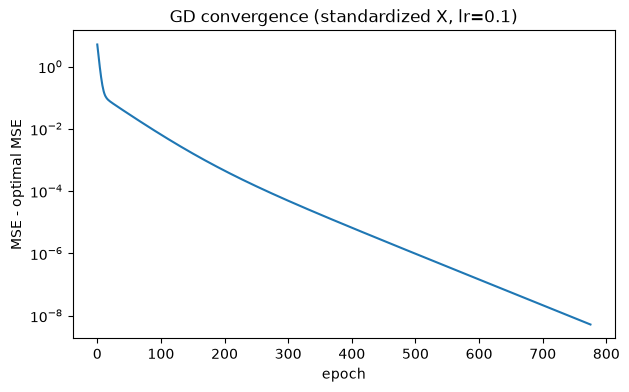

In [18]:
# 在標準化資料上跑，跟正規方程的解比對
gd = LinearRegressionGD(lr=0.1, n_epochs=5000).fit(X_train_s, y_train)
print("epochs：", len(gd.loss_history_), "  final MSE：", gd.loss_history_[-1])
print(
    "✅ w 與正規方程的最大差異：",
    np.abs(gd.w_ - ne_s.w_).max(),
    "（應 < 1e-3：loss 改善 < tol 就停，不是精確解）",
)
print(
    "✅ b 與正規方程的差異    ：",
    abs(gd.b_ - ne_s.b_),
    "（應 < 1e-10：標準化後 b 就是 y 的平均）",
)

best_mse = np.mean((ne_s.predict(X_train_s) - y_train) ** 2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.maximum(np.array(gd.loss_history_) - best_mse, 1e-16))
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE - optimal MSE")
ax.set_title("GD convergence (standardized X, lr=0.1)")
plt.show()

In [19]:
# 實驗：學習率 × 是否標準化
rows = []
with np.errstate(over="ignore", invalid="ignore"):
    for data_name, X in [("scaled", X_train_s), ("raw", X_train)]:
        for lr in [0.5, 0.1, 0.01, 1e-6, 1e-7]:
            m = LinearRegressionGD(lr=lr, n_epochs=2000).fit(X, y_train)
            rows.append(
                {
                    "data": data_name,
                    "lr": lr,
                    "epochs": len(m.loss_history_),
                    "final_mse": m.loss_history_[-1],
                }
            )
display(pd.DataFrame(rows))

,data,lr,epochs,final_mse
0,scaled,5.000000e-01,2000,2.289048e+40
1,scaled,1.000000e-01,776,5.179331e-01
2,scaled,1.000000e-02,2000,5.183998e-01
3,scaled,1.000000e-06,2000,5.589813e+00
4,scaled,1.000000e-07,2000,5.625735e+00
5,raw,5.000000e-01,25,inf
6,raw,1.000000e-01,28,inf
7,raw,1.000000e-02,33,inf
8,raw,1.000000e-06,203,inf
9,raw,1.000000e-07,2000,1.333204e+00


### 補充（TODO 8）：Hessian、曲率與梯度下降的收斂

TODO 8 用到 Hessian $H$ 與它的特徵值 $\lambda_{\max}$、$\lambda_{\min}$，這裡先把它們的定義與關係講清楚（特徵值、特徵向量 $u_i$ 的定義見 TODO 4 補充的 Notation）。

**定義**：記 $\theta = (b, w_1, \dots, w_8)$（長度 9，同 TODO 4 補充），$L(\theta)$ 為 loss。

- **梯度** $\nabla L$：一階偏微分排成的向量，$(\nabla L)_j = \dfrac{\partial L}{\partial \theta_j}$，長度 9 —— loss 往哪個方向上升最快。
- **Hessian** $H$：二階偏微分排成的矩陣，$H_{jk} = \dfrac{\partial^2 L}{\partial \theta_j\, \partial \theta_k}$，大小 $9 \times 9$，而且對稱（$H_{jk} = H_{kj}$）—— 梯度本身怎麼變化，也就是 loss 的**曲率**（彎曲程度）。
- 一維的類比：$f'(x)$ 是斜率、$f''(x)$ 是彎曲程度；$H$ 就是多維版的 $f''$。

**意義**：在 $\theta$ 附近做二階泰勒展開，

$$L(\theta + \Delta) \approx L(\theta) + \nabla L^\top \Delta + \tfrac12\, \Delta^\top H \Delta$$

- 沿單位方向 $v$ 走一小步 $t$：$L$ 的變化 $\approx t\,(\nabla L^\top v) + \tfrac12 t^2\,(v^\top H v)$，所以 **$v^\top H v$ 就是 loss 沿 $v$ 方向的曲率**。
- 曲率大 = 那個方向很陡、彎得很急；曲率小 = 很平。

**MSE 的 Hessian**：$L(\theta) = \frac1n \lVert X_b\theta - y\rVert^2$，

- 微分一次：$\nabla L = \frac2n X_b^\top (X_b\theta - y)$（3B 程式裡的 `grad`）
- 再微分一次：$H = \frac2n X_b^\top X_b$

兩個重點：

- **$H$ 是常數**，跟 $\theta$ 無關：MSE 對 $\theta$ 是二次函數，所以上面的泰勒展開是**精確的**，不是近似 → 用 $H$ 分析梯度下降的結果是嚴格成立的。
- **$H$ 跟 TODO 4 的 $A = X_b^\top X_b$ 只差常數 $\frac2n$**：特徵向量 $u_i$ 完全相同，特徵值都乘上 $\frac2n$，所以 $\kappa$ 一樣（TODO 4 補充實驗 1 的 $\lambda$ 乘上 $2/16512$，就是 TODO 8 表格的 4.05、0.095）。$H$ 半正定 → 所有曲率 $\ge 0$ → loss 是一個「碗」，沒有局部極小。

**為什麼變成看特徵值**：把 $v = u_i$ 代進曲率，$u_i^\top H u_i = \lambda_i$ —— **$H$ 的特徵值 $\lambda_i$ 就是沿特徵向量 $u_i$ 方向的曲率**。

- $\lambda_{\max}$：最陡的方向（$u_{\max}$）的曲率；$\lambda_{\min}$：最平的方向（$u_{\min}$）的曲率。
- 等高線是橢圓，各軸方向是 $u_i$、軸長 $\propto 1/\sqrt{\lambda_i}$：曲率大的方向等高線擠在一起（窄），曲率小的方向拉得很長。

**梯度下降每一步發生什麼**：記最佳解 $\theta^*$（滿足 $\nabla L(\theta^*) = 0$）、誤差 $e_t = \theta_t - \theta^*$。

1. 因為 $L$ 是二次的，$\nabla L(\theta) = \nabla L(\theta) - \nabla L(\theta^*) = H(\theta - \theta^*) = H e_t$。
2. 更新 $\theta_{t+1} = \theta_t - \text{lr}\cdot H e_t$，兩邊減 $\theta^*$，得到 $e_{t+1} = (I - \text{lr}\cdot H)\, e_t$。
3. 把 $e_t$ 拆成各特徵向量方向的分量 $e_t = \sum_i c_i u_i$（$u_i$ 兩兩正交，所以拆得開）。因為 $H u_i = \lambda_i u_i$，每個分量**各自獨立**地每步乘上 $(1 - \text{lr}\cdot\lambda_i)$，也就是 $c_i \leftarrow (1 - \text{lr}\cdot\lambda_i)\, c_i$。

一維類比：$f(x) = \frac{a}{2}x^2$，$x \leftarrow x - \text{lr}\cdot a x = (1 - \text{lr}\cdot a)\,x$ —— 多維的情況就是 9 個這樣的一維問題同時在跑，各自的 $a$ 是 $\lambda_i$。

由此直接得到 TODO 8 的三個結論：

- **不發散的條件**：每個方向都要 $|1 - \text{lr}\cdot\lambda_i| < 1$，最嚴格的是曲率最大的那個 → $\text{lr} < 2/\lambda_{\max}$。（直觀：彎得很急的方向，步子大了就會衝過谷底、跳到對面更高的地方，越跳越遠。）
- **最慢的方向**：$\text{lr}$ 被 $\lambda_{\max}$ 限制住之後，曲率最小的方向每步只縮小 $1 - \text{lr}\cdot\lambda_{\min}$。取 $\text{lr} \approx 1/\lambda_{\max}$ 時約為 $1 - 1/\kappa$ → 需要約 $\kappa$ 步。
- 所以 $\lambda_{\max}$ 決定「能走多大步」，$\lambda_{\min}$ 決定「最慢的方向要走多久」，兩者的比值 $\kappa$ 決定收斂速度。

**注意**：TODO 8 (1) 答案裡「沿第 $i$ 個特徵方向」指的是 $H$ 的第 $i$ 個**特徵向量** $u_i$ 的方向，不是第 $i$ 個特徵（欄位）。兩者只有在各欄互相正交時才一致；本資料有共線性，$u_{\min}$ 是好幾個特徵的組合（TODO 4 補充實驗 2）。

### TODO 8（問答）

**Notation**（定義與推導見上方補充）：MSE 的 Hessian $H = \frac{2}{n} X_b^\top X_b$（含 bias 欄），$\lambda_{\max}$、$\lambda_{\min}$ 為其最大、最小特徵值，$\kappa = \lambda_{\max} / \lambda_{\min}$。實測：

| | $\lambda_{\max}$ | $\lambda_{\min}$ | $\kappa$ |
| --- | --- | --- | --- |
| raw | $\approx 6.7\times10^{6}$ | $\approx 1.2\times10^{-4}$ | $\approx 5.6\times10^{10}$ |
| scaled | $\approx 4.05$ | $\approx 0.095$ | $\approx 43$ |

> **(1)** raw 資料在哪些 lr 會發散？最大能用的 lr 大概多少？scaled 為什麼 lr=0.5 也會炸？

梯度下降在二次 loss 上，沿第 $i$ 個特徵方向的誤差每步乘上 $(1 - \text{lr}\cdot\lambda_i)$；只要有任一方向 $|1 - \text{lr}\cdot\lambda_i| > 1$ 就會逐步放大而發散，因此穩定條件為

$$\text{lr} < \frac{2}{\lambda_{\max}}$$

- raw：$2/\lambda_{\max} \approx 3.0\times10^{-7}$ → lr = 0.5、0.1、0.01、1e-6 皆超過上限而發散，只有 1e-7 穩定。
- scaled：$2/\lambda_{\max} \approx 0.494$ → lr = 0.5 略超過上限，同樣發散；0.1、0.01 都在範圍內。
- raw 的 $\lambda_{\max}$ 之所以極大，是因為 Population（數值 ~$10^3$）這類大尺度特徵讓 $X^\top X$ 在該方向的曲率非常陡。

> **(2)** raw 用不會發散的 lr 跑 2000 epochs，MSE 跟最佳解（約 0.52）差多少？為什麼這麼慢？

- raw、lr = 1e-7、2000 epochs 後 $\text{MSE} \approx 1.33$，最佳解 $\approx 0.518$，仍差約 0.8，遠未收斂。
- lr 被最陡方向限制在 ~$10^{-7}$，但在最平緩方向每步收縮因子 $1 - \text{lr}\cdot\lambda_{\min} \approx 1 - 10^{-11}$，幾乎不動。
- 收斂所需步數約 $O(\kappa) \approx 10^{10}$，2000 步相對而言等於沒有前進。
- 對照 scaled、lr = 0.1：最慢方向收縮因子 $\approx 1 - 0.1 \times 0.095 \approx 0.99$，約 776 步即收斂到 tol。

> **(3)** 連結到 TODO 4 的條件數：條件數大，對梯度下降代表什麼？

$\kappa$ 決定梯度下降的「收斂速度」：lr 上限由 $\lambda_{\max}$ 決定（$\text{lr} < 2/\lambda_{\max}$），最慢方向的進度由 $\text{lr}\cdot\lambda_{\min}$ 決定，兩者合起來使最慢方向每步收縮因子約為 $1 - 2/\kappa$，所需迭代次數約與 $\kappa$ 成正比。

- 幾何上，$\kappa$ 大代表 loss 等高線是細長的橢圓（狹長山谷）：梯度主要指向陡峭的谷壁而非谷底方向，於是在谷壁間來回震盪、沿谷底推進極慢。
- 注意：發散的直接原因是 $\text{lr} > 2/\lambda_{\max}$，而不是 $\kappa$ 本身；$\kappa$ 大的後果是「所有不發散的 lr 都慢到不可用」。
- 標準化把 $\kappa$ 從 $5.6\times10^{10}$ 降到 43，所以 scaled 版本能用大 lr 並在數百步內收斂。

（TODO 4 的「誤差放大」是 $\kappa$ 在直接解線性方程組時的意義；在梯度下降中 $\kappa$ 主要反映收斂速度。）

### 3C. Ridge（L2 正則化）

目標函數：$\lVert y - Xw - b\rVert^2 + \alpha\lVert w\rVert^2$（bias **不**懲罰，跟 sklearn 的定義相同）

閉式解：$\theta = (X_b^\top X_b + \alpha I')^{-1} X_b^\top y$，其中 $I'$ 是單位矩陣但 bias 那格為 0。

#### 本節符號

| 符號 | 意義 | 程式裡 |
| --- | --- | --- |
| $\alpha$（alpha） | 正則化強度，$\ge 0$；越大，$w$ 被壓得越小 | `self.alpha` |
| $\lVert w\rVert^2$ | $\sum_{j=1}^{d} w_j^2$，**不含** $b$ | — |
| $I'$ | $(d + 1) \times (d + 1)$ 的單位矩陣，但 $[0, 0]$（bias 那格）改成 0 | `identity_matrix` |
| 閉式解 | 用一個公式直接算出答案，不必迭代 | — |

**推導**：目標 $\lVert X_b\theta - y\rVert^2 + \alpha\,\theta^\top I'\theta$（$\theta^\top I'\theta = \sum_{j \ge 1}\theta_j^2 = \lVert w\rVert^2$，跳過 bias）。對 $\theta$ 微分：$2X_b^\top(X_b\theta - y) + 2\alpha I'\theta = 0$ → $(X_b^\top X_b + \alpha I')\,\theta = X_b^\top y$。跟正規方程只差「對角線（bias 那格以外）都加上 $\alpha$」。

**為什麼 bias 不懲罰**：$b$ 只是把整條預測上下平移（標準化後 $b$ 就是 $y$ 的平均），懲罰它會讓預測整體往 0 偏，沒有「降低複雜度」的作用。

**係數路徑**（下一格的圖）：$\alpha$ 從 $10^{-2}$ 到 $10^6$，每個 $\alpha$ 各 fit 一次，畫出每個特徵的 $w_j$ 怎麼隨 $\alpha$ 變化。

#### 最小例子：TODO 9（Ridge 閉式解）

同一份資料，$\alpha = 1$。Ridge 解的是 $(X_b^\top X_b + \alpha I')\,\theta = X_b^\top y$，$I'$ 是左上角改成 0 的單位矩陣（bias 不懲罰）。

1. **正確答案**：逐元素建出 $I'$（$I'_{jk} = 1$ 若 $j = k \ne 0$，否則 0），加進 $A$ 後用克拉瑪公式解。目標：$\theta = (2.3333, 1.3333)$ —— 跟 OLS 的 $(1, 2)$ 比，斜率被壓小，bias 變大來補。
2. **積木**：`np.identity`、把 `[0, 0]` 改成 0、`Xb.T @ Xb + alpha * I`。
3. **留給你**：組成 TODO 9 的三行。

In [20]:
# 最小例子：TODO 9（Ridge 閉式解）
import numpy as np

X_mini = np.array([[1.0], [2.0], [3.0]])
y_mini = np.array([3.0, 5.0, 7.0])
alpha_mini = 1.0
Xb_mini = np.c_[np.ones(len(X_mini)), X_mini]  # (3, 2)

# ---- 1. 正確答案：逐元素建 I′、克拉瑪公式 ----
I_loop = [[1.0 if (j == k and j != 0) else 0.0 for k in range(2)] for j in range(2)]
A_loop = [[sum(Xb_mini[i, j] * Xb_mini[i, k] for i in range(3)) + alpha_mini * I_loop[j][k] for k in range(2)] for j in range(2)]
c_loop = [sum(Xb_mini[i, j] * y_mini[i] for i in range(3)) for j in range(2)]
det_mini = A_loop[0][0] * A_loop[1][1] - A_loop[0][1] * A_loop[1][0]
theta_loop = [
    (c_loop[0] * A_loop[1][1] - A_loop[0][1] * c_loop[1]) / det_mini,
    (A_loop[0][0] * c_loop[1] - A_loop[1][0] * c_loop[0]) / det_mini,
]
print("I′ =", I_loop, "  A = XbᵀXb + αI′ =", np.array(A_loop).tolist())
print("正確答案：θ =", np.round(theta_loop, 4), "（OLS 是 [1, 2]）")

# ---- 2. 積木 ----
I_mini = np.identity(Xb_mini.shape[1])
print("\nnp.identity(d+1)\n", I_mini)
I_mini[0, 0] = 0
print("改 [0, 0] = 0 之後\n", I_mini)
print("Xb.T @ Xb\n", Xb_mini.T @ Xb_mini)

# ---- 3. 留給你 ----
# 問題：I′ 要乘上什麼、加到哪個矩陣？再用跟 TODO 3 同一個函數解出 θ，應等於 theta_loop。
#       如果忘了把 [0, 0] 設成 0，b 也會被往 0 壓 —— 試試看 θ 會變成多少？
# 寫完 TODO、執行過下一格之後，取消下面的註解來對照（應印出 2.3333 [1.3333]）：
# m_mini = RidgeNE(alpha=1.0).fit(X_mini, y_mini)
# print(round(m_mini.b_, 4), m_mini.w_.round(4))

I′ = [[0.0, 0.0], [0.0, 1.0]]   A = XbᵀXb + αI′ = [[3.0, 6.0], [6.0, 15.0]]
正確答案：θ = [2.3333 1.3333] （OLS 是 [1, 2]）

np.identity(d+1)
 [[1. 0.]
 [0. 1.]]
改 [0, 0] = 0 之後
 [[0. 0.]
 [0. 1.]]
Xb.T @ Xb
 [[ 3.  6.]
 [ 6. 14.]]


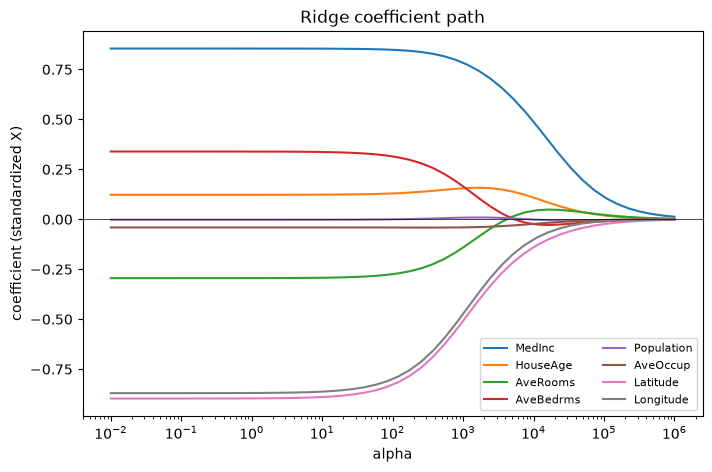

In [21]:
class RidgeNE(LinearRegressionNE):
    """Ridge 閉式解：最小化 ‖y − Xw − b‖² + α‖w‖²（bias 不懲罰）。"""

    def __init__(self, alpha: float = 1.0) -> None:
        self.alpha = alpha

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,)。學到 w_ (d,) 與 b_，回傳 self。"""
        Xb = add_bias(X)
        y = np.asarray(y, dtype=float)
        # TODO 9（程式）：Ridge 閉式解
        #   - 建一個 (d+1)×(d+1) 的單位矩陣，把 [0, 0] 設成 0（bias 不懲罰）
        #   - 一樣用 np.linalg.solve
        identity_matrix = np.identity(n=Xb.shape[1])
        identity_matrix[0, 0] = 0
        theta = np.linalg.solve(Xb.T @ Xb + self.alpha * identity_matrix, Xb.T @ y)
        self.b_, self.w_ = theta[0], theta[1:]
        return self


# 係數路徑：alpha 由小到大，看每個係數怎麼被壓向 0
alphas = np.logspace(-2, 6, 50)
paths = np.array([RidgeNE(a).fit(X_train_s, y_train).w_ for a in alphas])

fig, ax = plt.subplots(figsize=(8, 5))
for j, name in enumerate(feature_names):
    ax.plot(alphas, paths[:, j], label=name)
ax.set_xscale("log")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("alpha")
ax.set_ylabel("coefficient (standardized X)")
ax.set_title("Ridge coefficient path")
ax.legend(fontsize=8, ncol=2)
plt.show()

### TODO 10（問答）

> **(1)** AveRooms／AveBedrms、Latitude／Longitude 這兩組共線的係數，隨 alpha 變大怎麼變化？

- **整體**：$\alpha \to \infty$ 時所有係數單調或近單調地收縮至 0；$\alpha \lesssim 10^2$ 時係數幾乎等於 OLS 解（懲罰相對 $X^\top X$ 可忽略）。
- **AveRooms／AveBedrms**：OLS 下為一負一正（−0.29、+0.34）互相抵消；$\alpha$ 增大後 AveBedrms 降向 0，AveRooms 在 $\alpha \approx 3\times10^3$ 附近由負轉正，之後以小正值趨近 0 —— 符號回到與其相關係數（+0.158）相同的方向。
  - 原因：Ridge 解 $w = (X^\top X + \alpha I)^{-1} X^\top y$，當 $\alpha$ 遠大於 $X^\top X$ 的特徵值時 $w \approx X^\top y / \alpha$；在標準化資料上 $X^\top y$ $\propto$ 各特徵與 y 的相關係數，因此強正則化下係數的「方向」趨近單變量相關，不再區分共線特徵間的條件效果，OLS 中「一正一負互相抵消」的解被拆除。
- **Latitude／Longitude**：兩者與 y 的相關皆為負，故不翻號；兩條路徑幾乎重合、同步收縮 —— Ridge 對高度相關的特徵傾向把權重「平均分攤」，而非給出一大一小或一正一負的極端組合。
- （補充）HouseAge 在 $\alpha \approx 10^3$ 附近先微幅上升再下降：其他特徵被壓縮後，它暫時承接了部分解釋力，顯示 Ridge 路徑不一定對每個係數都單調。

> **(2)** 為什麼 Ridge 一定要在標準化後的資料上做？（想想 $\alpha\|w\|^2$ 對不同尺度的特徵公平嗎）

懲罰項 $\alpha\|w\|^2 = \alpha \sum_j w_j^2$ 對每個係數施加相同的懲罰，但係數大小取決於特徵的單位：若特徵 $x_j$ 放大 $c$ 倍，等價模型的係數縮小為 $w_j / c$，懲罰則變為原本的 $1/c^2$。

- 因此在 raw 資料上，數值大的特徵（如 Population ~$10^3$）係數本來就極小，幾乎不受懲罰；數值小的特徵係數較大，被不成比例地重罰。收縮程度取決於任意的單位選擇（美元 vs 萬美元），而非特徵的重要性。
- Ridge 解不具尺度不變性（scale equivariance），OLS 則有；標準化使各特徵 std = 1，懲罰才在特徵間公平。
- （注意：這與收斂無關 —— Ridge 有閉式解，且 $+\alpha I$ 會提高 $\lambda_{\min}$、降低條件數，數值上反而更穩定。）
- 實務：標準化也要只在訓練集 fit，用 `Pipeline(StandardScaler(), Ridge())` 可避免資料洩漏。

---
## 4. 套件實作：sklearn `LinearRegression`、`Ridge`、`Lasso`、`ElasticNet`

前處理一律包進 `Pipeline`：`fit` 時 scaler 只看訓練資料，`predict` 時自動套用同一組 $\mu$、$\sigma$。

#### sklearn 四個模型的目標函數（$\lVert w\rVert_1 = \sum_j \lvert w_j\rvert$，$\lVert w\rVert_2^2 = \sum_j w_j^2$，都不含 $b$）

| 模型 | 最小化 | 求解 |
| --- | --- | --- |
| `LinearRegression` | $\lVert y - Xw - b\rVert^2$ | 最小平方（SVD） |
| `Ridge(alpha)` | $\lVert y - Xw - b\rVert^2 + \alpha\lVert w\rVert_2^2$ | 閉式解（跟 3C 相同） |
| `Lasso(alpha)` | $\frac{1}{2n}\lVert y - Xw - b\rVert^2 + \alpha\lVert w\rVert_1$ | 座標下降（一次只更新一個 $w_j$，輪流做到收斂） |
| `ElasticNet(alpha, l1_ratio)` | $\frac{1}{2n}\lVert y - Xw - b\rVert^2 + \alpha\rho\lVert w\rVert_1 + \frac{\alpha(1 - \rho)}{2}\lVert w\rVert_2^2$，$\rho$ = `l1_ratio` | 座標下降 |

- L1 = 係數絕對值的和（Lasso）；L2 = 係數平方和（Ridge）；Elastic Net = 兩者混合。
- 注意 Ridge 與 Lasso 的資料項一個沒除、一個除以 $2n$，所以兩者的 `alpha` 數字不能直接比（TODO 11 (2)）。

#### 程式結構圖

```
sk_models["Ridge a=1 (sklearn)"] = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
├── [0]  StandardScaler   fit 時學 mean_、scale_
└── [-1] Ridge            fit 後有 coef_ (d,)、intercept_（純量）

m[-1].coef_   → 標準化空間的 w，可以直接跟手寫版的 ne_s.w_、ridge_s.w_ 比
```

In [22]:
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline

sk_models = {
    "LinearRegression (sklearn)": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge a=1 (sklearn)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso a=0.01 (sklearn)": make_pipeline(StandardScaler(), Lasso(alpha=0.01)),
    "Lasso a=0.1 (sklearn)": make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
    "ElasticNet a=0.01 (sklearn)": make_pipeline(
        StandardScaler(), ElasticNet(alpha=0.01, l1_ratio=0.5)
    ),
}
for m in sk_models.values():
    m.fit(X_train, y_train)  # pipeline 吃原始資料

ridge_s = RidgeNE(1.0).fit(X_train_s, y_train)
coef = pd.DataFrame(
    {name: m[-1].coef_ for name, m in sk_models.items()}, index=feature_names
)
coef["scratch NE"] = ne_s.w_
coef["scratch Ridge a=1"] = ridge_s.w_
display(coef.round(4))

# 驗證：手寫和 sklearn 應該幾乎一模一樣（差異 ~1e-10 等級）
print(
    "✅ NE    vs sklearn：",
    np.abs(sk_models["LinearRegression (sklearn)"][-1].coef_ - ne_s.w_).max(),
    "（應 < 1e-10）",
)
print(
    "✅ Ridge vs sklearn：",
    np.abs(sk_models["Ridge a=1 (sklearn)"][-1].coef_ - ridge_s.w_).max(),
    "（應 < 1e-10）",
)

,LinearRegression (sklearn),Ridge a=1 (sklearn),Lasso a=0.01 (sklearn),Lasso a=0.1 (sklearn),ElasticNet a=0.01 (sklearn),scratch NE,scratch Ridge a=1
MedInc,0.8544,0.8543,0.8010,0.7106,0.8240,0.8544,0.8543
HouseAge,0.1225,0.1226,0.1271,0.1065,0.1300,0.1225,0.1226
AveRooms,-0.2944,-0.2942,-0.1628,-0.0000,-0.2161,-0.2944,-0.2942
AveBedrms,0.3393,0.3390,0.2062,0.0000,0.2563,0.3393,0.3390
Population,-0.0023,-0.0023,-0.0000,-0.0000,-0.0000,-0.0023,-0.0023
AveOccup,-0.0408,-0.0408,-0.0306,-0.0000,-0.0359,-0.0408,-0.0408
Latitude,-0.8969,-0.8962,-0.7901,-0.0115,-0.7884,-0.8969,-0.8962
Longitude,-0.8698,-0.8691,-0.7557,-0.0000,-0.7570,-0.8698,-0.8691


✅ NE    vs sklearn： 3.430589146091734e-14 （應 < 1e-10）
✅ Ridge vs sklearn： 3.164135620181696e-14 （應 < 1e-10）


### TODO 11（問答）

> **(1)** 把 Lasso 的 alpha 改成 0.1 再跑一次，哪些係數被壓成剛好 0？Ridge 會這樣嗎？

- Lasso $\alpha = 0.1$：AveRooms、AveBedrms、Population、AveOccup、Longitude 恰為 0，僅保留 MedInc、HouseAge、Latitude（$\approx -0.01$）。
- Lasso $\alpha = 0.01$：只有 Population 為 0，其餘係數較 OLS 小幅收縮。
- Ridge 不會產生恰為 0 的係數，只會連續收縮、在 $\alpha \to \infty$ 時漸近 0。

原因：

- L1 懲罰 $\alpha|w_j|$ 在 $w_j = 0$ 不可微，最佳條件為 $|x_j^\top(y - Xw)| \le n\alpha$ 時 $w_j = 0$（soft-thresholding），只要某特徵對殘差的解釋力不足以抵過懲罰，係數就被精確設為 0 → 稀疏解、兼具特徵選擇。
- L2 懲罰可微，梯度 $2\alpha w_j$ 在 $w_j \to 0$ 時跟著趨近 0，懲罰的「推力」消失，因此只縮小不歸零。
- 幾何上：L1 約束區域是菱形（尖角落在座標軸上），MSE 等高線易在尖角相切；L2 是圓，無尖角。

共線特徵的處理差異：Lasso 對 Latitude／Longitude 只保留一個、另一個歸零，且選誰不穩定；Ridge 則讓兩者係數相近並同步收縮（平均分攤）；ElasticNet（L1 + L2）介於兩者之間，能稀疏化又傾向成組保留相關特徵。

另注意：$\alpha = 0.1$ 幾乎砍掉經緯度，但 EDA 顯示地理位置對房價很重要 → 預期測試集表現明顯變差（過度正則化／欠擬合）。

> **(2)** Lasso a=0.01 和 Ridge a=1 的懲罰力道可以直接比嗎？

不能直接比較，原因有二：

① **目標函數的尺度不同**：

| 模型 | 目標函數 |
| --- | --- |
| Ridge（sklearn） | $\lVert y - Xw \rVert^2 + \alpha \lVert w \rVert_2^2$ |
| Lasso（sklearn） | $\frac{1}{2n} \lVert y - Xw \rVert^2 + \alpha \lVert w \rVert_1$ |

Lasso 的資料項除以 $2n$，等價於未正規化形式 $\|y - Xw\|^2 + 2n\alpha\|w\|_1$；本例 $n = 16512$，$\alpha = 0.01$ 對應 $2n\alpha \approx 330$，與 Ridge 的 $\alpha = 1$ 不在同一量級，這也是 Lasso $\alpha = 0.01$ 的收縮明顯大於 Ridge $\alpha = 1$ 的原因。

② **懲罰的函數形式不同**：$\|w\|_1$ 與 $\|w\|_2^2$ 對係數大小的反應不同（線性 vs 平方），即使尺度對齊也無法一對一換算。

- $\frac{1}{2n}$ 的作用：$\frac{1}{n}$ 使 $\alpha$ 的意義不隨樣本數改變（資料量加倍時同一 $\alpha$ 效果不變）；$\frac{1}{2}$ 用來抵消平方項微分產生的 2。
- （sklearn 的 Ridge 未除以 $n$ 屬於歷史慣例上的不一致，並非刻意設計。）
- 實務上 $\alpha$ 不靠手動比較，而是用交叉驗證選擇（`RidgeCV`、`LassoCV`）。

---
## 5. 調參

全程只用 `X_train`（測試集鎖住），依 README「調參流程」。線性回歸的超參數：

| 類別 | 超參數 | 說明 |
| --- | --- | --- |
| 容量 | `PolynomialFeatures(degree)` | 線性回歸本身的容量是固定的（$d + 1$ 個參數）；要讓它能表達曲面，只能擴充特徵。degree 越高越彈性：8 個特徵 → degree 2 有 44 個、degree 3 有 164 個 |
| 正則化 | Ridge／Lasso 的 `alpha`、`l1_ratio` | 壓縮係數、降低變異；尺度型參數用 `np.logspace` |
| 前處理 | 長尾特徵取 `log1p` | 跟第四章 KNN 的 scaler 一樣，前處理也可以當成超參數比較（TODO 1 (2)） |
| 最佳化 | 梯度下降的 lr、epochs | 有閉式解，sklearn 也不用 GD → 不需要調 |

選模型的指標用 **RMSE**（跟第 6 節報告的成績一致）；MAE 一起看，用來判斷誤差是不是被少數幾筆主導。

#### 本節名詞

- **多項式特徵**（`PolynomialFeatures(degree)`）：把原本的特徵展開成所有次數 $\le$ degree 的乘積項。例：$(x_1, x_2)$、degree 2 → $(x_1, x_2, x_1^2, x_1x_2, x_2^2)$。$d$ 個特徵、degree $k$ 時共有 $\binom{d + k}{k} - 1$ 個（扣掉常數項）：$d = 8$ 時 degree 2 有 $\binom{10}{2} - 1 = 44$ 個、degree 3 有 $\binom{11}{3} - 1 = 164$ 個。模型對這些新特徵仍是線性的，但對原始特徵是曲面。
- **偏差（bias）與變異（variance）**：偏差 = 模型太簡單、連訓練資料都學不好（欠擬合：train 與 val 都差、兩者接近）；變異 = 模型對「剛好拿到哪些訓練資料」很敏感（過擬合：train 好、val 明顯較差）。注意這裡的 bias 跟截距 $b$ 是兩回事。
- **validation curve**（`validation_curve`）：其他設定固定、只改一個超參數，對每個值做一次 CV，畫 train 與 validation 兩條曲線。
- **grid search**（`GridSearchCV`）：把 `param_grid` 所有組合都試一次，每組做一次 CV；結果在 `cv_results_`（每組的 `mean_test_score`、`std_test_score`）、`best_params_`、`best_score_`。
- **1-SE rule**：RMSE 越小越好，所以門檻 = 最佳那組的平均 **＋** 最佳那組的標準差；平均 $\le$ 門檻的組合都算「跟最佳分不出來」，從中挑最簡單的。
- **learning curve**（`learning_curve`）：只拿訓練 fold 的前 $m$ 筆來訓練，$m$ 由小到大，看「多給資料」有沒有幫助。
- **`cross_val_predict`**：每一筆訓練資料都由「沒看過它的那個 fold 的模型」預測，得到整份訓練集的 out-of-fold 預測（TODO 13 用來找誰的誤差最大）。
- **外插**（extrapolation）：在訓練資料沒有涵蓋的範圍做預測，模型在那裡完全沒有被約束。

#### 程式結構圖：`poly_ridge` 的 pipeline

```
poly_ridge(tf, degree, alpha) = Pipeline([
    ("tf",     tf),                         # "passthrough"（不做事）或 log_tf
    ("poly",   PolynomialFeatures(degree)), # 8 → 8／44／164 欄
    ("scaler", StandardScaler()),
    ("ridge",  Ridge(alpha)),
])
log_tf = ColumnTransformer([("log", FunctionTransformer(np.log1p), SKEWED)], remainder="passthrough")
         # 只對 SKEWED 這 4 欄取 log1p，其他欄原樣通過

參數名 = 步驟名__參數名：poly__degree、ridge__alpha；"tf" 本身也是參數（整個步驟換掉）
model_1se["poly"]   → 用名字取出某一步
model_1se[:-1]      → 去掉最後的 Ridge，只剩特徵轉換的 pipeline（7B 會用）
```

In [23]:
import warnings
from scipy.linalg import LinAlgWarning
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    GridSearchCV,
    cross_val_predict,
    learning_curve,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures

# degree 3、alpha 很小時 XᵀX + αI 接近奇異，Ridge 會發出 LinAlgWarning（結果照樣算得出來）；TODO 13 會看到它的後果
warnings.filterwarnings("ignore", category=LinAlgWarning)

# 調參前的參照點：Dummy 與第 4 節的預設模型
for name, m in {
    "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge a=1": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso a=0.01": make_pipeline(StandardScaler(), Lasso(alpha=0.01)),
    "Lasso a=0.1": make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
}.items():
    baseline.loc[name] = cv_summary(m)
display(baseline)

,rmse,mae,r2
Dummy mean,1.1562 ± 0.0122,0.9139 ± 0.0101,-0.0002 ± 0.0002
Dummy median,1.1878 ± 0.0128,0.8860 ± 0.0092,-0.0557 ± 0.0068
LinearRegression,0.7205 ± 0.0139,0.5291 ± 0.0094,0.6115 ± 0.0124
Ridge a=1,0.7205 ± 0.0139,0.5291 ± 0.0094,0.6115 ± 0.0124
Lasso a=0.01,0.7239 ± 0.0133,0.5323 ± 0.0087,0.6078 ± 0.0117
Lasso a=0.1,0.8196 ± 0.0132,0.6192 ± 0.0081,0.4973 ± 0.0111


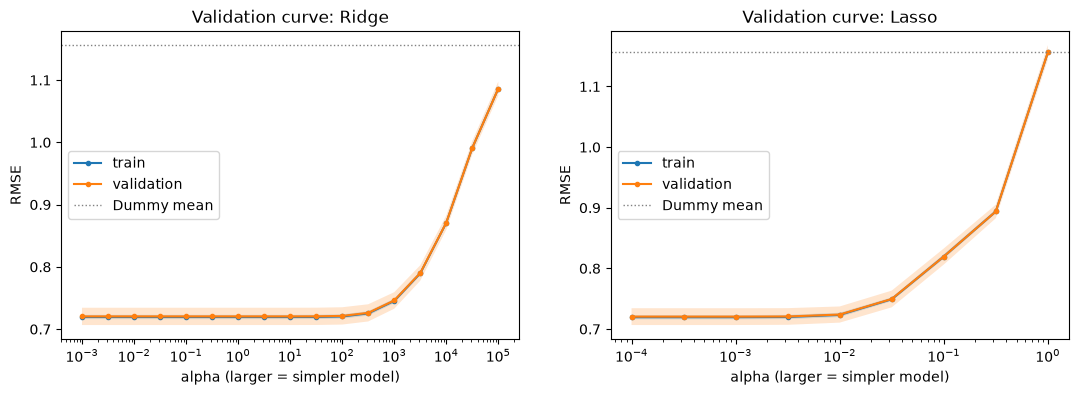

,train,val,val_std
alpha,,,
0.001,0.7196,0.7205,0.0139
0.010,0.7196,0.7205,0.0139
0.100,0.7196,0.7205,0.0139
1.000,0.7196,0.7205,0.0139
10.000,0.7196,0.7205,0.0139
100.000,0.7204,0.7213,0.0139
1000.000,0.7454,0.7461,0.0133
10000.000,0.8708,0.8710,0.0114
100000.000,1.0863,1.0864,0.0113


,train,val,val_std
alpha,,,
0.000100,0.7196,0.7205,0.0139
0.000316,0.7196,0.7205,0.0139
0.001000,0.7196,0.7205,0.0139
0.003162,0.7199,0.7207,0.0137
0.010000,0.7233,0.7239,0.0133
0.031623,0.7492,0.7496,0.0138
0.100000,0.8196,0.8196,0.0132
0.316228,0.8939,0.8939,0.0112
1.000000,1.1562,1.1562,0.0122


In [24]:
# 單一參數掃描：正則化強度 alpha（degree = 1，也就是原本的 8 個特徵）
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vc_alpha = {}
for ax, (name, est, param, alphas) in zip(
    axes,
    [
        (
            "Ridge",
            make_pipeline(StandardScaler(), Ridge()),
            "ridge__alpha",
            np.logspace(-3, 5, 17),
        ),
        (
            "Lasso",
            make_pipeline(StandardScaler(), Lasso(max_iter=10_000)),
            "lasso__alpha",
            np.logspace(-4, 0, 9),
        ),
    ],
):
    tr, va = validation_curve(
        est,
        X_train,
        y_train,
        param_name=param,
        param_range=alphas,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    tr, va = -tr, -va
    for label, s in [("train", tr), ("validation", va)]:
        ax.plot(alphas, s.mean(1), "o-", ms=3, label=label)
        ax.fill_between(alphas, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
    ax.axhline(y_train.std(ddof=0), color="gray", ls=":", lw=1, label="Dummy mean")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (larger = simpler model)")
    ax.set_ylabel("RMSE")
    ax.set_title(f"Validation curve: {name}")
    ax.legend()
    vc_alpha[name] = pd.DataFrame(
        {"train": tr.mean(1), "val": va.mean(1), "val_std": va.std(1)},
        index=pd.Index(alphas, name="alpha"),
    )
plt.show()
display(vc_alpha["Ridge"].iloc[::2].round(4))
display(vc_alpha["Lasso"].round(4))

### TODO 12（問答）

> **(1)** Ridge 的 validation curve 幾乎是一條水平線，跟第三章邏輯回歸的 C 曲線很不一樣。
>
> **(a)** 讀表：$\alpha$ = 0.001、100、$10^4$ 時 train 與 val RMSE 各是多少？train 與 val 的差距多大？
>
> **(b)** 一般判斷：train 很低、val 明顯較高 → 過擬合；train 和 val 一樣高、差距很小 → 欠擬合。這份資料的線性模型屬於哪一種？
>
> **(c)** 正則化的作用是「降低變異」。用參數個數（9 個）與樣本數（16,512 筆）解釋：為什麼這裡的變異本來就很小、正則化幫不上忙？

**(a)**

| $\alpha$ | train RMSE | val RMSE | val − train |
| --- | --- | --- | --- |
| 0.001 | 0.7196 | 0.7205 | 0.0009 |
| 100 | 0.7204 | 0.7213 | 0.0009 |
| $10^4$ | 0.8708 | 0.8710 | 0.0002 |

$\alpha \le 30$ 時兩條線完全不動；$\alpha \ge 300$ 之後一起往上（往 Dummy 的 1.156 靠近）。

**(b)** **欠擬合（高偏差）**：train 與 val 幾乎重疊（差 0.001，比 fold 間的標準差 0.014 還小），而且都停在 0.72 —— 模型連訓練資料都學不好，不是「背太多」。

**(c)** 變異來自「換一批訓練資料，學到的模型差多少」。

- 只有 9 個參數、卻有 16,512 筆資料：每個參數平均由 1,800 多筆資料決定，換一批資料係數幾乎不變（OLS 係數的變異 $\propto \sigma^2 / n$）。
- 正則化用「多一點偏差」換「少一點變異」；變異本來就接近 0 時，這筆交易只剩下付出的偏差 → $\alpha$ 小時沒差，$\alpha$ 大時只會變差。
- 對照第三章：Breast Cancer 只有 455 筆、30 個特徵、而且線性可分，不加正則化時 $\|w\|$ 會無限長大，C 才有明顯的最佳點。
- **結論**：要改善線性回歸，方向不是加正則化，而是**增加容量**（下一格的多項式特徵）。

> **(2)** Lasso：$\alpha$ 從哪裡開始明顯變差？第 4 節試的 0.01 和 0.1 各落在曲線的哪一段？

- $\alpha \le 0.003$：與 OLS 相同（0.7205–0.7207）；$\alpha = 0.01$：0.7239（只差 0.003，不到一個 std）；$\alpha = 0.1$：0.8196，已經明顯欠擬合（TODO 11 (1)：砍掉了經緯度）；$\alpha = 1$：1.1562 = Dummy（所有係數都被壓成 0，只剩 bias = 平均）。
- 0.01 在「平坦區的邊緣」、0.1 已經在「上升段」。
- 第 6 節的測試集上 Lasso 0.01 的 $R^2$ 0.582 略高於 OLS 0.576，但 CV 上反而略差 → 差距在雜訊範圍內，不能說 Lasso 比較好。


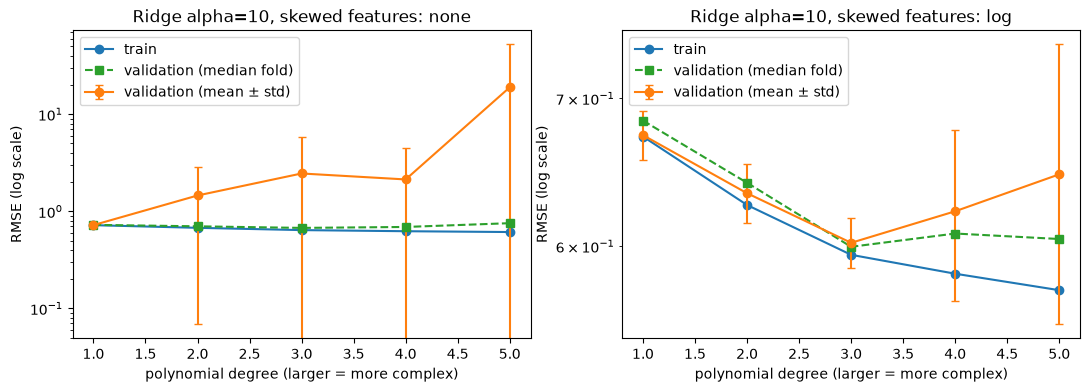

none                                       log                  \
         train      val  val_std val_median_fold   train     val val_std   
degree                                                                     
1       0.7196   0.7205   0.0139          0.7251  0.6727  0.6737  0.0174   
2       0.6756   1.4544   1.3861          0.7003  0.6263  0.6341  0.0194   
3       0.6401   2.4512   3.4156          0.6744  0.5946  0.6021  0.0158   
4       0.6233   2.1282   2.3087          0.6896  0.5830  0.6222  0.0553   
5       0.6114  18.9222  33.2917          0.7543  0.5731  0.6467  0.0937   

                        
       val_median_fold  
degree                  
1               0.6839  
2               0.6410  
3               0.5996  
4               0.6080  
5               0.6045

In [25]:
# 容量：多項式次數。固定 alpha = 10，比較「原始特徵」與「長尾特徵先取 log1p」
log_tf = ColumnTransformer(
    [("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), SKEWED)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)


def poly_ridge(
    tf: ColumnTransformer | str = "passthrough", degree: int = 1, alpha: float = 1.0
) -> Pipeline:
    """前處理 tf →（多項式展開）→ 標準化 → Ridge。tf 為 "passthrough" 表示不做前處理。"""
    return Pipeline(
        [
            ("tf", tf),
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha)),
        ]
    )


degrees = [1, 2, 3, 4, 5]
vc_deg = {}
for name, tf in [("none", "passthrough"), ("log", log_tf)]:
    tr, va = validation_curve(
        poly_ridge(tf, alpha=10.0),
        X_train,
        y_train,
        param_name="poly__degree",
        param_range=degrees,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    tr, va = -tr, -va
    vc_deg[name] = pd.DataFrame(
        {
            "train": tr.mean(1),
            "val": va.mean(1),
            "val_std": va.std(1),
            "val_median_fold": np.median(va, axis=1),
        },
        index=pd.Index(degrees, name="degree"),
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, ["none", "log"]):
    t = vc_deg[name]
    ax.plot(degrees, t["train"], "o-", label="train")
    ax.errorbar(
        degrees,
        t["val"],
        yerr=t["val_std"],
        fmt="o-",
        capsize=3,
        label="validation (mean ± std)",
    )
    ax.plot(degrees, t["val_median_fold"], "s--", label="validation (median fold)")
    ax.set_yscale("log")
    ax.set_xlabel("polynomial degree (larger = more complex)")
    ax.set_ylabel("RMSE (log scale)")
    ax.set_title(f"Ridge alpha=10, skewed features: {name}")
    ax.legend()
plt.show()
display(pd.concat(vc_deg, axis=1).round(4))

In [26]:
# 是誰把 RMSE 弄爆的？degree 2、不取 log：每一筆訓練資料的 CV 預測（每筆都由「沒看過它」的模型預測）
deg2 = poly_ridge("passthrough", degree=2, alpha=10.0)
pred_cv = cross_val_predict(deg2, X_train, y_train, cv=cv)
abs_err = np.abs(pred_cv - y_train.to_numpy())

worst = np.argsort(-abs_err)[:5]
display(
    X_train.iloc[worst][SKEWED + ["MedInc"]].assign(
        y=y_train.iloc[worst], cv_pred=pred_cv[worst].round(2)
    )
)
print(
    f"誤差最大的 5 筆佔總平方誤差的比例：{(abs_err[worst] ** 2).sum() / (abs_err ** 2).sum():.1%}"
)

fold_tbl = []
for f, (_, va_idx) in enumerate(cv.split(X_train)):
    e = abs_err[va_idx]
    fold_tbl.append(
        {
            "fold": f,
            "RMSE": np.sqrt((e**2).mean()),
            "MAE": e.mean(),
            "max |error|": e.max(),
        }
    )
display(pd.DataFrame(fold_tbl).set_index("fold").round(3))
print("對照：")
print("  > degree 1：", cv_summary(poly_ridge("passthrough", 1, 10.0)))
print("  > degree 2：", cv_summary(deg2))

,AveRooms,AveBedrms,Population,AveOccup,MedInc,y,cv_pred
19006,3.166667,0.833333,7460.0,1243.333333,10.2264,1.37500,240.20
3364,5.142857,1.142857,4198.0,599.714286,5.5179,0.67500,-43.59
13034,8.275862,1.517241,6675.0,230.172414,6.1359,2.25000,-4.88
8874,7.285714,1.214286,1154.0,41.214286,9.3370,5.00001,-1.36
1914,141.909091,25.636364,30.0,2.727273,1.8750,5.00001,10.44


誤差最大的 5 筆佔總平方誤差的比例：88.7%


,RMSE,MAE,max |error|
fold,,,
0,4.213,0.575,238.823
1,1.028,0.502,44.263
2,0.658,0.482,3.949
3,0.700,0.509,4.603
4,0.673,0.499,3.752


對照：
  > degree 1： {'rmse': '0.7205 ± 0.0139', 'mae': '0.5290 ± 0.0094', 'r2': '0.6115 ± 0.0123'}
  > degree 2： {'rmse': '1.4544 ± 1.3861', 'mae': '0.5134 ± 0.0320', 'r2': '-1.9393 ± 4.9649'}


### TODO 13（問答）

> **(1)** 不取 log 的多項式：
>
> **(a)** 讀表：degree 2、3 的 val RMSE「平均」、「標準差」、「中位數 fold」各是多少？train RMSE 呢？
>
> **(b)** 平均跟中位數差很多、標準差比平均還大，代表 5 個 fold 的分數長什麼樣子？（看 fold 表）
>
> **(c)** 定義：RMSE $= \sqrt{\frac{1}{n}\sum e_i^2}$、MAE $= \frac{1}{n}\sum |e_i|$。degree 2 的 MAE 比 degree 1 好（0.513 vs 0.529），RMSE 卻差了一倍（1.454 vs 0.721）。用「誤差取平方」解釋為什麼兩個指標結論相反。

**(a)**

| degree | train | val 平均 | val 標準差 | val 中位數 fold |
| --- | --- | --- | --- | --- |
| 1 | 0.720 | 0.721 | 0.014 | 0.725 |
| 2 | 0.676 | 1.454 | 1.386 | 0.700 |
| 3 | 0.640 | 2.451 | 3.416 | 0.674 |

train 隨 degree 穩定下降；val 的中位數也在下降（比 degree 1 好），平均卻暴增。

**(b)** 大部分 fold 正常、**少數 fold 爆掉**：degree 2 的 fold 0 RMSE 4.21、fold 1 1.03，其餘 3 個 fold 在 0.66–0.70；MAE 卻每個 fold 都在 0.48–0.58，看不出異狀。平均被一個 fold 拉高，中位數不受影響 —— 跟 TODO 2 (2)「平均 vs 中位數」是同一件事，只是這次發生在 fold 的分數上。

**(c)** RMSE 先把誤差平方再平均：一筆誤差 200 的樣本貢獻 $200^2 = 40{,}000$，抵得過 $40{,}000 / 0.5^2 = 16$ 萬筆誤差 0.5 的樣本。MAE 只把它算成 200，對 3,000 多筆的 fold 平均來說影響不大。

- 所以 degree 2 對「大多數樣本」其實預測得更準（MAE、中位數 fold 都變好），但對**極少數樣本**錯得離譜，RMSE 被這幾筆主導（誤差最大的 5 筆佔總平方誤差 88.7%）。
- **兩個指標都對，回答的是不同問題**：MAE 是「一般樣本差多少」，RMSE 會特別懲罰「災難性的錯誤」。房價預測若一筆預測成 2,000 萬美元會造成實際損失，RMSE 的警告就很重要。

> **(2)** 誤差最大的 5 筆：
>
> **(a)** 它們的特徵值有什麼共同點？對照 TODO 1 (2) 的長尾表格。
>
> **(b)** degree 2 的模型裡有 $\text{AveOccup}^2$、$\text{AveRooms} \times \text{AveOccup}$ 這種項。訓練時如果沒看過這麼大的值，這些項的係數有被「約束」住嗎？為什麼爆掉的只有某些 fold？
>
> **(c)** 取 log1p 之後，為什麼同樣的多項式就不會爆？

**(a)** 都帶有長尾特徵的極端值：前三筆的 AveOccup 是 1,243、600、230（一般街區約 3），第五筆是 AveRooms 141.9、AveBedrms 25.6 —— 正是 TODO 1 (2) 表格的 max 欄。CV 預測分別是 240（真值 1.4）、−43.6（真值 0.7）、−4.9、10.4 這種完全不合理的值。

**(b)** 沒有。係數是從訓練資料學的；某個方向上如果所有訓練樣本的值都在正常範圍，模型只需要讓係數在「正常範圍內」表現好，在範圍外會發生什麼完全沒有被約束 —— 這就是**外插**（extrapolation）。

- 多項式讓外插更嚴重：$x$ 超出範圍 10 倍，$x^2$ 就超出 100 倍、$x^3$ 超出 1,000 倍。
- 極端值只有十幾筆（TODO 1 (2)：AveOccup > 3 × p99 的只有 14 筆）。KFold 隨機分配：某個極端樣本被分到驗證 fold、而訓練 fold 裡沒有跟它一樣極端的樣本時，它就爆掉。所以爆不爆取決於「誰被分到哪個 fold」→ fold 間的變異極大（標準差 > 平均）。
- （高變異 = 過擬合的另一種樣子：模型對「哪些資料剛好在訓練集裡」非常敏感。）

**(c)** log 把乘法尺度壓成加法尺度：AveOccup 1,243 → 7.1、正常值 3 → 1.4，極端值只比一般值大 5 倍而不是 400 倍；平方之後也只大 25 倍。外插的距離變短 → 錯也錯不遠。

- 實測 log 版本：degree 2 val 0.634 ± 0.019、degree 3 0.602 ± 0.016，標準差回到正常大小。

> **(3)** 取 log 的版本：degree 從 1 到 5，train 一直下降，val 在哪裡最低？哪一段欠擬合、哪一段開始過擬合？

| degree | train | val | val − train |
| --- | --- | --- | --- |
| 1 | 0.673 | 0.674 | 0.001 |
| 2 | 0.626 | 0.634 | 0.008 |
| 3 | 0.595 | 0.602 | 0.008 |
| 4 | 0.583 | 0.622 | 0.039 |
| 5 | 0.573 | 0.647 | 0.074 |

- val 在 **degree 3 最低**（0.602）。
- degree 1–2：train、val 一起下降、差距很小 → 仍在欠擬合，增加容量有幫助。
- degree 4–5：train 繼續下降，val 反轉上升、差距擴大到 0.04–0.07，標準差也變大（0.055、0.094）→ 開始過擬合。
- 注意 degree 1 只取 log 就從 0.721 降到 0.674：**前處理本身也是在改變模型能表達的函數**（log 讓模型能表達「人數翻倍，房價變化固定」這種關係）。


/Users/cya/ml-dl-llm/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


best_params_： {'poly__degree': 3, 'ridge__alpha': np.float64(10.0), 'tf': 'log'}   CV RMSE： 0.6021


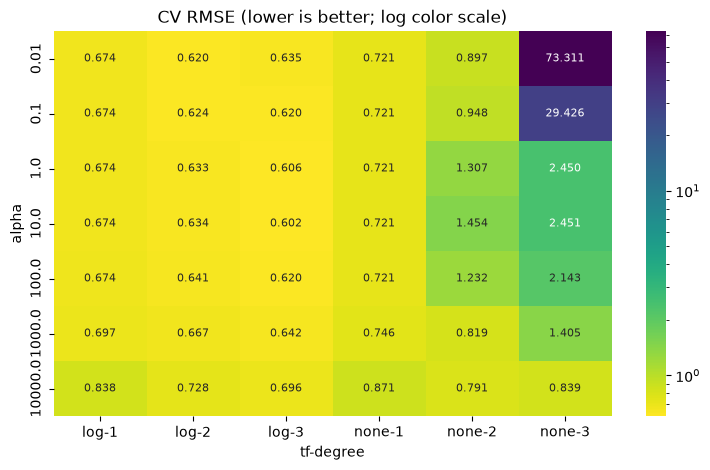

In [27]:
# 搜尋：前處理 × degree × alpha（2 × 3 × 7 = 42 組）
param_grid = {
    "tf": ["passthrough", log_tf],
    "poly__degree": [1, 2, 3],
    "ridge__alpha": np.logspace(-2, 4, 7),
}
gs = GridSearchCV(
    poly_ridge(), param_grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
)
gs.fit(X_train, y_train)

res = pd.DataFrame(
    {
        "tf": [
            "none" if isinstance(t, str) else "log" for t in gs.cv_results_["param_tf"]
        ],
        "degree": gs.cv_results_["param_poly__degree"].astype(int),
        "alpha": gs.cv_results_["param_ridge__alpha"].astype(float),
        "mean": -gs.cv_results_["mean_test_score"],
        "std": gs.cv_results_["std_test_score"],
    }
)
print(
    "best_params_：",
    {
        k: ("log" if k == "tf" and not isinstance(v, str) else v)
        for k, v in gs.best_params_.items()
    },
    "  CV RMSE：",
    round(-gs.best_score_, 4),
)

from matplotlib.colors import LogNorm

tbl = res.pivot_table(index="alpha", columns=["tf", "degree"], values="mean")
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    tbl,
    annot=True,
    fmt=".3f",
    cmap="viridis_r",
    norm=LogNorm(),
    ax=ax,
    annot_kws={"size": 8},
)
ax.set_title("CV RMSE (lower is better; log color scale)")
plt.show()

#### 最小例子：TODO 14（one-standard-error rule）

5 列的假結果表，**RMSE 越低越好**，所以門檻是 `best.mean + best.std`。

1. **正確答案**：逐列判斷有沒有在門檻內，再用 `min(..., key=...)` 依「degree 小 → alpha 大 → tf = none」挑最簡單的。目標：`degree = 3、alpha = 10、tf = none`。
2. **pandas 的積木**：`idxmin`、布林遮罩、字串排序（`"none"` 和 `"log"` 誰大）。
3. **留給你**：用 `sort_values(...).iloc[0]` 選出 `choice`。

In [28]:
# 最小例子：TODO 14（one-standard-error rule）
import pandas as pd

res_mini = pd.DataFrame(
    {
        "degree": [1, 2, 3, 3, 3],
        "alpha": [0.1, 1.0, 10.0, 1.0, 10.0],
        "tf": ["none", "log", "log", "log", "none"],
        "mean": [0.740, 0.640, 0.620, 0.600, 0.625],  # RMSE
        "std": [0.02, 0.03, 0.03, 0.03, 0.03],
    }
)
display(res_mini)

# ---- 1. 正確答案：逐列判斷 ----
best_loop = min(res_mini.to_dict("records"), key=lambda r_mini: r_mini["mean"])
threshold_loop = best_loop["mean"] + best_loop["std"]
ok_loop = []
for r_mini in res_mini.to_dict("records"):
    passed_mini = r_mini["mean"] <= threshold_loop
    print(f"degree={r_mini['degree']} alpha={r_mini['alpha']:<5} tf={r_mini['tf']:<4}  RMSE={r_mini['mean']:.3f} ≤ {threshold_loop:.3f}？{passed_mini}")
    if passed_mini:
        ok_loop.append(r_mini)
# 「簡單」的排序鍵：(degree 小, alpha 大, tf 為 none 優先)
choice_loop = min(ok_loop, key=lambda r_mini: (r_mini["degree"], -r_mini["alpha"], 0 if r_mini["tf"] == "none" else 1))
print("正確答案：", choice_loop)

# ---- 2. pandas 的積木 ----
best_mini = res_mini.loc[res_mini["mean"].idxmin()]
mask_mini = res_mini["mean"] <= best_mini["mean"] + best_mini["std"]
print("\n布林遮罩：", mask_mini.tolist())
ok_mini = res_mini[mask_mini]
display(ok_mini)
print('字串排序：sorted(["none", "log"]) =', sorted(["none", "log"]), "→ 由小到大時 log 在前")

# ---- 3. 留給你 ----
# 問題：ok_mini.sort_values(["degree", "alpha", "tf"], ascending=[?, ?, ?]).iloc[0] 要怎麼填，才會等於 choice_loop？

,degree,alpha,tf,mean,std
0,1,0.1,none,0.740,0.02
1,2,1.0,log,0.640,0.03
2,3,10.0,log,0.620,0.03
3,3,1.0,log,0.600,0.03
4,3,10.0,none,0.625,0.03


degree=1 alpha=0.1   tf=none  RMSE=0.740 ≤ 0.630？False
degree=2 alpha=1.0   tf=log   RMSE=0.640 ≤ 0.630？False
degree=3 alpha=10.0  tf=log   RMSE=0.620 ≤ 0.630？True
degree=3 alpha=1.0   tf=log   RMSE=0.600 ≤ 0.630？True
degree=3 alpha=10.0  tf=none  RMSE=0.625 ≤ 0.630？True
正確答案： {'degree': 3, 'alpha': 10.0, 'tf': 'none', 'mean': 0.625, 'std': 0.03}

布林遮罩： [False, False, True, True, True]


,degree,alpha,tf,mean,std
2,3,10.0,log,0.620,0.03
3,3,1.0,log,0.600,0.03
4,3,10.0,none,0.625,0.03


字串排序：sorted(["none", "log"]) = ['log', 'none'] → 由小到大時 log 在前


In [29]:
# one-standard-error rule：跟最佳差距不到一個標準差的候選中，挑「最簡單」的
best = res.loc[res["mean"].idxmin()]

# TODO 14（程式）
#   - ok：mean ≤ best.mean + best.std 的所有列（RMSE 越低越好，方向跟第四章 accuracy 相反、跟第三章 log loss 相同）
#   - choice：ok 裡最簡單的一列。這裡的「簡單」：degree 小優先；degree 相同時 alpha 大優先（壓得越多越簡單）；
#     再相同時 tf = "none" 優先（少一個前處理）
#   - 提示：sort_values(["degree", "alpha", "tf"], ascending=[True, False, False]).iloc[0]
#     （字串排序："none" > "log"，想想 tf 那一欄的 ascending 為什麼是 False）
ok = res[res["mean"] <= best["mean"] + best["std"]]
choice = ok.sort_values(["degree", "alpha", "tf"], ascending=[True, False, False]).iloc[
    0
]

print("CV 最佳 ：", best.to_dict())
print("1-SE 候選：")
display(ok.round(4))
print("1-SE 選擇：", choice.to_dict())
print("✅ 1-SE 應選到 degree = 3、alpha = 10、tf = log")

model_1se = poly_ridge(
    log_tf if choice["tf"] == "log" else "passthrough",
    int(choice["degree"]),
    float(choice["alpha"]),
).fit(X_train, y_train)
print("展開後的特徵數：", model_1se["poly"].n_output_features_)

CV 最佳 ： {'tf': 'log', 'degree': 3, 'alpha': 10.0, 'mean': 0.60210935674695, 'std': 0.01579274065235949}
1-SE 候選：


,tf,degree,alpha,mean,std
33,log,3,1.0,0.6062,0.0302
35,log,3,10.0,0.6021,0.0158


1-SE 選擇： {'tf': 'log', 'degree': 3, 'alpha': 10.0, 'mean': 0.60210935674695, 'std': 0.01579274065235949}
✅ 1-SE 應選到 degree = 3、alpha = 10、tf = log
展開後的特徵數： 164


### TODO 15（問答）

> **(1)** 看 heatmap：
>
> **(a)** none 的 degree 2、3 兩欄，alpha 從 0.01 增加到 $10^4$，RMSE 怎麼變？
>
> **(b)** 為什麼很大的 alpha 能「救」不取 log 的多項式？救得到 log 版本的水準嗎？
>
> **(c)** log 的三欄：最佳落在哪一格？

**(a)** degree 3：73.3 → 29.4 → 2.45 → … → 0.84（$\alpha = 10^4$）；degree 2：0.90–1.45 之間亂跳，到 $10^4$ 才 0.79。整體趨勢是 alpha 越大越不會爆，但需要非常大的 alpha。

**(b)** Ridge 把係數往 0 壓 → 高次項的係數變小 → 外插時 $w \cdot x^3$ 沒那麼大。但 alpha 是「所有係數一起壓」：要壓到極端值不爆，有用的係數也被壓扁了 → 最好也只到 0.79，比 log 版本的 degree 1（0.674）還差。

- **教訓**：正則化是「對係數」的處理，log 是「對特徵」的處理。問題出在特徵的尺度（長尾）時，從特徵下手比較對症；正則化只能用偏差換變異。

**(c)** log、degree 3、$\alpha = 10$：0.6021。同一欄 $\alpha = 1$ 是 0.6062、$\alpha = 0.01$ 是 0.6345 —— degree 3 有 164 個特徵，這時正則化終於有用了（對照 TODO 12：degree 1 時 alpha 完全沒作用）。

> **(2)** 1-SE rule 選到什麼？跟 CV 最佳一樣嗎？為什麼這次沒有換成更簡單的模型？

- 門檻 = 最佳 0.6021 + 一個標準差 0.0158 = 0.6179。只有兩組進得來：log、degree 3、$\alpha = 1$（0.6062）與 $\alpha = 10$（0.6021，就是最佳）。
- 依「degree 小 → alpha 大」排序，兩組 degree 都是 3，alpha 大的是 10 → **1-SE 選到的就是 CV 最佳**。
- 更簡單的 degree 2（最好 0.6204）已經超出門檻（差距 0.018 > 1 std）：從 degree 2 到 3 的進步是「統計上看得出來」的，不是雜訊。
- 對照第三、四章：1-SE 會不會換模型取決於資料；它不是一定要換，而是「差距在雜訊內才換」。


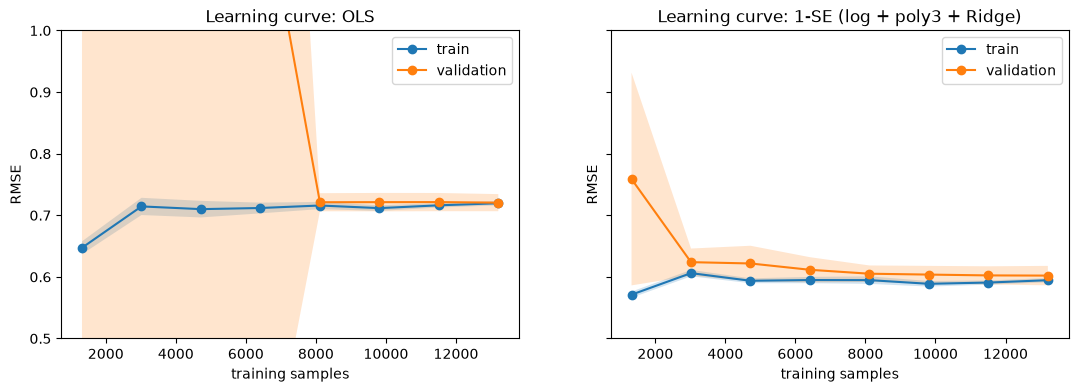

OLS                         1-SE (log + poly3 + Ridge)                  \
       n   train     val val_std                          n   train     val   
0   1320  0.6473  2.1438  1.7874                       1320  0.5712  0.7589   
1   3019  0.7144  1.7084  1.9764                       3019  0.6061  0.6239   
2   4717  0.7100  1.6704  1.8934                       4717  0.5937  0.6218   
3   6415  0.7119  1.2535  1.0512                       6415  0.5949  0.6115   
4   8114  0.7159  0.7212  0.0147                       8114  0.5948  0.6052   
5   9812  0.7116  0.7213  0.0150                       9812  0.5888  0.6038   
6  11510  0.7162  0.7214  0.0148                      11510  0.5908  0.6024   
7  13209  0.7196  0.7205  0.0139                      13209  0.5946  0.6021   

           
  val_std  
0  0.1726  
1  0.0221  
2  0.0288  
3  0.0205  
4  0.0134  
5  0.0141  
6  0.0148  
7  0.0158

In [30]:
# 學習曲線：再多一點資料會更好嗎？（OLS vs 1-SE 模型）
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
lc = {}
for ax, (name, m) in zip(
    axes,
    [
        ("OLS", make_pipeline(StandardScaler(), LinearRegression())),
        ("1-SE (log + poly3 + Ridge)", model_1se),
    ],
):
    sizes, tr, va = learning_curve(
        m,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        train_sizes=np.linspace(0.1, 1.0, 8),
        n_jobs=-1,
    )
    tr, va = -tr, -va
    for label, s in [("train", tr), ("validation", va)]:
        ax.plot(sizes, s.mean(1), "o-", label=label)
        ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
    ax.set_ylim(0.5, 1.0)
    ax.set_xlabel("training samples")
    ax.set_ylabel("RMSE")
    ax.set_title(f"Learning curve: {name}")
    ax.legend()
    lc[name] = pd.DataFrame(
        {"n": sizes, "train": tr.mean(1), "val": va.mean(1), "val_std": va.std(1)}
    )
plt.show()
display(pd.concat(lc, axis=1).round(4))

### TODO 16（問答）

> **(1)** 學習曲線：
>
> **(a)** OLS：$n \ge 8{,}000$ 之後 train 與 val 各多少？再加資料有用嗎？
>
> **(b)** n = 1,320 時 OLS 的 val RMSE 是 2.14 ± 1.79 —— 連一次的線性模型也爆掉了。用 TODO 13 (2) 解釋。
>
> **(c)** 1-SE 模型：train 與 val 的差距多大？瓶頸變成什麼？

**(a)** train 約 0.71–0.72、val 約 0.72，兩條線已經貼在一起而且是平的 → 再加資料不會進步。這是**高偏差**的典型學習曲線：模型能力已經用完了，要的是更多容量（或更好的特徵），不是更多資料。

**(b)** 樣本少時，訓練集更可能「沒抽到」某個極端值（例如 AveOccup 1,243），而它出現在驗證 fold 時，線性項 $w \cdot x$ 一樣會外插出很大的誤差。資料多到 8,000 筆以上，訓練集幾乎一定包含各種極端值，係數在那些方向也被約束住了 → 標準差從 1.8 降到 0.015。

- 推論：**極端值造成的問題，會在小樣本、高次項、或兩者同時出現時放大**。

**(c)** train 0.595、val 0.602，差 0.007；val 從 $n \approx 5{,}000$ 起就幾乎不再下降 → 又回到「偏差為主」，只是偏差小了很多（val 0.72 → 0.60）。

- 剩下的瓶頸：截斷的 y（TODO 1 (1)，模型修不了標籤的偏差）、地理位置仍只能用多項式曲面近似（待補強：到海岸／城市的距離）、以及線性模型 + 多項式這個函數族本身（第 8、10 章的樹模型可以學任意的交互作用）。


---
## 6. 測試集評估

模型都已經用 CV 決定好，測試集只評估一次。

- `regression_metrics(y_true, y_pred)`：回傳 MAE、RMSE、$R^2$、MAPE（平均絕對百分比誤差，$\frac{100}{n}\sum_i \lvert e_i / y_i\rvert$）。
- `log_result(benchmark, 模型名, 指標, **參數)`：把一筆成績加到 `results/<benchmark>.csv`；`compare(benchmark, "rmse", higher_is_better=False)`：依 RMSE 由小到大列出各模型（同名模型只留最新一筆）並畫長條圖。

,mae,rmse,r2,mape
Dummy mean,0.9061,1.1449,-0.0002,62.8861
LinReg normal-eq (scratch),0.5332,0.7456,0.5758,31.9522
LinReg GD (scratch),0.5332,0.7456,0.5758,31.9518
Ridge a=1 (scratch),0.5332,0.7456,0.5758,31.9512
LinearRegression (sklearn),0.5332,0.7456,0.5758,31.9522
Ridge a=1 (sklearn),0.5332,0.7456,0.5758,31.9512
Lasso a=0.01 (sklearn),0.5353,0.7404,0.5816,32.0066
Lasso a=0.1 (sklearn),0.6222,0.8244,0.4814,39.9724
ElasticNet a=0.01 (sklearn),0.5341,0.7416,0.5803,31.9413
"Ridge poly3 + log (1-SE, sklearn)",0.4331,0.6054,0.7203,26.0820


,model,rmse,time,mae,r2,mape,params,notes
0,Tobit poly3 + log (scratch),0.6026,2026-10-25 13:43,0.4272,0.7229,26.0184,"{""c"": 5.0, ""alpha"": 10.0, ""pred"": ""E[min(y*,c)]""}",NaN
1,"Ridge poly3 + log (1-SE, sklearn)",0.6054,2026-10-28 07:58,0.4331,0.7203,26.0820,"{""tf"": ""log"", ""degree"": 3, ""alpha"": 10.0}",NaN
2,Tobit (scratch),0.7235,2026-10-25 13:43,0.5256,0.6006,31.7683,"{""c"": 5.0, ""alpha"": 0.0, ""pred"": ""E[min(y*,c)]""}",NaN
3,Lasso a=0.01 (sklearn),0.7404,2026-10-28 07:58,0.5353,0.5816,32.0066,NaN,NaN
4,ElasticNet a=0.01 (sklearn),0.7416,2026-10-28 07:58,0.5341,0.5803,31.9413,NaN,NaN
5,LinReg normal-eq (scratch),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9522,"{""scaled"": true}",NaN
6,LinReg GD (scratch),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9518,"{""lr"": 0.1, ""epochs"": 776}",NaN
7,Ridge a=1 (scratch),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9512,"{""alpha"": 1.0}",NaN
8,LinearRegression (sklearn),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9522,NaN,NaN
9,Ridge a=1 (sklearn),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9512,NaN,NaN


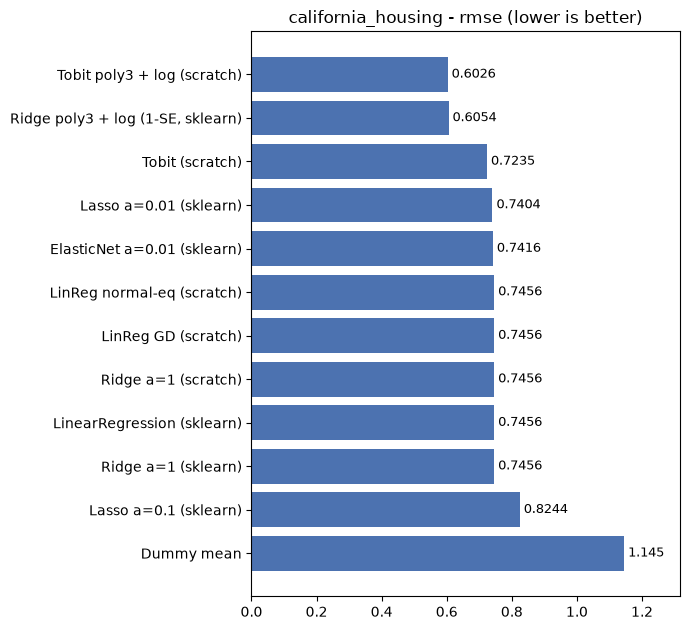

In [31]:
from learning_map.results import compare, log_result

BENCH = "california_housing"

# 名稱: (模型, 對應的測試資料, 要記下的參數)
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
eval_models = {
    "Dummy mean": (dummy, X_test, {}),
    "LinReg normal-eq (scratch)": (ne_s, X_test_s, {"scaled": True}),
    "LinReg GD (scratch)": (
        gd,
        X_test_s,
        {"lr": gd.lr, "epochs": len(gd.loss_history_)},
    ),
    "Ridge a=1 (scratch)": (ridge_s, X_test_s, {"alpha": ridge_s.alpha}),
}
for name, m in sk_models.items():
    eval_models[name] = (m, X_test, {})  # sklearn pipeline 吃原始資料
eval_models["Ridge poly3 + log (1-SE, sklearn)"] = (
    model_1se,
    X_test,
    {
        "tf": choice["tf"],
        "degree": int(choice["degree"]),
        "alpha": float(choice["alpha"]),
    },
)

test_scores = {}
for name, (m, X, params) in eval_models.items():
    metrics = regression_metrics(y_test, m.predict(X))
    test_scores[name] = metrics
    log_result(BENCH, name, metrics, **params)

display(pd.DataFrame(test_scores).T)
compare(BENCH, "rmse", higher_is_better=False)

---
## 7. 診斷

上排是 OLS（第 3、4 節），下排是調參後的 1-SE 模型（log + 3 次多項式 + Ridge）。

#### 本節名詞

- **OLS**（ordinary least squares，普通最小平方法）：不加正則化的線性回歸，也就是 3A 的正規方程解。
- **殘差**（這一節）：**實際 − 預測** $= y_i - \hat y_i$（程式 `resid = y_test - y_pred`）。殘差 > 0 代表模型**低估**。（3B 程式裡的 `residual` 是預測 − 實際，正負號相反。）
- **predicted vs actual 圖**：橫軸實際、縱軸預測；完美的模型所有點都在紅色虛線 $y = x$ 上。
- **殘差圖**：橫軸預測值、縱軸殘差；好的模型殘差應該在 0 上下隨機散布、沒有形狀。
- **異質變異**（heteroscedasticity）：殘差的散布程度隨預測值改變（例如預測越大、殘差越分散，看起來像扇形）。反義詞是同質變異（每個地方散布程度一樣）。
- **截斷樣本**：測試集裡 $y \ge 5$ 的樣本（`censored`），真實房價只知道 ≥ 50 萬美元。
- 統計表的「殘差標準差（依預測值五分位）」：用 `pd.qcut` 依預測值由小到大分成 5 組（每組筆數相同），各算殘差的標準差。

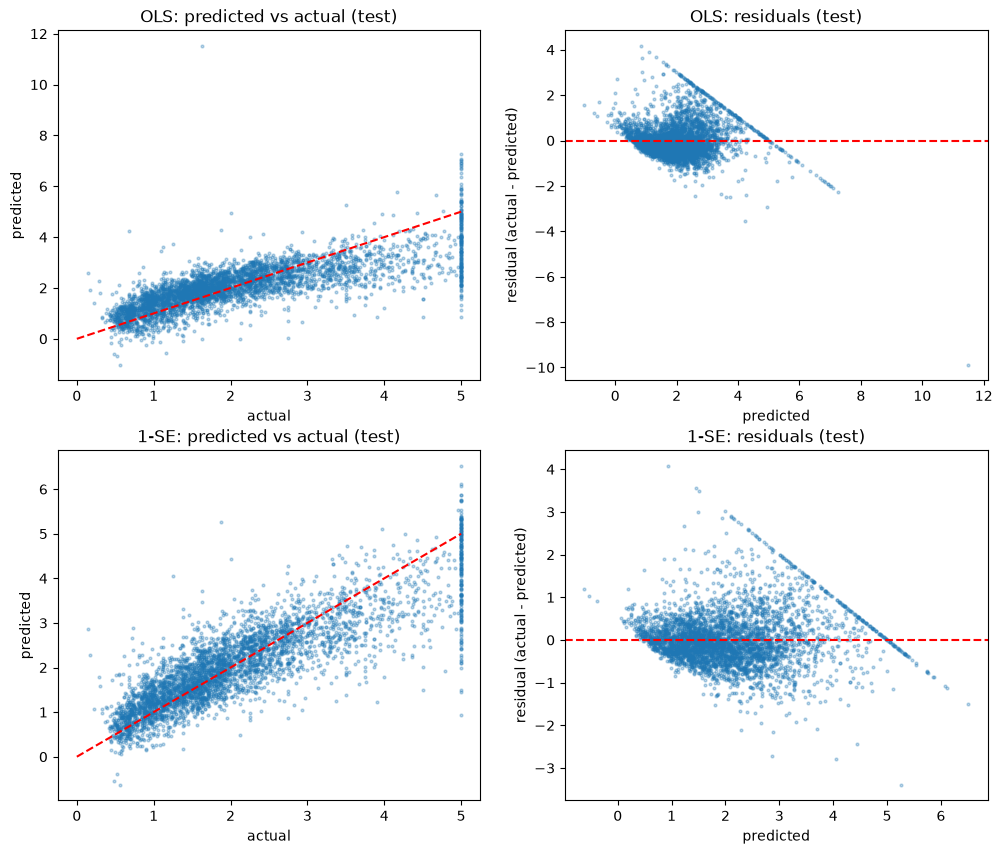

測試集截斷樣本（y ≥ 5）：184 筆


,負房價預測筆數,最大預測值,截斷樣本的平均殘差,非截斷樣本 RMSE,殘差標準差（依預測值五分位）
OLS,15,11.5,1.153,0.6578,"[0.581, 0.569, 0.713, 0.843, 0.926]"
1-SE,3,6.51,0.847,0.5483,"[0.382, 0.486, 0.587, 0.694, 0.782]"


In [32]:
# 診斷圖：預測 vs 實際、殘差（測試集）
diag_models = {"OLS": ne_s.predict(X_test_s), "1-SE": model_1se.predict(X_test)}
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for row, (name, y_pred) in zip(axes, diag_models.items()):
    resid = y_test - y_pred
    row[0].scatter(y_test, y_pred, s=4, alpha=0.3)
    row[0].plot([0, 5], [0, 5], "r--")
    row[0].set_xlabel("actual")
    row[0].set_ylabel("predicted")
    row[0].set_title(f"{name}: predicted vs actual (test)")
    row[1].scatter(y_pred, resid, s=4, alpha=0.3)
    row[1].axhline(0, color="r", ls="--")
    row[1].set_xlabel("predicted")
    row[1].set_ylabel("residual (actual - predicted)")
    row[1].set_title(f"{name}: residuals (test)")
plt.show()

censored = (y_test >= 5).to_numpy()
rows = {}
for name, y_pred in diag_models.items():
    resid = (y_test - y_pred).to_numpy()
    quintile = pd.qcut(y_pred, 5, labels=False)
    rows[name] = {
        "負房價預測筆數": int((y_pred < 0).sum()),
        "最大預測值": round(float(y_pred.max()), 2),
        "截斷樣本的平均殘差": round(float(resid[censored].mean()), 3),
        "非截斷樣本 RMSE": round(float(np.sqrt((resid[~censored] ** 2).mean())), 4),
        "殘差標準差（依預測值五分位）": pd.Series(resid)
        .groupby(quintile)
        .std()
        .round(3)
        .tolist(),
    }
print(f"測試集截斷樣本（y ≥ 5）：{censored.sum()} 筆")
display(pd.DataFrame(rows).T)

### TODO 17（問答）本章總結

> **(1)** 右邊 actual = 5 那一排發生什麼事？跟 EDA 的截斷有什麼關係？

- actual = 5 處形成一條垂直柱：這些樣本真實房價 ≥ 50 萬美元，但標籤被截斷（censored）記為 5.00001。
- 模型對它們的預測分散在約 2～6 之間、多數低於 5 → 系統性低估。
- 問題不在「外推」，而在訓練標籤本身有偏：被壓低的 y 會把回歸斜率往下拉，連帶影響其他高價區的預測。
- 處理方式：移除截斷樣本（簡單但會偏離真實分布）、或用 censored regression（如 Tobit）明確建模上限。
  - **修正：** 移除截斷樣本並不能修正偏差：依 y 篩選樣本，留下來的高價街區都是「剛好沒破 5」的，一樣低估（第 7B 節 TODO 18 (1)(c)、TODO 20）。Tobit 的實作與實驗見第 7B 節。

> **(2)** 殘差圖有沒有明顯的「結構」（斜線、扇形）？有結構代表模型漏掉了什麼？

兩種結構：

① **左上到右下、斜率 −1 的直線**：即 (1) 的截斷樣本。actual 固定為 5，殘差 $= 5 - \hat{y}$，故對 $\hat{y}$ 作圖必為斜率 −1 的直線；這是標籤截斷的假象，而非模型漏抓的特徵關係。

② **扇形**：$\hat{y}$ 越大殘差離散程度越大 → 異質變異（heteroscedasticity），違反 OLS「誤差變異為常數」的假設，使係數的標準誤與信賴區間失準（點估計仍不偏）。常見對策是對 y 取 log（或 Box-Cox）以穩定變異，而非加高次項；漏掉非線性項通常表現為殘差對 $\hat{y}$ 呈彎曲趨勢（如 U 形）。

另：測試集出現 15 筆負房價預測，線性模型輸出無正值約束；$\log(y)$ 轉換也能一併解決。

> **(3)** 這份資料線性模型的 $R^2$ 大概卡在多少？你覺得瓶頸是模型還是特徵？

合理正則化下的線性模型 test $R^2 \approx 0.58$（$\text{RMSE} \approx 0.74$，約 7.4 萬美元）；Lasso $\alpha = 0.1$ 的 0.48 是過度正則化（欠擬合）造成，不代表線性模型上限。

瓶頸是「線性模型 × 原始特徵」的組合 —— 即 y 與特徵的關係非線性，而線性模型只能表達原始特徵的線性組合：

- 經緯度只能形成一個平面（如「越往北越便宜」），無法表達「靠海」或舊金山／洛杉磯等高價聚落；
- MedInc 與 y 有飽和、截斷等非線性；Rooms／Occup 等有極端值與長尾。

兩條改進路線：

1. 保留線性模型、改善特徵：$\log(y)$、log／分箱處理長尾特徵、多項式與交互作用項、經緯度分群或到海岸／城市的距離；
2. 改用能自動學習非線性與交互作用的模型：樹模型（Random Forest、GBDT）在此資料 $R^2$ 可達 0.8 以上。

**補充（第 5 節驗證）**：路線 1 確實有效 —— 長尾特徵取 log1p ＋ 3 次多項式 ＋ Ridge（$\alpha = 10$），test $R^2$ 從 0.576 升到 0.720、RMSE 0.746 → 0.605，仍然是「線性模型」（對 164 個展開後的特徵是線性的）。瓶頸的確主要在「原始特徵的形式」，而不是線性回歸這個方法本身。

> **(4)（補寫）** 比較上下兩排與下方的統計表：調參後的模型改善了哪些問題？哪些問題完全沒有改善？為什麼？

| | OLS | 1-SE | 說明 |
| --- | --- | --- | --- |
| 負房價預測 | 15 筆 | 3 筆 | 曲面比平面更能貼合低價區；但輸出仍沒有正值約束 |
| 最大預測值 | 11.5 | 6.5 | 少了極端外插（log 讓極端街區不再被線性項放大） |
| 截斷樣本平均殘差 | +1.15 | +0.85 | 仍然系統性低估：標籤本身被壓在 5，換模型修不了 |
| 非截斷樣本 RMSE | 0.658 | 0.548 | 一般樣本的改善最明顯 |
| 殘差標準差（低 → 高預測值） | 0.58 → 0.93 | 0.38 → 0.78 | 整體變小，但「預測越高、誤差越大」的扇形還在 |

- **改善的**：模型能力相關的問題 —— 非線性（MedInc 的彎曲、地理位置）、極端值的外插。
- **沒改善的**：資料本身的問題 —— ① **截斷**：斜率 −1 的那條線還在，只是往左移（預測值變大了一點，但真值仍被記成 5）；② **異質變異**：高價區的房價本來就比低價區更分散（同樣 ±10% 的波動，50 萬的房子是 ±5 萬、10 萬的房子只有 ±1 萬），這是 y 的尺度性質，要靠對 y 取 log（`TransformedTargetRegressor`）處理，而不是加特徵。
- → 第 5 節調的是 $x$ 那一側；剩下的問題都在 $y$ 那一側（待補強）。

---
## 7B. 截斷資料：Tobit 回歸（補寫）

第 7 節確認了：截斷樣本在殘差圖上留下斜率 −1 的線、平均殘差 +0.85～+1.15，而且調參、換特徵都修不了（問題在 y 那一側）。這一節直接對截斷建模（觀念見 TODO 1 (1)(b) 補充）。

#### 前置複習：這一節用到的機率

| 名詞 | 定義 | 例子／備註 |
| --- | --- | --- |
| 常態分布 $N(\mu, \sigma^2)$ | 平均 $\mu$、標準差 $\sigma$ 的鐘形分布 | 約 68% 落在 $\mu \pm \sigma$、95% 落在 $\mu \pm 2\sigma$ |
| $\phi(z)$ | 標準常態（$\mu = 0$、$\sigma = 1$）的**機率密度** $\frac{1}{\sqrt{2\pi}}e^{-z^2/2}$ | $\phi(0) \approx 0.399$；程式 `norm.pdf` |
| $\Phi(z)$ | 標準常態的**累積機率** $P(Z \le z)$ | $\Phi(0) = 0.5$、$\Phi(1.96) \approx 0.975$；$1 - \Phi(z) = \Phi(-z)$；程式 `norm.cdf`，$1 - \Phi$ 是 `norm.sf` |
| 標準化 | $Y \sim N(\mu, \sigma^2)$ 時，$P(Y \le c) = \Phi\!\left(\frac{c - \mu}{\sigma}\right)$ | — |
| 似然（likelihood） | 給定參數時，「觀察到手上這批資料」的機率（連續值用密度）；樣本獨立時是每筆的乘積，取 log 變成加總 | — |
| 最大概似估計（MLE） | 找讓似然最大（＝負對數似然 NLL 最小）的參數 | OLS = 誤差為常態時的 MLE：$-\log\phi$ 就是 $\frac{1}{2}z^2$ + 常數 |
| 條件期望 $E[y \mid x]$ | 特徵等於 $x$ 的那些樣本，$y$ 的平均 | 最小化 MSE 的預測就是它 |
| 潛在變數 $y^*$ | 存在、但沒被完整觀察到的量 | 這裡是「沒被壓在 5 的真實房價」 |
| `scipy.optimize.minimize` | 給函數（與梯度），用迭代法找最小值；`method="L-BFGS-B"` 是只用梯度、會自己估計曲率的準牛頓法 | `jac=True`：函數同時回傳（值, 梯度） |
| `log_ndtr(u)` | 數值穩定的 $\log\Phi(u)$ | $u$ 很負時 $\Phi(u)$ 會下溢成 0，直接取 log 變成 $-\infty$ |

**模型**：潛在的真實房價 $y_i^* = w \cdot x_i + b + \varepsilon_i$，$\varepsilon_i \sim N(0, \sigma^2)$；資料記錄的是 $y_i = \min(y_i^*, c)$，$c = 5$。

- 這一節把 $y \ge 5$ 都當成截斷：786 筆 5.00001，加上 22 筆剛好 5.0（多半也是被壓在上限的），train 共 808 筆。

**似然函數**：記 $\mu_i = w \cdot x_i + b$，每筆樣本依「知道多少」貢獻不同的項：

- 未截斷（$y_i < c$）：知道確切值 → 常態密度 $\frac{1}{\sigma}\,\phi\!\left(\frac{y_i - \mu_i}{\sigma}\right)$
- 截斷（$y_i \ge c$）：只知道 $y_i^* \ge c$ → 機率 $P(y_i^* \ge c) = \Phi\!\left(\frac{\mu_i - c}{\sigma}\right)$

記 $z_i = (y_i - \mu_i)/\sigma$、$u_i = (\mu_i - c)/\sigma$，最小化負對數似然（NLL）：

$$\text{NLL} = \sum_{\text{未截斷}} \left[\log\sigma + \tfrac12 z_i^2 + \tfrac12\log 2\pi\right] \;-\; \sum_{\text{截斷}} \log\Phi(u_i) \;+\; \frac{\alpha\|w\|^2}{2\sigma^2}$$

- 最後一項是 L2 懲罰。沒有截斷樣本時，固定 $\sigma$ 下 NLL 等於 $\frac{1}{2\sigma^2}\left(\|y - Xw - b\|^2 + \alpha\|w\|^2\right)$ + 常數，跟 sklearn `Ridge(alpha)` **同一個解** → $\alpha$ 的意義跟第 5 節相同，可以直接沿用 $\alpha = 10$。
- 沒有閉式解（$\log\Phi$ 不是二次函數）→ 只能迭代求解。這裡交給 `scipy.optimize.minimize(method="L-BFGS-B")`，梯度自己算。

**梯度**：先對 $\mu_i$ 微分，再用連鎖律 $\partial\mu_i/\partial w = x_i$、$\partial\mu_i/\partial b = 1$。記 $\lambda(u) = \phi(u)/\Phi(u)$（inverse Mills ratio）：

| | $\partial\,\text{NLL}_i / \partial \mu_i$ | $\partial\,\text{NLL}_i / \partial \log\sigma$ |
| --- | --- | --- |
| 未截斷 | $-z_i / \sigma$ | $1 - z_i^2$ |
| 截斷 | $-\lambda(u_i) / \sigma$ | $\lambda(u_i)\, u_i$ |
| 懲罰項 | 對 $w$：$\alpha w / \sigma^2$ | $-\alpha\|w\|^2 / \sigma^2$ |

- 未截斷那列就是 OLS 的梯度（$-z_i/\sigma \propto \hat y_i - y_i$）。
- 截斷那列：$\mu_i$ 遠高於 $c$ 時 $u_i \to +\infty$、$\lambda \to 0$，梯度消失 →「預測超過 5」不會被罰；$\mu_i$ 低於 $c$ 時 $\lambda(u) \approx -u$，越低推力越大 → 把預測往上推。這就是「$y^* \ge 5$」這個不等式的梯度版本。
- 參數用 $\log\sigma$ 而不是 $\sigma$：保證 $\sigma > 0$，最佳化時不用加限制。

**預測**有兩種，回答不同的問題：

- $\mu = w \cdot x + b$：**真實房價** $y^*$ 的估計，可以超過 5。
- $E[\min(y^*, c) \mid x] = \mu\,\Phi(a) - \sigma\,\phi(a) + c\,\big(1 - \Phi(a)\big)$，$a = (c - \mu)/\sigma$：**資料會記成多少**的期望值，一定 < 5。跟記錄下來的標籤算 RMSE 時用這個才公平。

In [33]:
from typing import Literal
from scipy.optimize import check_grad, minimize
from scipy.special import log_ndtr
from scipy.stats import norm


class TobitRegression:
    """右截斷（上限 c）的 Tobit 回歸：y = min(y*, c)，y* = w·x + b + ε，ε ~ N(0, σ²)。

    懲罰項 α‖w‖² / (2σ²)（bias 不懲罰）：沒有截斷樣本時，w、b 與 Ridge(alpha) 相同。
    """

    def __init__(
        self,
        c: float = 5.0,
        alpha: float = 0.0,
        init: Literal["ridge", "zeros"] = "ridge",
    ) -> None:
        self.c = c
        self.alpha = alpha
        self.init = (
            init  # 最佳化起點："ridge" = 把截斷值當真值的 Ridge 解；"zeros" = w、b 全 0
        )

    def _nll_and_grad(
        self, theta: np.ndarray, X: np.ndarray, y: np.ndarray, cens: np.ndarray
    ) -> tuple[float, np.ndarray]:
        """theta = [b, w (d,), log σ]，cens 是 y ≥ c 的布林遮罩 (n,)。回傳（平均 NLL, 梯度 (d + 2,)）。"""
        b, w, log_s = theta[0], theta[1:-1], theta[-1]
        s = np.exp(log_s)
        mu = X @ w + b

        z = (y[~cens] - mu[~cens]) / s  # 未截斷：標準化殘差
        u = (mu[cens] - self.c) / s  # 截斷：預測超過 c 幾個 σ
        log_Phi = log_ndtr(u)  # log Φ(u)；u 很負時比 np.log(norm.cdf(u)) 穩定
        lam = np.exp(norm.logpdf(u) - log_Phi)  # inverse Mills ratio λ(u) = φ(u) / Φ(u)
        ww = w @ w

        nll = (
            (~cens).sum() * (log_s + 0.5 * np.log(2 * np.pi))
            + 0.5 * (z**2).sum()
            - log_Phi.sum()
            + self.alpha * ww / (2 * s**2)
        )

        g_mu = np.empty(len(y))  # ∂NLL_i / ∂μ_i
        g_mu[~cens] = -z / s
        g_mu[cens] = -lam / s
        grad_b = g_mu.sum()
        grad_w = X.T @ g_mu + self.alpha * w / s**2
        grad_log_s = (1 - z**2).sum() + (lam * u).sum() - self.alpha * ww / s**2
        n = len(y)
        return nll / n, np.r_[grad_b, grad_w, grad_log_s] / n

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,)，y ≥ c 視為截斷。學到 w_ (d,)、b_、sigma_，回傳 self。"""
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        cens = y >= self.c
        if self.init == "ridge":
            start = RidgeNE(self.alpha).fit(X, y)  # 第 3C 節的手寫 Ridge
            b0, w0 = start.b_, start.w_
        else:
            b0, w0 = 0.0, np.zeros(X.shape[1])
        theta0 = np.r_[b0, w0, np.log(np.std(y - X @ w0 - b0))]
        self.opt_ = minimize(
            self._nll_and_grad,
            theta0,
            args=(X, y, cens),
            jac=True,
            method="L-BFGS-B",
            options={"maxiter": 10_000},
        )
        self.b_, self.w_, self.sigma_ = (
            self.opt_.x[0],
            self.opt_.x[1:-1],
            float(np.exp(self.opt_.x[-1])),
        )
        return self

    def predict(self, X: ArrayLike) -> np.ndarray:
        """潛在真值的估計 μ = w·x + b，shape (n,)；可以超過 c。"""
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

    def predict_observed(self, X: ArrayLike) -> np.ndarray:
        """記錄值的期望 E[min(y*, c) | x]，shape (n,)；一定 < c。"""
        mu = self.predict(X)
        a = (self.c - mu) / self.sigma_
        return mu * norm.cdf(a) - self.sigma_ * norm.pdf(a) + self.c * norm.sf(a)


# ✅ 檢查 1：解析梯度 vs 數值梯度（隨機參數；含截斷樣本與懲罰項）
rng = np.random.default_rng(0)
X_chk, y_chk = X_train_s[:500], y_train.to_numpy()[:500]
tob_chk = TobitRegression(c=5.0, alpha=3.0)
cens_chk = y_chk >= tob_chk.c
theta_chk = rng.normal(scale=0.5, size=X_chk.shape[1] + 2)
grad_err = check_grad(
    lambda t: tob_chk._nll_and_grad(t, X_chk, y_chk, cens_chk)[0],
    lambda t: tob_chk._nll_and_grad(t, X_chk, y_chk, cens_chk)[1],
    theta_chk,
)
print(f"這 500 筆裡的截斷樣本：{cens_chk.sum()} 筆")
print("✅ 梯度檢查（解析 vs 數值）：", grad_err, "（應 < 1e-5）")

# ✅ 檢查 2：c = ∞（沒有任何截斷）時應等於 Ridge；從 w = 0 出發，確認最佳化真的會走到 Ridge 解
for a in [0.0, 10.0]:
    t_inf = TobitRegression(c=np.inf, alpha=a, init="zeros").fit(X_train_s, y_train)
    r = RidgeNE(a).fit(X_train_s, y_train)
    print(
        f"✅ c=∞、alpha={a:>4}：與 RidgeNE 係數最大差異 {np.abs(np.r_[t_inf.b_ - r.b_, t_inf.w_ - r.w_]).max():.1e}"
        "（應 < 1e-4）"
    )

這 500 筆裡的截斷樣本：24 筆
✅ 梯度檢查（解析 vs 數值）： 3.930235112487684e-07 （應 < 1e-5）
✅ c=∞、alpha= 0.0：與 RidgeNE 係數最大差異 3.6e-06（應 < 1e-4）
✅ c=∞、alpha=10.0：與 RidgeNE 係數最大差異 7.3e-06（應 < 1e-4）


截斷比例：24.2%（x > 3 的區段：79.0%）


,slope,intercept
OLS (censored as-is),0.822,1.195
OLS (drop censored),0.868,1.120
Tobit,0.999,0.995
OLS on y* (unobservable),1.005,0.988


Tobit 估計的 σ： 0.504 （真值 0.5）


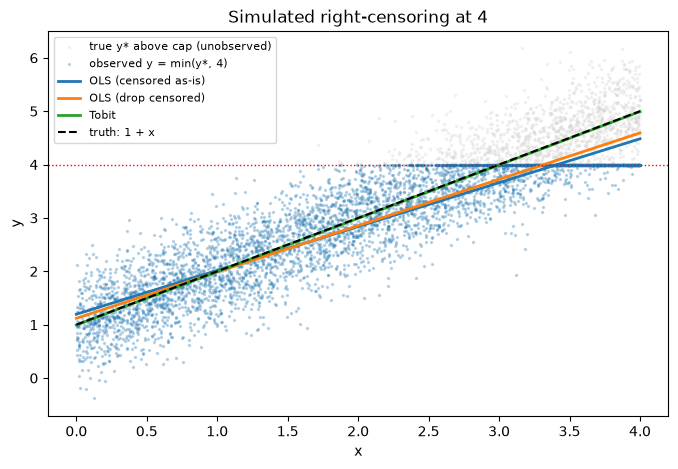

In [34]:
# 模擬：已知真值的資料，看 OLS（照常）、OLS（刪除截斷）、Tobit 誰估得對
rng = np.random.default_rng(42)
n_sim, c_sim = 5_000, 4.0
x_sim = rng.uniform(0, 4, n_sim)
y_star = 1.0 + 1.0 * x_sim + rng.normal(0, 0.5, n_sim)  # 真值：截距 1、斜率 1、σ = 0.5
y_obs = np.minimum(y_star, c_sim)  # 記錄值：超過 4 都記成 4
cens_sim = y_obs >= c_sim
X_sim = x_sim[:, None]

sim_fits = {
    "OLS (censored as-is)": LinearRegressionNE().fit(X_sim, y_obs),
    "OLS (drop censored)": LinearRegressionNE().fit(X_sim[~cens_sim], y_obs[~cens_sim]),
    "Tobit": TobitRegression(c=c_sim).fit(X_sim, y_obs),
    "OLS on y* (unobservable)": LinearRegressionNE().fit(X_sim, y_star),
}
print(
    f"截斷比例：{cens_sim.mean():.1%}（x > 3 的區段：{cens_sim[x_sim > 3].mean():.1%}）"
)
display(
    pd.DataFrame(
        {name: {"slope": m.w_[0], "intercept": m.b_} for name, m in sim_fits.items()}
    ).T.round(3)
)
print("Tobit 估計的 σ：", round(sim_fits["Tobit"].sigma_, 3), "（真值 0.5）")

grid = np.linspace(0, 4, 50)[:, None]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    x_sim[cens_sim],
    y_star[cens_sim],
    s=2,
    alpha=0.25,
    color="lightgray",
    label="true y* above cap (unobserved)",
)
ax.scatter(x_sim, y_obs, s=2, alpha=0.25, label="observed y = min(y*, 4)")
for name in ["OLS (censored as-is)", "OLS (drop censored)", "Tobit"]:
    ax.plot(grid, sim_fits[name].predict(grid), lw=2, label=name)
ax.plot(grid, 1 + grid[:, 0], "k--", lw=1.5, label="truth: 1 + x")
ax.axhline(c_sim, color="r", ls=":", lw=1)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Simulated right-censoring at 4")
ax.legend(fontsize=8)
plt.show()

### TODO 18（問答）模擬：已知真值

> **(1)** 讀表：
>
> **(a)** 真值是斜率 1、截距 1。OLS（照常）、OLS（刪除截斷）、Tobit 的斜率各是多少？Tobit 估計的 $\sigma$ 呢？
>
> **(b)** 照常訓練為什麼斜率變平？
>
> **(c)** 刪掉截斷樣本，為什麼斜率還是變平？（提示：$x > 3$ 的區段有 79% 被截斷；留下來的 21% 是哪些樣本？）

**(a)**

| | 斜率 | 截距 |
| --- | --- | --- |
| OLS（照常） | 0.822 | 1.195 |
| OLS（刪除截斷） | 0.868 | 1.120 |
| **Tobit** | **0.999** | **0.995** |
| OLS on $y^*$（參照，現實中看不到） | 1.005 | 0.988 |

Tobit 的 $\hat\sigma = 0.504$（真值 0.5）。Tobit 跟「拿得到真值的 OLS」幾乎一樣好。

**(b)** $x$ 越大，$y^*$ 越常超過 4 而被壓成 4 → 右端的點被往下拉，直線右端下垂、左端為了平衡往上翹 → 斜率變小、截距變大。跟 TODO 1 (1)(b) 預測的一樣，只是這裡知道真值，可以量出偏多少（−18%）。

**(c)** 刪除是依 $y$ 挑樣本：在 $x = 3.5$ 附近，留下來的只有 $\varepsilon$ 剛好很負、$y^* < 4$ 的那一小群。

- 留下來的樣本平均是 $E[y^* \mid x, y^* < c] = \mu(x) - \sigma\,\dfrac{\phi(a)}{\Phi(a)}$，$a = \dfrac{c - \mu(x)}{\sigma}$；$x$ 越大、$a$ 越小，扣掉的量越大 → 一樣是右端被往下拉。
- **依 $x$ 篩選樣本不會造成偏差，依 $y$ 篩選就會**（selection on the outcome）：前者只是縮小 $x$ 的範圍，後者改變了每個 $x$ 底下 $y$ 的分布。

> **(2)** Tobit 為什麼估得對？
>
> **(a)** 它用到哪些假設？在這個模擬裡，這些假設成立嗎？
>
> **(b)** OLS 求 $w$ 不需要知道 $\sigma$（$\sigma$ 不影響 argmin）。Tobit 為什麼一定要把 $\sigma$ 一起估？

**(a)** 線性的 $\mu(x)$、常態誤差、所有樣本同一個 $\sigma$（同質變異）。模擬資料就是照這三個假設生成的，所以 Tobit 是「正確的模型」，估得準是理所當然。真實資料不一定成立 → TODO 19 (2)(c)。

**(b)** 截斷項是 $\Phi\!\left(\frac{\mu_i - c}{\sigma}\right)$：要把「預測比上限低 0.3」換算成「真值超過上限的機率」，必須知道誤差的尺度。$\sigma = 0.1$ 時低 0.3 是 3 個標準差，幾乎不可能超過上限；$\sigma = 2$ 時只是 0.15 個標準差，超過上限的機率將近一半。→ $w$ 與 $\sigma$ 必須聯合估計（OLS 的 $\sigma$ 在平方誤差裡只是個共同的倍數，所以可以分開）。

In [35]:
# California：OLS（照常）vs OLS（刪除截斷）vs Tobit —— 原始 8 個特徵（標準化）
C = 5.0
cens_tr = (y_train >= C).to_numpy()
cens_te = (y_test >= C).to_numpy()  # 跟第 7 節的 censored 相同
print(
    f"截斷樣本：train {cens_tr.sum()} 筆（{cens_tr.mean():.1%}）、test {cens_te.sum()} 筆"
)

ols_drop = LinearRegressionNE().fit(X_train_s[~cens_tr], y_train[~cens_tr])
tobit = TobitRegression(c=C).fit(X_train_s, y_train)
print(
    "Tobit 收斂：",
    tobit.opt_.success,
    "  迭代次數：",
    tobit.opt_.nit,
    "  σ =",
    round(tobit.sigma_, 4),
)

# 截斷樣本集中在哪？（對照下表哪些係數變最多）
print(
    "截斷樣本 vs 全部：MedInc 平均",
    round(float(X_train["MedInc"][cens_tr].mean()), 2),
    "vs",
    round(float(X_train["MedInc"].mean()), 2),
)

coef_t = pd.DataFrame(
    {"OLS": ne_s.w_, "OLS (drop censored)": ols_drop.w_, "Tobit": tobit.w_},
    index=feature_names,
)
coef_t.loc["(bias)"] = [ne_s.b_, ols_drop.b_, tobit.b_]
coef_t["Tobit / OLS"] = coef_t["Tobit"] / coef_t["OLS"]
display(coef_t.round(3))

截斷樣本：train 808 筆（4.9%）、test 184 筆
Tobit 收斂： True   迭代次數： 17   σ = 0.7361
截斷樣本 vs 全部：MedInc 平均 7.74 vs 3.88


,OLS,OLS (drop censored),Tobit,Tobit / OLS
MedInc,0.854,0.840,1.007,1.179
HouseAge,0.123,0.104,0.151,1.235
AveRooms,-0.294,-0.288,-0.401,1.361
AveBedrms,0.339,0.311,0.433,1.276
Population,-0.002,0.009,-0.004,1.631
AveOccup,-0.041,-0.037,-0.046,1.116
Latitude,-0.897,-0.805,-0.827,0.922
Longitude,-0.870,-0.788,-0.807,0.928
(bias),2.072,2.014,2.100,1.014


Tobit（1-SE 特徵）收斂： True   迭代次數： 539   σ = 0.6184


,RMSE（全部，對記錄值）,RMSE（非截斷）,截斷樣本平均預測,截斷樣本預測 ≥ 5 的比例
OLS,0.7456,0.6578,3.8471,0.1848
OLS + clip,0.7227,0.6403,3.6683,0.1848
OLS (drop censored),0.7444,0.6486,3.7331,0.1630
Tobit: mu (latent),0.7635,0.6758,4.1079,0.2989
"Tobit: E[min(y*, 5)]",0.7235,0.6484,3.7436,0.0000
1-SE Ridge,0.6054,0.5483,4.1534,0.2283
1-SE Ridge + clip,0.6028,0.5477,4.0676,0.2283
1-SE Tobit: mu (latent),0.6521,0.5588,4.7483,0.4130
"1-SE Tobit: E[min(y*, 5)]",0.6026,0.5523,4.1469,0.0000


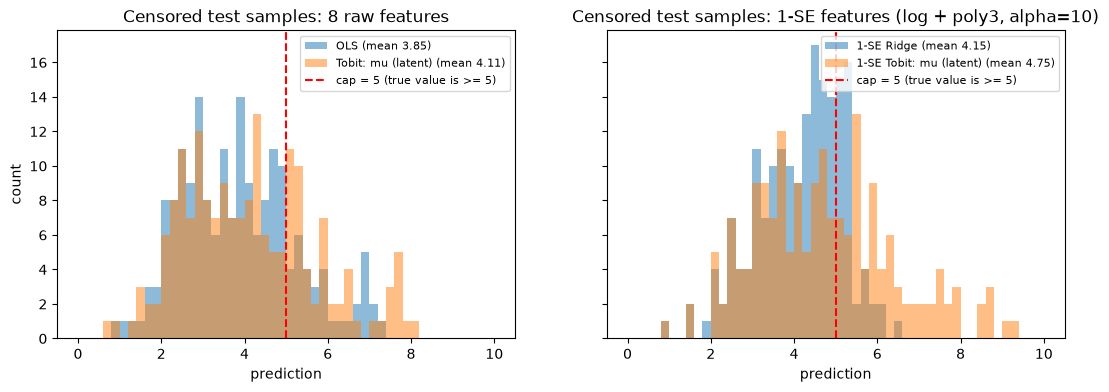

In [36]:
# 同樣的比較套到 1-SE 特徵（log1p + 3 次多項式 + 標準化，164 欄），alpha 沿用 1-SE 的 10
feat_1se = model_1se[
    :-1
]  # pipeline 去掉最後的 Ridge：只做特徵轉換（已經在 X_train 上 fit 過）
P_train, P_test = feat_1se.transform(X_train), feat_1se.transform(X_test)
alpha_1se = float(choice["alpha"])
tobit_1se = TobitRegression(c=C, alpha=alpha_1se).fit(P_train, y_train)
print(
    "Tobit（1-SE 特徵）收斂：",
    tobit_1se.opt_.success,
    "  迭代次數：",
    tobit_1se.opt_.nit,
    "  σ =",
    round(tobit_1se.sigma_, 4),
)


def censor_report(y_pred: np.ndarray) -> dict[str, float]:
    """測試集：RMSE（全部，對記錄值）、RMSE（非截斷）、截斷樣本的平均預測、截斷樣本中預測 ≥ 5 的比例。"""
    resid = y_test.to_numpy() - y_pred
    return {
        "RMSE（全部，對記錄值）": np.sqrt(np.mean(resid**2)),
        "RMSE（非截斷）": np.sqrt(np.mean(resid[~cens_te] ** 2)),
        "截斷樣本平均預測": y_pred[cens_te].mean(),
        "截斷樣本預測 ≥ 5 的比例": (y_pred[cens_te] >= C).mean(),
    }


preds_t = {
    "OLS": ne_s.predict(X_test_s),
    "OLS + clip": np.minimum(ne_s.predict(X_test_s), C),
    "OLS (drop censored)": ols_drop.predict(X_test_s),
    "Tobit: mu (latent)": tobit.predict(X_test_s),
    "Tobit: E[min(y*, 5)]": tobit.predict_observed(X_test_s),
    "1-SE Ridge": model_1se.predict(X_test),
    "1-SE Ridge + clip": np.minimum(model_1se.predict(X_test), C),
    "1-SE Tobit: mu (latent)": tobit_1se.predict(P_test),
    "1-SE Tobit: E[min(y*, 5)]": tobit_1se.predict_observed(P_test),
}
display(pd.DataFrame({k: censor_report(v) for k, v in preds_t.items()}).T.round(4))

# 截斷的測試樣本（真值 ≥ 5）被預測成多少？
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
bins = np.linspace(0, 10, 51)
for ax, (a, b, title) in zip(
    axes,
    [
        ("OLS", "Tobit: mu (latent)", "8 raw features"),
        (
            "1-SE Ridge",
            "1-SE Tobit: mu (latent)",
            "1-SE features (log + poly3, alpha=10)",
        ),
    ],
):
    ax.hist(
        preds_t[a][cens_te],
        bins=bins,
        alpha=0.5,
        label=f"{a} (mean {preds_t[a][cens_te].mean():.2f})",
    )
    ax.hist(
        preds_t[b][cens_te],
        bins=bins,
        alpha=0.5,
        label=f"{b} (mean {preds_t[b][cens_te].mean():.2f})",
    )
    ax.axvline(C, color="r", ls="--", label="cap = 5 (true value is >= 5)")
    ax.set_xlabel("prediction")
    ax.set_title(f"Censored test samples: {title}")
    ax.legend(fontsize=8)
axes[0].set_ylabel("count")
plt.show()

### TODO 19（問答）California：Tobit vs OLS

> **(1)** 係數表（原始 8 個特徵）：
>
> **(a)** 跟 OLS 比，Tobit 的 MedInc 係數變多少？哪些係數絕對值變大、哪些變小？
>
> **(b)** 截斷樣本的 MedInc 平均是 7.74（全部是 3.88）。用 TODO 18 (1)(b) 解釋為什麼 MedInc 的修正這麼明顯。
>
> **(c)** OLS（刪除截斷）的 MedInc 係數是多少？跟模擬的結論一致嗎？

**(a)** MedInc 0.854 → 1.007（+18%，跟模擬裡的 −18% 剛好是同一個量級）。HouseAge、AveRooms、AveBedrms 絕對值增加 24–36%；Latitude、Longitude 絕對值反而小約 8%。

- 係數是一起調整的：MedInc 的斜率不再被壓平後，其他係數重新分配，不必逐一解讀方向（共線性，TODO 4 (3)）。Population 的比值 1.63 沒有意義，係數本身接近 0。

**(b)** 截斷樣本幾乎都是高收入街區 → 被壓在 5 的點全部擠在 MedInc 軸的右端，正是模擬裡「右端下垂」的情況，所以被壓平最多的就是 MedInc 的斜率。

**(c)** 0.840，比照常訓練的 0.854 還小。兩種都偏低，偏多偏少看資料（模擬裡是刪除比較好一點）；但不論哪一種，**刪除都不是修正**。

> **(2)** 測試集表格：
>
> **(a)** Tobit 的 $\mu$ 對記錄值的 RMSE 是 0.7635，比 OLS 的 0.7456 還差；連「非截斷」的 RMSE 也比較差（0.676 vs 0.658）。Tobit 比較爛嗎？
>
> **(b)** 公平的比較：用 $E[\min(y^*, 5)]$ 的 RMSE 是多少？跟 OLS + clip 比呢？
>
> **(c)** 截斷樣本（真值 ≥ 5）的平均預測、預測 ≥ 5 的比例，從 OLS 到 Tobit 怎麼變？換成 1-SE 特徵呢？
>
> **(d)** 看直方圖：Tobit 修正後，1-SE 版本還有 59% 的截斷樣本被預測成 < 5。Tobit 修不到的是什麼？

**(a)** 不是，兩個 RMSE 欄位對 $\mu$ 都不公平：

- 全部：$\mu$ 估的是 $y^*$，截斷樣本的標籤卻是 5。一個真值 6.5 的街區，$\mu = 6.5$ 是對的，卻被算成誤差 1.5。
- 非截斷：只挑 $y < 5$ 的樣本來算，**就是依 $y$ 篩選**（TODO 18 (1)(c)）—— 高價區留下來的都是剛好沒破 5 的街區，平均比 $E[y^* \mid x]$ 低，所以這個指標天生偏好「預測得比較低」的模型。
- → 依 $y$ 篩選樣本，不只訓練會偏，**評估也會偏**。

**(b)**

| | 原始 8 個特徵 | 1-SE 特徵 |
| --- | --- | --- |
| OLS／Ridge | 0.7456 | 0.6054 |
| OLS／Ridge + clip | 0.7227 | 0.6028 |
| Tobit $E[\min(y^*, 5)]$ | 0.7235 | 0.6026 |

Tobit 比 OLS 好（$R^2$ 0.576 → 0.601），但 **clip 就拿到幾乎全部的改善**。對「記錄值」的分數來說，主要的好處只是「不要預測超過 5」；Tobit 的價值在別處（(c) 與 TODO 20）。

**(c)**

| | 截斷樣本平均預測 | 預測 ≥ 5 的比例 |
| --- | --- | --- |
| OLS → Tobit $\mu$ | 3.85 → 4.11 | 18% → 30% |
| 1-SE Ridge → 1-SE Tobit $\mu$ | 4.15 → 4.75 | 23% → 41% |

方向正確：截斷樣本的真值都 ≥ 5，Tobit 把預測往上推。特徵越好（1-SE），修正越大 —— 模型越能認出「這是高價街區」，Tobit 才知道要把誰往上推。

**(d)** 兩件事：

1. **模型本身的偏差**：一個街區的特徵看起來普通（直方圖左半邊被預測成 2–4 的那群），Tobit 也不會把它往上推。Tobit 修的是「標籤被壓低」這一側；模型認不出高價街區是特徵與函數形式的問題（TODO 16 (c)），兩者是不同的偏差。
2. **假設不成立**：Tobit 假設所有街區同一個 $\sigma$（這裡 $\hat\sigma = 0.74$），但 TODO 17 (2) 的扇形顯示高價區的誤差明顯比較大。截斷項的機率是靠 $\sigma$ 換算的（TODO 18 (2)(b)），$\sigma$ 錯了，修正量也跟著不準。可能的改進：對 $\log y$ 做 Tobit，或讓 $\sigma$ 跟著 $x$ 變（待補強）。

In [37]:
# 人工截斷：把 train 的 y 再壓到 c' = 3.5 或 3.0。測試集裡 c' ≤ y < 5 的樣本「被截斷、但真值已知」
#   → 可以直接檢查：只看得到截斷標籤時，誰最能把這些樣本預測對？
#   參照組「OLS on original labels」用的是原本（上限 5）的標籤 —— 資訊比其他三個多，是它們想逼近的目標。
y_tr, y_te = y_train.to_numpy(), y_test.to_numpy()
rows = []
for c_art in [3.5, 3.0]:
    y_art = np.minimum(y_tr, c_art)
    cens_art = y_art >= c_art
    known = (y_te >= c_art) & (y_te < C)  # 被人工截斷、但真值已知的測試樣本
    below = y_te < c_art
    print(
        f"c' = {c_art}：train 截斷比例 {cens_art.mean():.1%}；測試集 known 樣本 {known.sum()} 筆、y < c' 樣本 {below.sum()} 筆"
    )
    for feat_name, Xtr, Xte, a in [
        ("8 raw", X_train_s, X_test_s, 0.0),
        ("1-SE", P_train, P_test, alpha_1se),
    ]:
        fits = {
            "OLS (censored as-is)": RidgeNE(a).fit(Xtr, y_art),
            "OLS (drop censored)": RidgeNE(a).fit(Xtr[~cens_art], y_art[~cens_art]),
            "Tobit": TobitRegression(c=c_art, alpha=a).fit(Xtr, y_art),
            "ref: OLS on original labels": RidgeNE(a).fit(Xtr, y_tr),
        }
        for m_name, m in fits.items():
            p = m.predict(Xte)
            e = y_te - p
            rows.append(
                {
                    "c'": c_art,
                    "features": feat_name,
                    "model": m_name,
                    "known 平均殘差": e[known].mean(),
                    "known RMSE": np.sqrt(np.mean(e[known] ** 2)),
                    "y < c' RMSE": np.sqrt(np.mean(e[below] ** 2)),
                }
            )
art = pd.DataFrame(rows).set_index(["c'", "features", "model"])
display(art.round(3))

c' = 3.5：train 截斷比例 12.9%；測試集 known 樣本 334 筆、y < c' 樣本 3610 筆
c' = 3.0：train 截斷比例 18.8%；測試集 known 樣本 574 筆、y < c' 樣本 3370 筆


known 平均殘差  known RMSE  y < c' RMSE
c'  features model                                                           
3.5 8 raw    OLS (censored as-is)              1.372       1.495        0.517
             OLS (drop censored)               1.436       1.575        0.504
             Tobit                             1.092       1.331        0.550
             ref: OLS on original labels       1.046       1.285        0.566
    1-SE     OLS (censored as-is)              1.115       1.232        0.448
             OLS (drop censored)               1.187       1.325        0.439
             Tobit                             0.778       1.077        0.468
             ref: OLS on original labels       0.713       1.001        0.485
3.0 8 raw    OLS (censored as-is)              1.289       1.405        0.462
             OLS (drop censored)               1.348       1.476        0.445
             Tobit                             0.969       1.187        0.504
             ref: OLS on original labels       0.823       1.082        0.554
    1-SE     OLS (censored as-is)              1.097       1.209        0.406
             OLS (drop censored)               1.166       1.289        0.396
             Tobit                             0.724       0.981        0.431
             ref: OLS on original labels       0.549       0.862        0.475

### TODO 20（問答）人工截斷：真值已知的檢驗

> **(1)** 為什麼要人工截斷？真正被截斷的 184 筆測試樣本不能拿來檢驗嗎？

不能：它們的真值只知道 ≥ 5，算不出誤差。把上限人工降到 $c'$ = 3.5，$3.5 \le y < 5$ 的樣本就變成「被截斷、但真值已知」→ 跟模擬一樣有標準答案，但資料是真的（特徵分布、非線性、異質變異都在）。

> **(2)** 讀表（known 樣本 = 被人工截斷、真值已知）：
>
> **(a)** $c'$ = 3.5、原始特徵：四個模型的 known 平均殘差各是多少？
>
> **(b)** 參照組用的是原始標籤（多知道 3.5–5 之間的真值）。Tobit 只看得到截斷到 3.5 的標籤，追回了 OLS 與參照組之間差距的幾成？$c'$ = 3.0 時呢？
>
> **(c)** 參照組本身的 known 平均殘差也 > 0（0.55–1.05）。這代表什麼？

**(a)** OLS（照常）1.372、OLS（刪除）1.436、**Tobit 1.092**、參照 1.046。四組設定（2 個 $c'$ × 2 組特徵）的排名都一樣：參照 < Tobit < 照常 < 刪除。

**(b)** 追回的比例 $= \dfrac{\text{OLS} - \text{Tobit}}{\text{OLS} - \text{參照}}$（用 known 平均殘差算）：

| | 原始 8 個特徵 | 1-SE 特徵 |
| --- | --- | --- |
| $c'$ = 3.5（截斷 12.9%） | $\dfrac{1.372 - 1.092}{1.372 - 1.046} \approx 86\%$ | $\dfrac{1.115 - 0.778}{1.115 - 0.713} \approx 84\%$ |
| $c'$ = 3.0（截斷 18.8%） | $\dfrac{1.289 - 0.969}{1.289 - 0.823} \approx 69\%$ | $\dfrac{1.097 - 0.724}{1.097 - 0.549} \approx 68\%$ |

- Tobit 只用「$y^* \ge c'$」這個不等式，就追回了七到八成多的資訊。
- 截斷越多，追回越少：被截斷的樣本越多，越依賴常態、同質變異的假設去「想像」上限以上的分布，假設的誤差影響也越大。
- 刪除截斷樣本在每一組都是最差的 —— 三個實驗（模擬、真實資料、人工截斷）的結論一致。

**(c)** 就算有真值，模型在高價區還是低估 → 這部分是**模型本身的偏差**（欠擬合，高價街區的特徵跟中價街區分不太開），不是截斷造成的；也就是 TODO 19 (2)(d) 第 1 點 Tobit 修不到的部分。1-SE 特徵讓參照組的殘差從 1.05 降到 0.71：特徵工程修的是這一側。

> **(3)** 代價：「$y < c'$ RMSE」那欄，Tobit 比照常訓練差（0.550 vs 0.517），刪除截斷反而最好（0.504），參照組最差（0.566）。這代表 Tobit 對一般樣本預測得比較差嗎？

不能這樣解讀：只看 $y < c'$ 的樣本，又是依 $y$ 篩選（TODO 19 (2)(a)）。這欄獎勵「預測偏低」的模型 —— 所以「只用 $y < c'$ 訓練」的刪除法在這欄最好，用了最多真值的參照組反而最差。這欄跟 known 那欄是一體兩面：預測整體往上移，known 變好、$y < c'$ 變差。

**結論**

- **刪除截斷樣本不是修正**：依 $y$ 篩選樣本會造成偏差，三個實驗都是最差或接近最差。
- **Tobit 適合「估計真值」或「解讀係數」**：模擬中完全還原真值；真實資料上 MedInc 係數 +18%；人工截斷實驗追回七到八成的差距。但它依賴常態、同質變異的假設，也修不了模型本身的偏差。
- **只想預測「記錄值」時，clip 就夠了**：test RMSE 0.7456 → 0.7227，Tobit 的 $E[\min(y^*, 5)]$ 是 0.7235。
- **評估也要小心依 $y$ 篩選**：只看非截斷樣本的 RMSE，會系統性地偏好預測偏低的模型。

,mae,rmse,r2,mape
Dummy mean,0.9061,1.1449,-0.0002,62.8861
LinReg normal-eq (scratch),0.5332,0.7456,0.5758,31.9522
LinReg GD (scratch),0.5332,0.7456,0.5758,31.9518
Ridge a=1 (scratch),0.5332,0.7456,0.5758,31.9512
LinearRegression (sklearn),0.5332,0.7456,0.5758,31.9522
Ridge a=1 (sklearn),0.5332,0.7456,0.5758,31.9512
Lasso a=0.01 (sklearn),0.5353,0.7404,0.5816,32.0066
Lasso a=0.1 (sklearn),0.6222,0.8244,0.4814,39.9724
ElasticNet a=0.01 (sklearn),0.5341,0.7416,0.5803,31.9413
"Ridge poly3 + log (1-SE, sklearn)",0.4331,0.6054,0.7203,26.0820


,model,rmse,time,mae,r2,mape,params,notes
0,Tobit poly3 + log (scratch),0.6026,2026-10-28 07:58,0.4272,0.7229,26.0184,"{""c"": 5.0, ""alpha"": 10.0, ""pred"": ""E[min(y*,c)]""}",NaN
1,"Ridge poly3 + log (1-SE, sklearn)",0.6054,2026-10-28 07:58,0.4331,0.7203,26.0820,"{""tf"": ""log"", ""degree"": 3, ""alpha"": 10.0}",NaN
2,Tobit (scratch),0.7235,2026-10-28 07:58,0.5256,0.6006,31.7683,"{""c"": 5.0, ""alpha"": 0.0, ""pred"": ""E[min(y*,c)]""}",NaN
3,Lasso a=0.01 (sklearn),0.7404,2026-10-28 07:58,0.5353,0.5816,32.0066,NaN,NaN
4,ElasticNet a=0.01 (sklearn),0.7416,2026-10-28 07:58,0.5341,0.5803,31.9413,NaN,NaN
5,LinReg normal-eq (scratch),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9522,"{""scaled"": true}",NaN
6,LinReg GD (scratch),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9518,"{""lr"": 0.1, ""epochs"": 776}",NaN
7,Ridge a=1 (scratch),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9512,"{""alpha"": 1.0}",NaN
8,LinearRegression (sklearn),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9522,NaN,NaN
9,Ridge a=1 (sklearn),0.7456,2026-10-28 07:58,0.5332,0.5758,31.9512,NaN,NaN


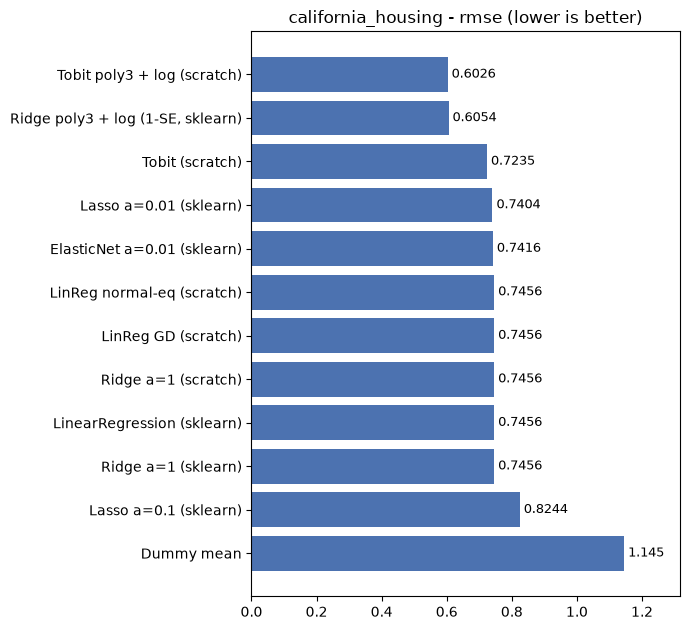

In [38]:
# 記錄成績：成績表是對「記錄值」評分，所以用 E[min(y*, 5)]
#   （μ 是真值的估計，拿去跟被壓在 5 的標籤比會吃虧，見 TODO 19 (2)）
for name, m, X, params in [
    (
        "Tobit (scratch)",
        tobit,
        X_test_s,
        {"c": C, "alpha": 0.0, "pred": "E[min(y*,c)]"},
    ),
    (
        "Tobit poly3 + log (scratch)",
        tobit_1se,
        P_test,
        {"c": C, "alpha": alpha_1se, "pred": "E[min(y*,c)]"},
    ),
]:
    metrics = regression_metrics(y_test, m.predict_observed(X))
    test_scores[name] = metrics
    log_result(BENCH, name, metrics, **params)

display(pd.DataFrame(test_scores).T)
compare(BENCH, "rmse", higher_is_better=False)

---
## 8. 本章小結

### 方法與結果

California Housing（train 16,512 / test 4,128；CV = 5-fold KFold）。

| 方法 | 求解方式 | 關鍵性質 | CV RMSE | test RMSE | test $R^2$ |
| --- | --- | --- | --- | --- | --- |
| Dummy mean | 預測訓練集平均 | RMSE = $y$ 的標準差；$R^2 \approx 0$（CV 時略小於 0） | 1.156 ± 0.012 | 1.145 | −0.000 |
| OLS（正規方程，手寫） | 解 $(X^\top X)\theta = X^\top y$ | 一步得解；$\kappa(X^\top X) = \kappa(X)^2$，病態時數值不穩 | 0.721 ± 0.014 | 0.746 | 0.576 |
| OLS（梯度下降，手寫） | $\theta \leftarrow \theta - \text{lr}\cdot\nabla\text{MSE}$ | 需 $\text{lr} < 2/\lambda_{\max}$；收斂步數 $\propto \kappa$ → 必須標準化 | — | 0.746 | 0.576 |
| Ridge $\alpha=1$ | 解 $(X^\top X + \alpha I')\theta = X^\top y$ | 墊高 $\lambda_{\min}$、穩定共線係數；不產生 0 係數 | 0.721 ± 0.014 | 0.746 | 0.576 |
| Lasso $\alpha=0.01$ | 座標下降＋soft-thresholding | 無閉式解；產生稀疏解、兼具特徵選擇 | 0.724 ± 0.013 | 0.740 | 0.582 |
| Lasso $\alpha=0.1$ | 同上 | 過度正則化：砍掉經緯度 → 欠擬合 | 0.820 ± 0.013 | 0.824 | 0.481 |
| ElasticNet $\alpha=0.01$ | 座標下降 | L1 + L2，稀疏且傾向成組保留相關特徵 | — | 0.742 | 0.580 |
| **log1p + 3 次多項式 + Ridge $\alpha=10$（1-SE）** | 長尾特徵取 log → 164 個多項式特徵 → Ridge | 容量來自特徵擴充；log 防止外插爆炸 | **0.602 ± 0.016** | **0.605** | **0.720** |
| Tobit（手寫） | MLE（L-BFGS-B）；截斷樣本的似然用 $P(y^* \ge 5)$ | 估計真實房價 $y^*$；成績用 $E[\min(y^*, 5)]$ 對記錄值評分 | — | 0.724 | 0.601 |
| Tobit + log1p + 3 次多項式 $\alpha=10$（手寫） | 同上，特徵同 1-SE | 截斷樣本平均預測 4.15 → 4.75；對記錄值的分數跟 clip 幾乎一樣 | — | 0.603 | 0.723 |

手寫版本與 sklearn 係數差異約 1e-15，驗證實作正確。

### 核心觀念

1. **最小平方法**：最小化 $\lVert Xw - y\rVert^2$，令梯度為 0 得正規方程；bias 以補一欄 1 併入 $\theta$。最小化 MSE 的預測是條件**平均**（Dummy mean 是 MSE 最小的常數；median 則是 MAE 最小的常數）。
2. **條件數 $\kappa = \lambda_{\max} / \lambda_{\min}$**
   - 直接解方程組時：誤差放大倍數（$\kappa \approx 10^k$ 約損失 $k$ 位有效數字）。
   - 梯度下降時：lr 上限由 $\lambda_{\max}$ 決定、最慢方向進度由 $\lambda_{\min}$ 決定 → 收斂步數 $\propto \kappa$。
   - 本資料：raw $\kappa \approx 5.6\times10^{10}$ → 標準化後 $\approx 43$。
   - 解方程式用 `solve` 不用 `inv`：solve 是 backward stable（殘差 $\sim\varepsilon$）、計算量約 1/3；但兩者的係數誤差都 $\sim\kappa\varepsilon$，要算得更準得避開 $X^\top X$（`lstsq`／QR）或降低 $\kappa$。
3. **標準化**：不改變 OLS 的預測值（係數依 $w_\text{scaled} = w_\text{raw}\cdot\sigma$ 換算），但大幅改善條件數；對 Ridge／Lasso 則是必要條件，否則懲罰對不同單位的特徵不公平。標準化**不改變分布形狀**，處理不了長尾。
4. **共線性**：使多元回歸係數不穩定、可與單變量相關係數反號（AveRooms／AveBedrms）。Ridge 傾向讓共線特徵平均分攤權重；Lasso 傾向只保留其中一個。
5. **L1 vs L2**：L1 在 0 不可微 → 無閉式解、但能把係數壓成恰為 0；L2 可微 → 閉式解、只縮小不歸零。
6. **sklearn 的 $\alpha$ 定義不一致**：Ridge 為 $\lVert y - Xw\rVert^2 + \alpha\lVert w\rVert_2^2$，Lasso 為 $\frac{1}{2n}\lVert y - Xw\rVert^2 + \alpha\lVert w\rVert_1$，兩者 $\alpha$ 不可直接比較；用交叉驗證選。
7. **$R^2$ 與 RMSE**：$R^2 = 1 - \text{SSE}/\text{SST}$ =「比永遠猜平均好多少」，可以是負的；RMSE 對大誤差敏感（平方），MAE 不敏感。兩者結論不同時，代表誤差被少數樣本主導。
8. **欠擬合時正則化沒用**：$n = 16{,}512$、只有 9 個參數 → 變異本來就接近 0，validation curve 是水平線；要改善得**增加容量**（多項式特徵），容量大了（164 個特徵）正則化才開始有用（$\alpha = 10$ 最佳）。
9. **外插與長尾特徵**：線性與多項式模型對 $x$ 沒有上限，極端值（AveOccup 1,243 是 p99 的 230 倍）在 $x^2$、$x^3$ 下被放大成災難性預測（240 vs 真值 1.4）；只在某些 fold 爆 → CV 標準差 > 平均。log1p 保留順序、壓縮尺度，是比加大 $\alpha$ 更對症的處理（前處理也是超參數）。
10. **學習曲線**：train $\approx$ val 且都平 → 高偏差，加資料沒用；小樣本時極端值沒被涵蓋，連線性模型都會外插失敗。
11. **診斷要分清 x 側與 y 側的問題**：非線性、長尾特徵可以靠特徵工程修；標籤截斷（斜率 −1 的殘差線、系統性低估）與異質變異（扇形）在 y 側，換特徵修不了。
12. **截斷（censoring）要當不等式用**：$y = 5$ 的意思是 $y^* \ge 5$。照常訓練會低估；刪除截斷樣本 = 依 $y$ 篩選樣本，一樣低估（評估時只看非截斷樣本也會偏）。Tobit 把截斷樣本的似然換成 $P(y^* \ge c)$：模擬中完全還原真值，人工截斷實驗追回七到八成差距；但依賴常態、同質變異假設，也修不了模型本身的偏差。只想預測記錄值時，clip 到上限就拿到幾乎全部的分數改善。

### 待補強（之後回來可以學）

**統計推論面（本章偏重預測，未涉及）**
- ☐ OLS 的統計假設（線性、獨立、同質變異、常態誤差）與 Gauss-Markov 定理（BLUE）
- ☐ 係數的標準誤、t 檢定、信賴區間；用 `statsmodels.OLS` 看 summary 表
- ☐ 異質變異的檢定（Breusch-Pagan）與穩健標準誤（HC0–HC3）
- ☐ 多重共線性的量化：VIF（variance inflation factor）
- ☐ 最小平方法 = 高斯誤差下的最大概似估計（MLE）；Ridge／Lasso = 高斯／Laplace 先驗下的 MAP

**數值與最佳化**
- ☐ 用 QR 分解或 SVD（`np.linalg.lstsq`）解最小平方，避免條件數平方；偽逆（pseudo-inverse）
- ☐ 隨機梯度下降（SGD）與 mini-batch：大資料下的做法，以及學習率排程
- ☐ 動量（Momentum）、Adam 如何緩解病態條件數（銜接第二章神經網路）
- ☐ 手寫座標下降 Lasso（soft-thresholding）；LARS 與 Lasso 路徑

**模型與特徵**
- ✅ 用交叉驗證選 $\alpha$ 並畫驗證曲線（第 5 節）
- ✅ 偏差—變異權衡：用 $\alpha$ 與多項式次數觀察欠擬合／過擬合（第 5 節）
- ✅ 長尾特徵取 log、多項式特徵（第 5 節：test $R^2$ 0.576 → 0.720）
- ☐ 對 y 取 log（`TransformedTargetRegressor`）處理異質變異與負房價；注意 log 空間的預測要轉回原空間時的偏差（smearing）
- ☐ 經緯度的特徵工程：分群（K-Means，第 13 章）、到海岸／大城市的距離、RBF 特徵
- ✅ 截斷資料的處理：移除 y = 5 樣本的影響、Tobit 回歸（第 7B 節）
- ☐ 截斷資料的延伸：對 $\log y$ 做 Tobit（= LogNormal AFT，`lifelines`）、讓 $\sigma$ 隨 $x$ 變的異質變異 Tobit、CLAD（截斷版的分位數回歸）、XGBoost `survival:aft`（區間標籤）
- ☐ 穩健回歸：Huber、RANSAC（對極端值較不敏感）；quantile regression（預測條件中位數或分位數）
- ☐ 廣義線性模型（GLM）：Poisson、Gamma 回歸，處理正值或計數型目標
- ☐ 極端值造成的 fold 間變異：用 `RepeatedKFold` 評估 CV 分數本身有多穩定
